> **Recommended: run this notebook in Google Colab, nothing to install.**
>
> [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/workshop/02-understand-navigate.ipynb)
>
> Just click on the "Open in Colab" button and follow along. Click the ▶ button on each cell (or press Shift+Enter) to see the results and move on to the next one.
>
> The documentation website shows pre-run results you can check if you don't want to or can't use Colab.

# Session 2: Understand Navigate

The aim of this section is to cover the basics of Navigate's logic using a simple, though useful, case as an illustration.

[Session 1](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/workshop/01-run-a-simple-case.ipynb) introduced the case, ran it and let you move its input data. This session looks inside it: how the deck is built, the data behind it, how the model solves it step by step, and its results in detail.


![Map of the Chile to Rotterdam copper trade: the two bunker ports, a fleet of ships on the voyage via the Panama Canal, and the fuel production sites in Patagonia and southern Sweden, both of which make e-methanol and e-ammonia, with bio-methanol in Sweden as well](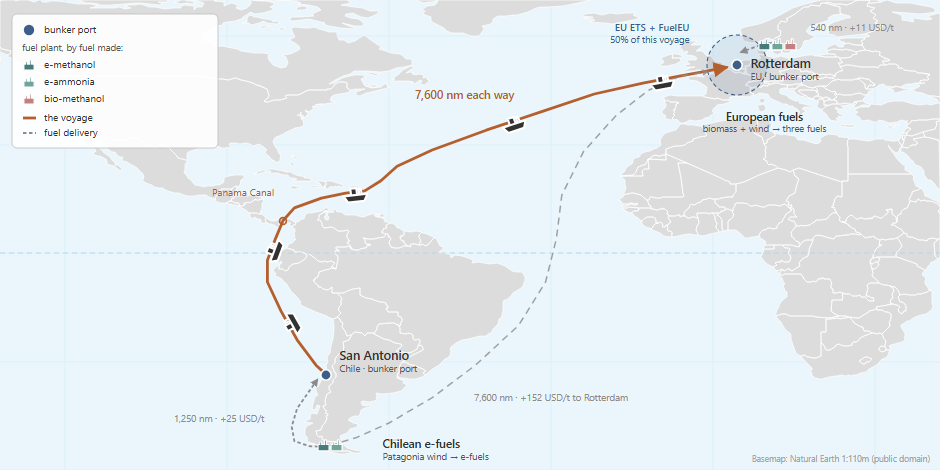)

*San Antonio to Rotterdam via the Panama Canal: the two bunker ports, the
voyage, and the possible fuel plants.*

## What you'll do

**Part 1: Build the deck.** See how a case like this is expressed using Navigate's components library.

**Part 2: Explore the input data.** Look at the numerical assumptions that will drive the answer.

**Part 3: Understand the logic behind the model.** Understand how Navigate decides, for the shipowners and operators and for the fuel producers, and see the results it produces.

**Part 4: How much behaviour matters.** Change how sharply the fleet and plant owners decide and see what it does to the results.


## Setup

Run the cell below on Colab or locally to set up the Navigate model. It also loads the pre-made example that will be used to illustrate this part of the workshop.

In [1]:
# @title Setup
# Setup. Works both on Google Colab and in a local checkout of the repository.
import os
from pathlib import Path


# The branch these notebooks live on, and the one Colab clones. The "Open in
# Colab" badge at the top of the notebook, like the links between the
# notebooks, opens the copy on the workshop-colab branch instead: the same
# notebooks with their outputs cleared, rebuilt from this branch by
# .github/workflows/workshop-colab.yml. Change BRANCH, and that workflow, to
# "main" once the branch has been merged.
BRANCH = "dev-workshop"


def at_repo_root() -> bool:
    """True if the working directory is the root of the repository."""
    return Path("navigate").is_dir() and Path("assumptions").is_dir()


if at_repo_root():
    print("Already at the repository root.")
elif Path("../../navigate").is_dir():
    # Local Jupyter starts the kernel in the notebook's own folder,
    # docs/workshop/, but the paths below are relative to the repository root.
    os.chdir("../..")
    print("Moved up to the repository root.")
else:
    # Colab, or any other fresh environment
    if not Path("navigate-zcs").is_dir():
        !git clone --depth 1 -b {BRANCH} https://github.com/zerocarbonshipping/navigate-zcs.git
    os.chdir("navigate-zcs")
    print("Cloned the repository and moved into it.")

assert at_repo_root(), f"not at the repository root: {Path.cwd()}"

# `import navigate` is not a usable test here: from the repository root it
# succeeds because the source folder is present, which leaves the `navigate`
# command itself missing.
import sys
from importlib.metadata import PackageNotFoundError, version

try:
    print(f"Navigate {version('navigate-zcs')} is already installed.")
except PackageNotFoundError:
    %pip install -q .
    print("Installed Navigate.")


# Load the example deck.
EXAMPLE = Path("simulations/examples/example_4")

# Fail loudly rather than printing an empty list. The setup above clones the
# branch named in BRANCH, so this deck is only here once it has been committed
# and pushed to that branch.
assert EXAMPLE.is_dir(), (
    f"{EXAMPLE} not found under {Path.cwd()}. On Colab the setup cell clones the "
    f"{BRANCH!r} branch, so this deck has to be committed and pushed there "
    "before the notebook can read it."
)


def show(path, first=None, grep=None, code_only=False):
    """Print a deck file: all of it, the first N lines, matching lines, or the
    command lines only (`code_only`, which drops the comments)."""
    lines = Path(path).read_text(encoding="utf-8").splitlines()
    if code_only:
        print(f"# {Path(path).name}: command lines only, "
              f"open the file for the commentary")
        lines = [ln for ln in lines if ln.strip() and not ln.strip().startswith("#")]
    if grep:
        lines = [ln for ln in lines if grep in ln]
    if first:
        lines = lines[:first]
    for ln in lines:
        print(ln)


deck = sorted(EXAMPLE.rglob("*.nav")) + sorted(EXAMPLE.rglob("*.inc"))
assert deck, f"no .nav or .inc files under {EXAMPLE.resolve()}"

Moved up to the repository root.
Navigate 1.0.0 is already installed.


---

## Part 1: Build the deck

Navigate is a bit like a "drag and drop" model: you pick some components (*nodes*) from the ones available and add them to your simulation (*deck*).

A **deck** is the input to a Navigate run: one `.nav` file plus the `.inc` files it includes. Navigate is the program, and the deck is the instructions you hand it. A **node** is one declared thing, written as a type, a name in quotes, and a block of attributes.

The `.nav` file is just a table of contents with two sections —
`DEFINE` for the nodes the simulation is made of, and `EVENTS` for the timeline
it steps through.

`Include` adds a deck's files, by its path. `Load` adds a ready-made module from the Center's assumptions library, by its name.

Check the [Reference Manual](https://zerocarbonshipping.github.io/navigate-zcs/reference_manual/index.html) and follow the [Tutorials](https://zerocarbonshipping.github.io/navigate-zcs/tutorials/index.html) if you want more details on this.

Read the `.nav` file first, to see how the deck is built for the current case.

In [2]:
show(EXAMPLE / "example_4.nav")

# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# EXAMPLE 4 - Panamax fleet, Chile to Rotterdam.

DEFINE {
    Load DefaultModelDefinition

    # ---- fleet ----
    Include "includes/fleet.inc"
    Include "includes/energy_efficiencies.inc"

    # ---- route ----
    Include "includes/route.inc"
    Include "includes/ports.inc"
    Include "includes/bunker_logistics.inc"

    # ---- fuel ----
    Include "includes/fuel_production.inc"
    Include "includes/regions.inc"
    Include "includes/producer.inc"
    Load DefaultEmission

    # ---- regulation ----
    Include "includes/eu_ets.inc"
    Include "includes/fuel_eu.inc"

    # ---- decision processes ----
    Load DefaultCalibration

    # ---- export ----
    Include "includes/report.inc"

    Load DefaultPlot
}

EVENTS {
    Load DefaultTimeStepYearly
}


### Fleet definition

In our case, the fleet starts as 300 fuel-oil vessels set with `InitialVessels` and `InitialSplit`. 
`InitialAgeDistribution` is the age spread of the world's 80k DWT bulk carriers, taken from the library as `Curve("age_dist_bulk_carrier_80k_dwt_oil")`. Navigate splits the fleet into one cohort per year of age, and the retrofit decision will be taken **per cohort**.

Two mechanisms will compete over the next 25 years:

- **Retrofit** — convert an existing oil ship to methanol or ammonia. An LNG ship can only be bought new, and can itself be retrofitted to ammonia. The `set_fuel_conversion_cost` lines
put a price on retrofitting an existing oil ship to another configuration.
- **Replace** — do nothing until a cohort retires, then let all four
  configurations compete as newbuilds.

Run next cell to look in more details, how the "fleet" is implemented in Navigate.

In [3]:
show(EXAMPLE / "includes/fleet.inc")

# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# FLEET - Panamax bulk carriers (~80,000 DWT), four configurations of one hull.
# All four share hull, propulsion curve, cargo capacity and OPEX.

Copy Vessel "bulk_carrier_80k_dwt_ice_oil"      "ship_oil"
Copy Vessel "bulk_carrier_80k_dwt_ice_methane"  "ship_lng"
Copy Vessel "bulk_carrier_80k_dwt_ice_methanol" "ship_methanol"
Copy Vessel "bulk_carrier_80k_dwt_ice_ammonia"  "ship_ammonia"

Fleet "copper_trade" {
	Vessels = [Vessel("ship_oil"),
	           Vessel("ship_lng"),
	           Vessel("ship_methanol"),
	           Vessel("ship_ammonia")]

	InitialVessels = 300 # Arbitrary number (represents 8% of the world Panamax fleet)
	InitialSplit = [1.0, 0.0, 0.0, 0.0] # Only ship oil vessels

	InitialAgeDistribution = [
		Curve("age_dist_bulk_carrier_80k_dwt_oil"),
		0,
		0,
		0
	]
	# Note: Orderbooks omitted for this example since the library's are sized for

#### What a `Vessel` node looks like

`fleet.inc` never describes the ships themselves. It reaches for them with
`Copy Vessel`, which takes a vessel out of our assumptions library and gives
the copy a local name — so `ship_oil` is a copy of
`bulk_carrier_80k_dwt_ice_oil`.

Run the next cell to check what goes into a vessel node.

In [4]:
# fleet.inc reaches these four with `Copy Vessel`. Here is one of them.
VESSEL_DIR = Path("assumptions/defaults/installation/Vessel")
show(VESSEL_DIR / "bulk_carrier_80k_dwt_ice_oil.inc")

# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

Vessel "bulk_carrier_80k_dwt_ice_oil" {
	
	PropulsionLoad = Surface("bulk_carrier_80k_dwt_propulsion_load")
	ElectricalLoadAtSea = Variable("bulk_carrier_80k_dwt_electrical_load_sea")
	ElectricalLoadInPort = Variable("bulk_carrier_80k_dwt_electrical_load_port")
	HeatLoadAtSea = Variable("bulk_carrier_80k_dwt_heat_load_sea")
	HeatLoadInPort = Variable("bulk_carrier_80k_dwt_heat_load_port")
	
	PowerSystem = PowerSystem("ice_oil_bulk_carrier_80k_dwt")
	Tanks = [Tank("main_oil_bulk_carrier_80k_dwt")]
	
	Route = Route("operational_profile_bulk_carrier_80k_dwt")
	NominalCapacity = Variable("bulk_carrier_80k_dwt_nominal_capacity")
	Lifetime = Variable("bulk_carrier_80k_dwt_lifetime")
	
	CAPEX = Forecast("bulk_carrier_80k_dwt_capex")
	OPEX = Forecast("bulk_carrier_80k_dwt_opex")
	CostOfCapital = Variable("cost_of_capital_vessel")
}


### Route definition

In this example, the ships sail between the ports of San Antonio and Rotterdam, 7,600 nm apart via the Panama Canal (the route is invented), at a service speed of 11.5 kn and spends 6.8 days on each port.

The two legs (one leg is a one way ship travel) are asymmetric in this example. Outbound the ship is full of copper concentrate; homebound it sails in ballast (empty). In the model, this can be set as `CapacityUtilizations = [1.0, 0.0]`.

In [5]:
show(EXAMPLE / "includes/route.inc")

# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# ROUTE - San Antonio to Rotterdam and back via the Panama Canal.
# ROUND_TRIP visits the ports in the order listed; each entry in
# Distances/Speeds/CapacityUtilizations is the leg leaving the port at that index.

Vessel "ship_*" {
    Route = Route("copper_route")
}

Route "copper_route" {
    RouteType = ROUND_TRIP

    Ports = [Port("san_antonio"), Port("rotterdam")]

    # Days alongside per call, from the library's operational profile for this
    # class: TimeAtSea 0.55 over 24 calls/year = 0.45 x 365 / 24.
    PortDurations = [6.8, 6.8]

    # The distances for this example are invented since this route geography
    # is not included in the Navigate Assumption.
    Distances = [7600, 7600]

    # Modal service speed from the library's operational profile for this ship class.
    Speeds = [11.5, 11.5]

    # Laden out, ballast home.
    CapacityUtil

### Ports definition
In this example, we assume that both ports sell the same five fuels: fuel oil, LNG, e-ammonia, e-methanol and bio-methanol. Fuel is shipped from the region that made it to the port that needs it, at a given transport cost, function of the distance it travelled.


In [6]:
show(EXAMPLE / "includes/ports.inc")

# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# PORTS - what can be bunkered where. All three alternative fuels are bunkerable at
# both ports; a fuel is shipped to the port that did not produce it, the same way
# Chilean e-ammonia reaches Rotterdam.
# Delivered price is production cost plus transport, set in bunker_logistics.inc.

Port "san_antonio" {
    set_bunkering_allowed("methanol_electro", TRUE)
    set_bunkering_allowed("ammonia_electro", TRUE)
    set_bunkering_allowed("methanol_bio", TRUE)
}

Port "rotterdam" {
    set_bunkering_allowed("methanol_electro", TRUE)
    set_bunkering_allowed("ammonia_electro", TRUE)
    set_bunkering_allowed("methanol_bio", TRUE)
}

Port "*" {
    # the two fossil fuels are treated as globally traded and available anywhere
    set_bunkering_allowed("fossil_fuel_oil", TRUE)
    set_bunkering_allowed("liquefied_natural_gas", TRUE)

    # Fossil prices and upstream

### Fuel production

Five fuels are considered in this model: oil, LNG, e-ammonia, e-methanol and bio-methanol.
A vessel is defined by the fuel **type** its engine and tanks accept, and several fuels can satisfy one type. For example, the same methanol ship can accept bio-methanol, e-methanol or oil (dual-fuel engine).

E-ammonia, e-methanol and bio-methanol need to be produced by a fuel plant. 

In [7]:
show(EXAMPLE / "includes/fuel_production.inc")

# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# FUEL PRODUCTION - five fuels for four ships; both methanols feed one ship.
#
# Only the siting and financing are set here (region, electricity source and
# cost of capital, which Import Plant does not bring: the library sets it in
# DefaultPlant). Lead times, lifetimes, capacities and process economics come
# from the library.
# Feedstock ceilings for the two methanols are set in producer.inc.

# ---- fossil (global commodities, no production chain modelled) --------------
Import Fuel "fossil_fuel_oil"
Import Fuel "liquefied_natural_gas"

# ---- Chilean e-methanol -----------------------------------------------------
Import Fuel "methanol_electro"
Import Plant "plant_methanol_electro_alkaline"
Plant "plant_methanol_electro_alkaline" {
    Region = Region("americas")
    Source = Source("renewable")   # dedicated wind, not the Chilean grid
    CostOfCapita

A **producer** is the agent that decides whether to build fuel plants or not and which ones. 

We have two producers in this model: an e-fuel producer that can build e-ammonia and e-methanol in either Patagonia or Europe, and a biofuel producer that builds bio-methanol (only in Europe).

The feedstocks for bio-methanol (biomass) and e-methanol (biogenic CO2) are constrained (using an arbitrary number in this simulation) meaning that plant build is limited for these two fuels. 

In the model it is also possible to constrain the number of fuel plants that can be built in a year (but it will not be binding for our example).

In [8]:

show(EXAMPLE / "includes/producer.inc")

# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# PRODUCERS - the agents that decide whether to build another plant.

Producer "producer_efuel" {
	Plants = [Plant("plant_methanol_electro_alkaline"),
	          Plant("plant_ammonia_electro_alkaline"),
	          Plant("plant_methanol_electro_alkaline_europe"),
	          Plant("plant_ammonia_electro_alkaline_europe")]

	MaximumDevelopment = <Forecast("epc_global_capacity_mid") * Forecast("epc_global_share_shipping")>

	# Ceiling on biogenic CO2, the feedstock both its e-methanol plants draw on.

	set_feed_constraint("carbon_dioxide_biogenic", <Forecast("carbon_dioxide_biogenic_availability") * Forecast("carbon_dioxide_biogenic_share_shipping") * Variable("trade_share_biogenic_carbon_dioxide")>)
}

Producer "producer_biofuel" {
	Plants = [Plant("plant_methanol_bio_gasification")]

	MaximumDevelopment = <Forecast("epc_global_capacity_mid") * Forecast("epc_g

### Implement bunker logistics

`LiquidMarketFuels` such as fuel oil and LNG are treated as global commodities:
available anywhere at a quoted price, with no plant, producer or logistics chain
modelled.

Everything else has to be physically moved from the plant to the bunker port,
priced at `distance × rate`. `set_distance` gives the sea distance from a
production region to a port, and `set_transport_cost` the rate per ton per
nautical mile.

At the port, `set_handling_cost` (in the ports file above) adds a fixed cost per ton
for storage and the bunkering service. These per-ton charges are the only
infrastructure costs in Navigate: terminals, storage tanks and bunker vessels have
no investment cost and are never built. A slow or costly port build-out has to be
entered by hand: `set_bunkering_allowed` or `set_bunkering_limit` for when and how
much a port can deliver, and a higher or time-varying handling cost for what it costs.

In [9]:
show(EXAMPLE / "includes/bunker_logistics.inc")

# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# BUNKER LOGISTICS - production site to bunker port.
# LiquidMarketFuels are treated as global commodities: quoted price, no plant,
# no producer, no logistics chain. Everything else picks up distance x rate.

BunkerLogistics {
	LiquidMarketFuels = [Fuel("fossil_fuel_oil"), Fuel("liquefied_natural_gas")]

	# The values have been invented for this example:
	# nautical miles from the production region to each port
	set_distance("americas", "san_antonio", 1250)
	set_distance("americas", "rotterdam", 7600)
	set_distance("europe", "rotterdam", 540)
	set_distance("europe", "san_antonio", 7600)

	# USD per ton per nautical mile
	set_transport_cost("*", 0.02)
}


### Implement regulations (FuelEU and EU ETS)

![The EU regulatory package: the Renewable Energy Directive sets emissions values, sustainability criteria, GHG emission savings and certification; FuelEU Maritime limits the GHG intensity of fuel on a declining staircase to 2050, with penalties paid for emissions above the annual target and pooling rewarding vessels below it; and the EU Emissions Trading System puts a price on every tonne of GHGs, with ships buying EU Allowances](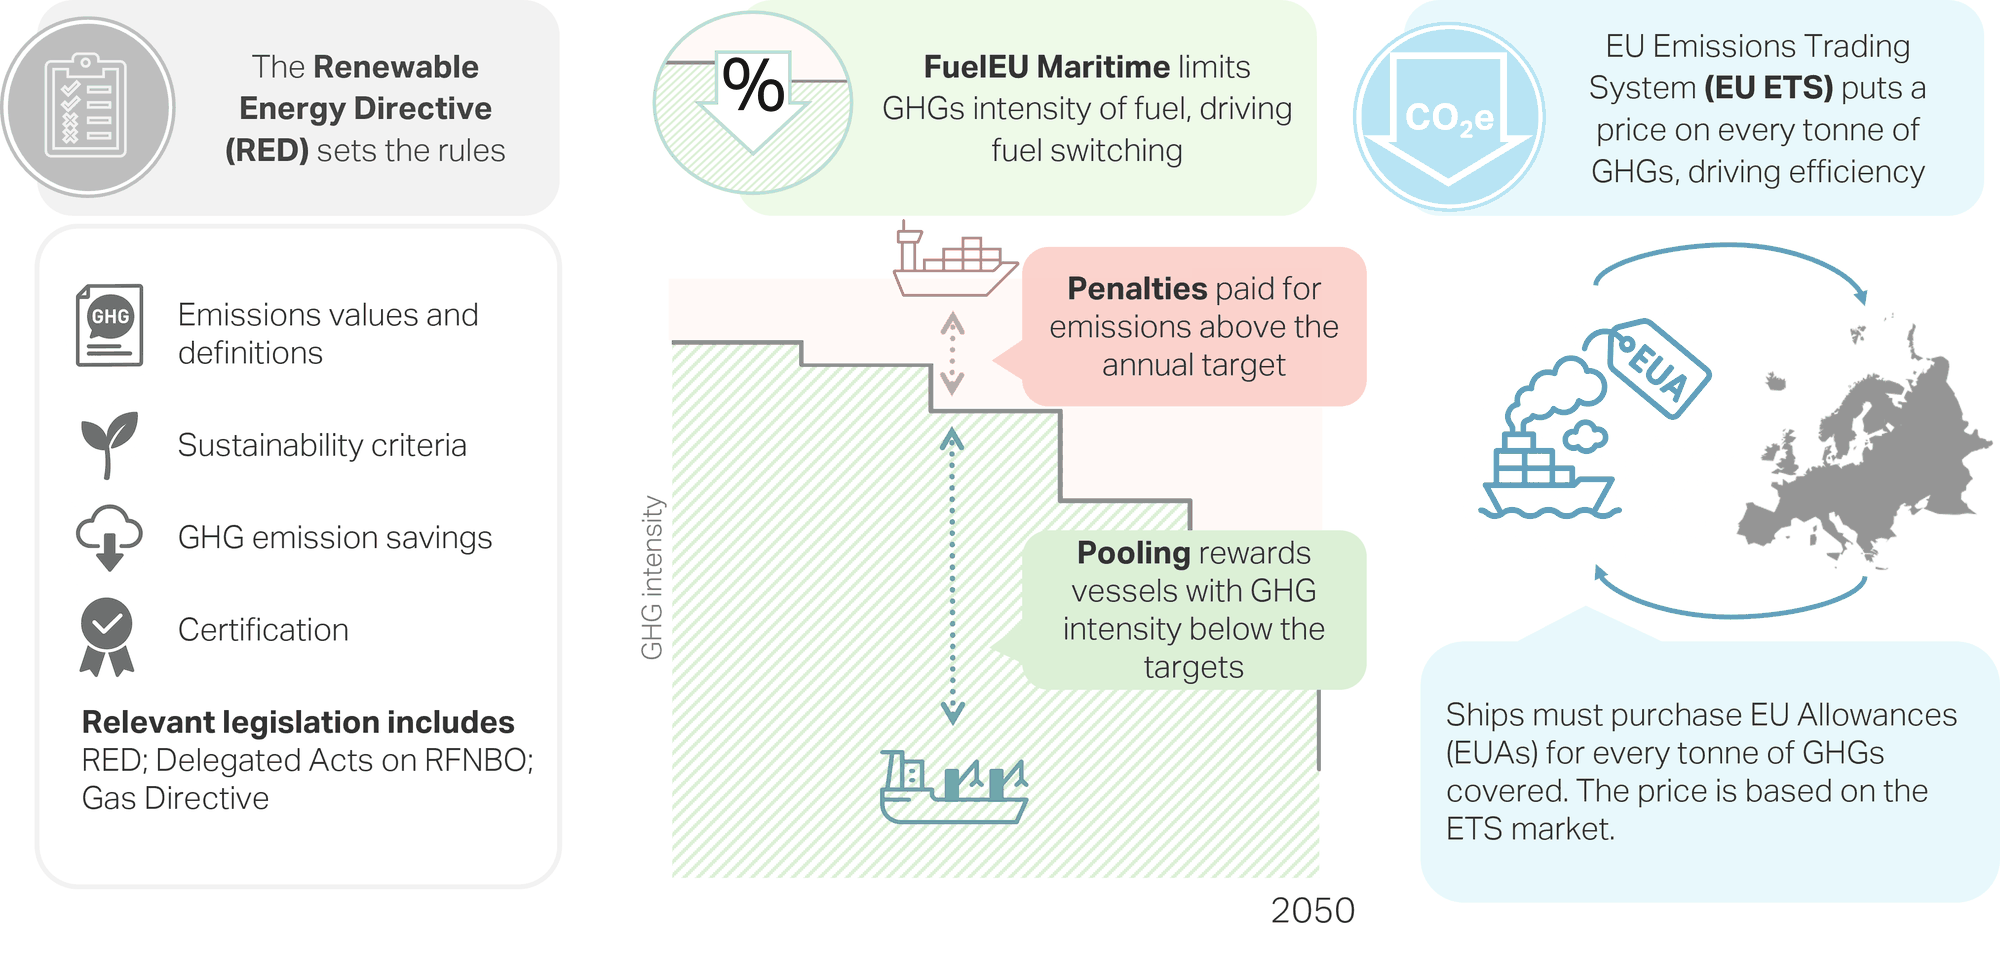)

*FuelEU Maritime caps the GHG **intensity** of the fuel and so drives fuel switching; the EU ETS prices **every tonne** emitted and so drives efficiency. The Renewable Energy Directive supplies the definitions and certification both rely on.*

In Navigate a regulation is applied to a specific geography. `Jurisdiction` lists the
ports that sit inside the regulatory scheme. In this example, FuelEU and EU ETS cover the port of Rotterdam, but not San Antonio. Three fractions decide how much of the fuel burned on a voyage is counted.

The fractions are applied leg by leg. In Navigate, a *leg*
is one port-to-port sailing between two consecutive ports on the route. This
round trip has two, out and back. Navigate reserves the word for the ship's own
route segments, so a fuel's journey from plant to bunker port is a *trip*, not a
leg. Navigate classifies each leg by its two end ports, and the port stay. On this round trip that gives:

| Leg or port stay | Classification | Counted for regulation |
|---|---|---|
| San Antonio → Rotterdam, 7,600 nm ≈ 27.5 days | one end inside → `InterFraction` | **50 %** |
| Rotterdam → San Antonio, 7,600 nm ≈ 27.5 days | one end inside → `InterFraction` | **50 %** |
| alongside in Rotterdam, 6.8 days per call | inside → `IntraFraction` | **100 %** |
| alongside in San Antonio, 6.8 days per call | outside → `ExtraFraction` | 0 % |

The two instruments apply to different emission scopes:

- EU ETS on **TTW — tank to wake.** Emissions that come out of the ship engine.
- FuelEU on **WTW — well to wake.** TTW, plus emissions to make and deliver the
  fuel.

Each instrument is one `Regulation` node, and the `.nav` includes one file per
instrument — `includes/eu_ets.inc` and `includes/fuel_eu.inc`.

Beyond the geography, most of the content is **emission factors**: a
`set_fuel_ttw` line per fuel per gas, saying what a ton of that fuel emits once
burned. FuelEU adds `set_fuel_wtt` lines for the fuels whose upstream value the
regulation fixes by default.
E-fuels are omitted since there are no default factors. Upstream intensity is then calculated by Navigate from the production chain in `regions.inc`.

In [10]:
show(EXAMPLE / "includes/eu_ets.inc")

# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# EU ETS - absolute price on CO2-equivalent burned on board, no free allowance.
#
# The coverage fractions are applied PER LEG, not to the round trip. Both legs
# here are inter-jurisdiction, so both count at 50%. Port stays are classified
# by their own port, so Rotterdam counts in full and San Antonio not at all.

Regulation "eu_ets" {
	Measure = ABSOLUTE
	Scheme = INDIVIDUAL
	Scope = TTW
	IncludeSlip = FALSE   # methane slip is carried in the TTW methane factors
	Emissions = [Emission("carbon_dioxide"), Emission("methane"), Emission("nitrous_oxide")]
	Fuels = Fuel("*")

	# Rotterdam is the only EU port on this route
	Jurisdiction = [Port("rotterdam")]
	IntraFraction = 1     # both ends in the EU
	InterFraction = 0.5   # one end in the EU
	ExtraFraction = 0     # neither end in the EU

	RemedialCost = <Forecast("eu_ets_carbon_credit_price") * Forecast("eu

FuelEU is the same shape, with two differences to look for: `Scheme = FLEXIBLE` (applies for the fleet) instead of `INDIVIDUAL` (applies per vessel), and the `set_fuel_wtt` lines that fix upstream intensity for the fossil fuels and bio-methanol — but not for the two e-fuels.

In [11]:
show(EXAMPLE / "includes/fuel_eu.inc")

# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# FUELEU MARITIME - caps WTW greenhouse gas intensity, tightening over time.
#
# The e-fuels get no default set_fuel_wtt. Instead, Navigate calculates
# their upstream intensity from the production chain in regions.inc, so the
# power price at each site feeds their FuelEU score. The fossil fuels and
# bio-methanol instead use the regulation's own defaults.
#
# Same coverage geography as eu_ets.inc.

Regulation "fuel_eu" {
	Measure = INTENSITY
	Scheme = FLEXIBLE     # pooled and banked across years, unlike the ETS
	Scope = WTW
	IncludeSlip = FALSE   # methane slip is carried in the TTW methane factors
	Emissions = [Emission("carbon_dioxide"), Emission("methane"), Emission("nitrous_oxide")]
	Fuels = Fuel("*")

	Jurisdiction = [Port("rotterdam")]
	IntraFraction = 1
	InterFraction = 0.5
	ExtraFraction = 0

	RemedialCost = Variable("fuel_eu_remedial_cost")

	Sha

#### In summary

| | FuelEU Maritime | EU ETS |
|---|---|---|
| What it limits | the **intensity** of the energy used, gCO2eq/MJ | the **quantity** emitted, tonnes CO2eq |
| What you pay | a penalty on how far you miss the annual target | a price on every covered tonne |
| Emissions counted | **well-to-wake**: how the fuel was made counts | **tank-to-wake**: only what the ship burns on board |

For FuelEU, the limit is a **staircase**: it holds flat for years and then
steps down, so the pressure to switch arrives in jumps rather than smoothly.


---

## Part 2: Explore the input data

Before running the model, let's look at the numbers behind it since they
explain most of the results.

Navigate fetches numerical assumptions from the assumptions library as it reads the deck.


### Numerical assumptions in Navigate

Almost every numerical assumption in Navigate is a **lookup table** written into a `.inc`
file: when the model needs a value it reads one out of the table. Five node types carry the numbers:

| Node | Look up table by | Example |
|---|---|---|
| `Variable` | nothing — it is a single number | `fuel_eu_remedial_cost`: **760 USD/ton CO2eq** of shortfall |
| `Curve` | one number | `age_dist_bulk_carrier_80k_dwt_oil`: at age 12, **10.6 %** of the fleet |
| `Forecast` | a date | `eu_ets_carbon_credit_price`: in 2050, **417 USD/ton CO2eq** |
| `Surface` | two numbers | `bulk_carrier_80k_dwt_propulsion_load`: at 11.5 kn and utilisation 1 (full), **4.82 MW** |
| `Timetable` | a date *and* a number | `methanol_synthesis_electro_capex`: in 2025, a 4,000 t/day plant costs **558 USD/(ton of annual capacity)** |

The Center has collected a wide range of these numbers from partners and external
sources, and they have been validated by experts. They can all be found in the
`assumptions` folder.

That folder holds an `installation` and a `user` copy.
`defaults/` holds individual nodes, one folder per type, and is read whenever a deck names
one: `Import Fuel "methanol_bio"` picks up
`defaults/installation/Fuel/methanol_bio.inc`. 

`modules/` holds ready-made bundles invoked with `Load`: `Load DefaultRegulation` reads
`modules/installation/default_regulation.inc`, which is itself just a short list of
imports. 

In both cases Navigate looks in `user/` first and falls back to
`installation/`, so you can use your own numbers by dropping a file into the
matching `user/` folder under the same name. It then takes precedence over the
Center's values.

See the reference manual for
[Forecast](https://zerocarbonshipping.github.io/navigate-zcs/reference_manual/forecast.html),
[Curve](https://zerocarbonshipping.github.io/navigate-zcs/reference_manual/curve.html),
[Surface](https://zerocarbonshipping.github.io/navigate-zcs/reference_manual/surface.html),
[Timetable](https://zerocarbonshipping.github.io/navigate-zcs/reference_manual/timetable.html)
and
[Variable](https://zerocarbonshipping.github.io/navigate-zcs/reference_manual/variable.html)
if you want more details.


The next cell needs to be run to prepare the data extraction from Navigate.


In [12]:
# @title Parse the deck and solve it once
import argparse
import contextlib
import io
import os
from pathlib import Path

import numpy as np
import pandas as pd
from navigate.bunker.bunker_algorithm import BunkerAlgorithm
from navigate.core.enum_ import BunkerScopeID
from navigate.core.expectations.vessel_expectation import VesselExpectation
from navigate.fuel.producer import producer_planning
from navigate.vessel.fleet import fleet_technology
from navigate.manager import SimulationManager

# The Setup cell at the top normally moves us to the repository root. Repeat the
# check here so this Part also works on its own, e.g. after a kernel restart.
if not (Path("navigate").is_dir() and Path("assumptions").is_dir()):
    if Path("../../navigate").is_dir():
        os.chdir("../..")
assert Path("assumptions").is_dir(), (
    f"not at the repository root ({Path.cwd()}) -- run the Setup cell at the "
    "top of the notebook first"
)

NAV = Path("simulations/examples/example_4/example_4.nav")
ARGS = argparse.Namespace(data_dir=Path("./assumptions"), solver=None)

# Parse the deck, then solve it once. Part 2 is mostly about inputs, but the
# fuels' well-to-tank emissions are not an input at all -- Navigate derives them
# from the production chain -- so the run is what makes them readable. Every later
# cell in this Part reads its numbers off `manager`; Part 3 builds its own.
manager = SimulationManager()
manager.read_deck(NAV, ARGS)

# Copy the Regulation's emission factors before the run, so the charts in this Part
# can show what the DECK states and never something the run derived. A factor the deck
# leaves out stays None here, which is exactly how the model reads it: supplied factors
# are used as given, omitted ones are derived from the fuel and the converter.
DECK_FACTORS = {name: {"gwp": dict(reg.global_warming_potential),
                       "ttw": dict(reg.fuel_TTW),
                       "wtt": dict(reg.fuel_WTT)}
                for name, reg in manager.nodes.regulations.items()}

with contextlib.redirect_stdout(io.StringIO()):   # one line per year, not needed here
    manager.run()

import matplotlib.pyplot as plt


def forecast_to_frame(name, nodes=None):
    """A Forecast node's resolved (date, value) table as a DataFrame."""
    node = (nodes or manager.nodes).forecasts[name]
    return pd.DataFrame({"date": pd.to_datetime(node.get_x_date()),
                         "value": [node.calculate(x) for x in node.get_x()]})


def forecast_curve(name, points=600):
    """What the model actually returns for a Forecast, sampled densely.

    Joining the table rows with straight lines would imply linear interpolation.
    `fuel_eu_target_reduction` sets `Interpolate = PREVIOUS`, so it holds each
    value flat and then steps down. Sampling calculate() draws whatever the node
    really does, whichever mode it uses.
    """
    node = manager.nodes.forecasts[name]
    xs = np.asarray(node.get_x(), dtype=float)
    rows = pd.to_datetime(node.get_x_date())
    grid = np.linspace(xs.min(), xs.max(), points)
    when = rows[0] + pd.to_timedelta(grid - xs[0], unit="D")
    return when, np.array([node.calculate(x) for x in grid])


# One house style for every figure in the workshop. It lives in
# docs/workshop/_style.py rather than in this cell, so that this notebook and
# notebook 4 cannot drift apart - which is exactly what had happened. The
# colours are Navigate's own, and that file explains the one thing about them
# that surprises people: the hue says how a fuel was MADE, not which molecule it
# is, so bio-methanol and e-methanol are deliberately different colours.
import sys

_STYLE_DIR = str(Path("docs/workshop").resolve())
if _STYLE_DIR not in sys.path:
    sys.path.insert(0, _STYLE_DIR)

from _style import (AXIS, BLUE, GREEN, GRID, INK, MUTED, ORANGE, PALE, SUBINK,
                    TICK, config_colour, config_label, cost_colour, fuel_colour,
                    fuel_label, fuel_sorted, series_colours)


def panel(ax, series, title, ylab):
    """One forecast panel: the model's own response, with its table rows marked."""
    for (name, label), colour in zip(series, (BLUE, ORANGE)):
        when, value = forecast_curve(name)
        ax.plot(when, value, color=colour, lw=2, label=label, zorder=3)
        rows = forecast_to_frame(name)
        if len(rows) <= 8:          # mark the rows only where they are readable
            ax.plot(rows["date"], rows["value"], "o", color=colour, ms=5,
                    mec="white", mew=1.2, zorder=4)
    ax.set_title(title, fontsize=10, color=INK, loc="left")
    ax.set_ylabel(ylab, fontsize=8, color=SUBINK)
    ax.grid(color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TICK, labelsize=8)
    ax.margins(y=0.15)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)
    if len(series) > 1:             # a legend only where there are two to tell apart
        ax.legend(fontsize=8, frameon=False, labelcolor=SUBINK)


——————————————————————————————————————————————————————————————————————————————————————————————————
            |    |    |                                  .oO
           )_)  )_)  )_)                             __/___                  _    _
          )___))___))___)\                     _____/______|              __|_|__|_|__
         )____)____)_____)\\           _______/_____\_______\_____      _|____________|__
       _____|____|____|____\\\__       \              < < <       |    |o o o o o o o o /
~~~~~~~\                   /~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
        ´´´´´´´´´´´´´´´´´´´              Navigate
——————————————————————————————————————————————————————————————————————————————————————————————————
        Navigate - an integrated assessment model for decarbonizing shipping
        Developed by Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
        Version 1.0.0 - for questions, contact navigate@zerocarbonshipping.com


---

### 1. Data about the fleet

The most important data that will affect how the fleet ends up being designed are:
- the ship retrofitting costs from one fuel to another
- the CAPEX of new build ships and their financing conditions
- the efficiency technology on offer, and what it costs
- the sensitivity of shipowners towards different market signals

Data that also influences the fleet design but is not presented in this example is the ship orderbook (the ships already ordered but not yet delivered). The composition of the initial fleet (showed later in the example) and the efficiency technology already installed also influence the final fleet design.

#### Newbuild CAPEX, retrofitting costs and financing conditions
Running the next cell shows some of our assumptions on ship retrofitting costs, the CAPEX of newbuild ships and the cost of capital each configuration is financed at.

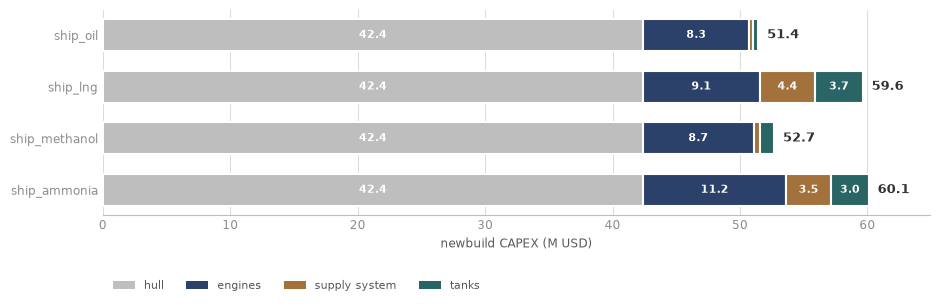

Retrofitting an existing ship, instead of replacing it:


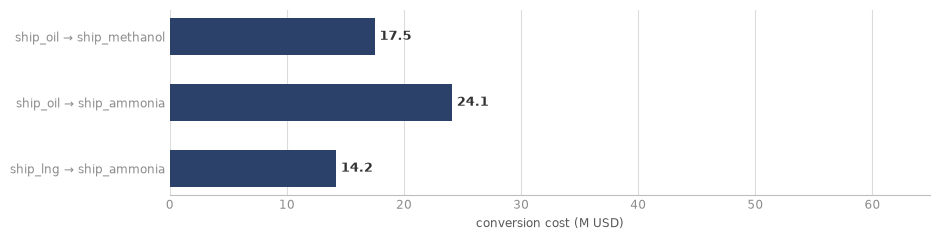

In [13]:
# @title Newbuild CAPEX, retrofit costs and cost of capital
# What the four configurations cost to build.
#
# In this example, the HULL is identical by design - same 80,000 DWT Panamax - so the premium
# for a dual-fuel ship is not in Vessel.CAPEX but in the machinery. The model charges three
# pieces of it, and the charter rate carries all three (navigate/vessel/charter.py):
#   engines        the converters in the PowerSystem, priced per MW installed
#   supply system  the PowerSystem's own CAPEX, a lump sum for fuel handling and safety
#   tanks          each Tank on the vessel, priced per m3 of containment
def scalar(x, t=0.):
    """Resolve a Forecast / Variable / plain number to a value at time t."""
    if hasattr(x, "calculate"):
        return float(x.calculate(t))
    if hasattr(x, "get"):
        return float(x.get())
    return float(x)

rows = []
for name, v in manager.nodes.vessels.items():
    engines = sum(scalar(c.power_capacity) * scalar(c.CAPEX)
                  for c in v.power_system.get_converters())
    supply = scalar(v.power_system.CAPEX)
    tanks = sum(scalar(t.size) * scalar(t.CAPEX) for t in v.tanks)
    machinery = engines + supply + tanks
    hull = scalar(v.CAPEX)
    rows.append({"configuration": name,
                 "hull (M USD)": hull / 1e6,
                 "engines (M USD)": engines / 1e6,
                 "supply system (M USD)": supply / 1e6,
                 "tanks (M USD)": tanks / 1e6,
                 "newbuild total (M USD)": (hull + machinery) / 1e6,
                 "capacity (DWT)": scalar(v.nominal_capacity),
                 "life (yr)": scalar(v.lifetime)})

table = pd.DataFrame(rows).set_index("configuration")
# The same four numbers as a picture, so the split is visible rather than read.
# The hull is drawn in grey because it is the part that does NOT vary: identical
# by design across all four, and still four fifths of the bill. Only the three
# machinery components carry a colour, because they are what the fuel choice moves.
from matplotlib.patches import Patch

COMPONENTS = [("hull (M USD)", "hull", MUTED),
              ("engines (M USD)", "engines", BLUE),
              ("supply system (M USD)", "supply system", ORANGE),
              ("tanks (M USD)", "tanks", GREEN)]

fig, ax = plt.subplots(figsize=(9.5, 3.4))
y = range(len(table))
left = [0.] * len(table)

for column, _label, colour in COMPONENTS:
    values = table[column].to_numpy()
    ax.barh(list(y), values, left=left, height=.62, color=colour, zorder=3,
            edgecolor="white", linewidth=1.5)
    for i, (value, start) in enumerate(zip(values, left)):
        if value >= 2.:                  # only where the segment can hold a number
            ax.annotate(f"{value:.1f}", (start + value / 2, i), ha="center",
                        va="center", fontsize=8, color="white", fontweight="bold",
                        zorder=5)
    left = [a + b for a, b in zip(left, values)]

for i, total in enumerate(left):
    ax.annotate(f"{total:.1f}", (total + 0.7, i), va="center", fontsize=9,
                color=INK, fontweight="bold")

ax.set_yticks(list(y), list(table.index))
ax.set_xlabel("newbuild CAPEX (M USD)", fontsize=8.5, color=SUBINK)
CAPEX_XLIM = max(left) * 1.08   # shared with the retrofit chart, so the two compare
ax.set_xlim(0, CAPEX_XLIM)
ax.invert_yaxis()
ax.grid(axis="x", color=GRID, lw=.8)
ax.set_axisbelow(True)
ax.tick_params(colors=TICK, labelsize=8.5, length=0)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(AXIS)
ax.legend(handles=[Patch(facecolor=colour, label=label)
                   for _column, label, colour in COMPONENTS],
          fontsize=8, frameon=False, labelcolor=SUBINK, ncol=4,
          loc="lower left", bbox_to_anchor=(0, -.42))
fig.tight_layout()
plt.show()

# What it costs to convert a ship that already exists, instead of replacing it.
# get_fuel_conversion_cost_pairs() returns only the pairs that were actually given
# a cost; the underlying dict also carries None-valued self-pairs.
fleet = manager.nodes.fleets["copper_trade"]
retrofits = pd.DataFrame(
    [{"from": frm, "to": to,
      "retrofit (M USD)": scalar(fleet.fuel_conversion_cost[(frm, to)]) / 1e6}
     for frm, to in fleet.get_fuel_conversion_cost_pairs()]
).set_index(["from", "to"])

print("Retrofitting an existing ship, instead of replacing it:")

fig, ax = plt.subplots(figsize=(9.5, 2.5))
routes = [f"{frm} \u2192 {to}"
          for frm, to in retrofits.index]
costs = retrofits["retrofit (M USD)"].to_numpy()

ax.barh(range(len(routes)), costs, height=.55, color=BLUE, zorder=3)
for i, cost in enumerate(costs):
    ax.annotate(f"{cost:.1f}", (cost + 0.4, i), va="center", fontsize=9,
                color=INK, fontweight="bold")

ax.set_yticks(range(len(routes)), routes)
ax.set_xlabel("conversion cost (M USD)", fontsize=8.5, color=SUBINK)
ax.set_xlim(0, CAPEX_XLIM)     # same scale as the newbuild chart above
ax.invert_yaxis()
ax.grid(axis="x", color=GRID, lw=.8)
ax.set_axisbelow(True)
ax.tick_params(colors=TICK, labelsize=8.5, length=0)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(AXIS)
fig.tight_layout()
plt.show()


The newbuild hull is the same 42.4 M USD whichever fuel it burns, so the newbuild premium
for going dual-fuel is entirely in the machinery (engines, supply system and tanks): about **+1.2 M for methanol,
+8.2 M for LNG, +8.7 M for ammonia** over a plain oil ship. Ammonia and LNG machinery cost
about the same, because both need containment and fuel-handling equipment that the oil ship
does not. For LNG almost all of the premium is that equipment; ammonia adds a dearer engine on top of it.

The loss of cargo is deliberately not included in the base assumptions: with an optimized ship design it can be reduced to a negligible amount.
(If needed, a number can however be added in the model by changing the Nominal Capacity of a specific ship.)

Important note: the ammonia ship is financed at an **11.05 %** rate in the near future (due to a higher risk) against **8.89 %** for the other
three, easing back to the same 8.89 % by 2030 (when the technology is expected to have matured).

#### Efficiency technology on offer, and what is already fitted

The assumptions library carries seven efficiency measures for this vessel
class. This deck fits all seven, each with its own cost and saving:

| Measure | Saves | CAPEX | OPEX/yr | Life |
|---|---|---|---|---|
| Exhaust-gas boiler (aux) | 5.0 % of heat | 100 k | 10 k | 25 yr\* |
| Lighting system | 2.5 % of electrical | 100 k | 0 | 25 yr\* |
| Variable frequency drive | 10.0 % of electrical | 100 k | 5 k | 25 yr\* |
| Propeller improvement devices | 2.0 % of propulsion | 150 k | 0 | 25 yr\* |
| Hull painting | 5.0 % of propulsion | 200 k | 24 k | **5 yr**, then repainted |
| Air lubrication | 4.0 % of propulsion | 1.5 M | 20 k | 25 yr |
| Flettner rotor | 0.4 MW of external power | 2.0 M | 40 k | 25 yr\* |

\* No lifetime is actually set, so the measure is never replaced: it stays on the ship until the ship leaves the fleet (at most 25 years, the library's lifetime for this class).

The measures are listed cheapest first, the three at 100 k in the order the deck
lists them. This is the order Navigate fits them in, its technology *ladder*
(Part 3, Stage 2 explains it), and every figure in this notebook uses it.

Efficiency technologies are fitted on newbuild ships or during a retrofitting cycle that occurs every 5 years.

The fleet does not start empty, though. It starts with a share of each technology already fitted, set by `set_initial_technology_share` in `includes/energy_efficiencies.inc` from the world Panamax fleet's shares in:

```
assumptions/defaults/installation/Curve/uptake_<measure>_bulk_carrier_panamax.inc
```

The Flettner rotor and air lubrication have no such curve, so they start at zero.
The other shares fall as the measures get dearer, which is what the ladder needs:
a ship that carries a measure must also carry every cheaper one.

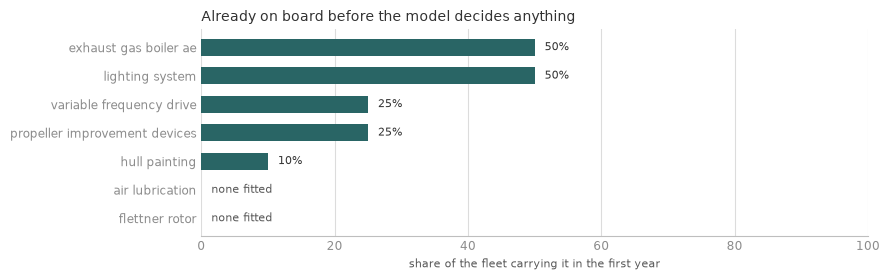

In [14]:
# @title Efficiency technology on offer, and what is already fitted
# What each hull already carries before the model decides anything. Read off the
# parsed deck: initial_technology_share maps (vessel, technology) to the library
# Curve the deck pointed it at, or None for a measure with no observed uptake.
_fleet_node = manager.nodes.fleets["copper_trade"]
start_share = {}
for (_vessel, _tech), _curve in _fleet_node.initial_technology_share.items():
    _short = _tech.replace("_bulk_carrier_panamax", "")
    start_share[_short] = float(_curve.get(0.)) if _curve is not None else 0.

# in the model's ladder order, cheapest first, as everywhere in the workshop
_order = [t.get_name().replace("_bulk_carrier_panamax", "")
          for t in _fleet_node.technology_packages[-1].technologies]

fig, ax = plt.subplots(figsize=(9, 2.9))
ax.barh(range(len(_order)), [start_share[t] * 100 for t in _order], height=.6,
        color=[GREEN if start_share[t] > 0 else MUTED for t in _order], zorder=3)
for _i, _t in enumerate(_order):
    ax.annotate(f"{start_share[_t] * 100:.0f}%" if start_share[_t] else "none fitted",
                (start_share[_t] * 100 + 1.5, _i), va="center", fontsize=8,
                color=INK if start_share[_t] else SUBINK)
ax.set_yticks(range(len(_order)), [t.replace("_", " ") for t in _order])
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("share of the fleet carrying it in the first year", fontsize=8,
              color=SUBINK)
ax.set_title("Already on board before the model decides anything", fontsize=10,
             color=INK, loc="left")
ax.grid(axis="x", color=GRID, lw=.8)
ax.set_axisbelow(True)
ax.tick_params(colors=TICK, labelsize=8.5, length=0)
for _side in ("top", "right", "left"):
    ax.spines[_side].set_visible(False)
ax.spines["bottom"].set_color(AXIS)
fig.tight_layout()
plt.show()


#### How sharply the owners react

The **decision sensitivities** the `.nav` pulls in with `Load DefaultCalibration`
set how sharply the owners respond to a cost difference.

`DefaultCalibration` also sets three **inertias**, which slow every decision down.
Each year, 60 % of the newbuilds follow the same mix of ship types as the year
before (`Inertia` on the `Fleet`), the producers do the same with their plants
(`Inertia` on the `Producer`), and every port keeps bunkering at least 70 % of what
it sold of each fuel the year before (`set_bunkering_inertia`).

In [15]:
# @title The decision sensitivities in this deck
# The sensitivities that govern how strongly an advantage translates into a
# change of fuel, of hull, or of equipment. These are plain attributes on the
# Fleet.
print("Decision sensitivities (from DefaultCalibration):")
for label, value in [
    ("InterFuelSensitivity", fleet.inter_fuel_sensitivity),
    ("IntraFuelSensitivity", fleet.intra_fuel_sensitivity),
    ("FuelConversionSensitivity", fleet.fuel_conversion_sensitivity),
    ("TechnologySensitivity", fleet.technology_sensitivity),
]:
    print(f"  {label:28} {scalar(value):.2f}")

print("Inertias (from DefaultCalibration):")
print(f"  {'Fleet Inertia':28} {scalar(fleet.inertia):.2f}")
for name, producer in manager.nodes.producers.items():
    print(f"  {'Producer Inertia':28} {scalar(producer.inertia):.2f}   ({name})")
for name, port in manager.nodes.ports.items():
    for fuel, value in port.bunkering_inertia.items():
        print(f"  {'set_bunkering_inertia':28} {scalar(value):.2f}   ({name}, {fuel})")
        break   # the same value for every fuel


Decision sensitivities (from DefaultCalibration):
  InterFuelSensitivity         0.75
  IntraFuelSensitivity         0.75
  FuelConversionSensitivity    2.00
  TechnologySensitivity        2.00
Inertias (from DefaultCalibration):
  Fleet Inertia                0.60
  Producer Inertia             0.60   (producer_efuel)
  Producer Inertia             0.60   (producer_biofuel)
  set_bunkering_inertia        0.70   (san_antonio, fossil_fuel_oil)
  set_bunkering_inertia        0.70   (rotterdam, fossil_fuel_oil)


Each sensitivity says how strongly the owners favour the cheaper option. The
fleet stands for many owners who face the same costs but do not all decide
alike, so a choice comes out as shares spread across them. A value close to 1
means they hardly care about cost and their choices stay evenly spread. A value
far from 1 means nearly all of them pick the cheapest.

For the choice of fuel type, with $c_i$ the levelized transport cost
of fuel type $i$, $s_i$ its share of the newbuilds and $S$ the value of
`InterFuelSensitivity`:

$$
\frac{s_i}{s_j} = \left(\frac{c_i}{c_j}\right)^{-\beta},
\qquad \beta = -\frac{\ln S}{\ln 1.1}
$$

Retrofits work the same way, but on NPV rather than cost. When a ship reaches a
retrofit cycle, each possible conversion is weighed against keeping the ship as
it is. With $\mathrm{NPV}_i$ the net present value of conversion $i$ (the fuel
savings over the ship's remaining life, minus the conversion cost), CAPEX the
ship's capital cost and $S$ the value of `FuelConversionSensitivity`:

$$
\frac{s_i}{s_\mathrm{keep}} = e^{\beta \, \mathrm{NPV}_i / \mathrm{CAPEX}},
\qquad \beta = \frac{\ln S}{0.05}
$$

The figure below draws both formulas for a choice between two options. The bold
line is the deck's value, the dashed lines less and more decisive owners.

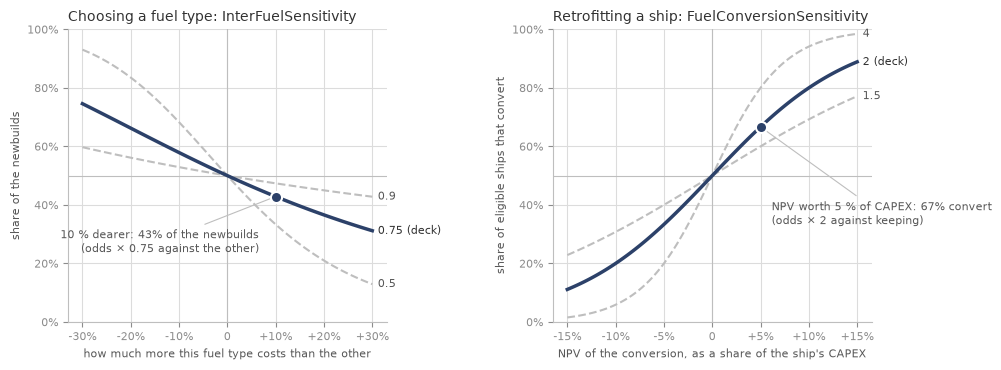

In [16]:
# @title Figure: how a sensitivity turns a cost gap into shares
# The two formulas above, drawn for a choice between two options only: the
# share one option gets as its gap to the other grows. With more options the
# odds ratios hold the same way, but the shares spread thinner.
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

_STYLE_DIR = str(Path("docs/workshop").resolve())
if _STYLE_DIR not in sys.path:
    sys.path.insert(0, _STYLE_DIR)
from _style import AXIS, BLUE, GRID, INK, MUTED, SUBINK, TICK

INTER_FUEL = scalar(fleet.inter_fuel_sensitivity)
FUEL_CONVERSION = scalar(fleet.fuel_conversion_sensitivity)


def share_by_cost(gap, odds):
    """Share of a fuel type whose cost is `gap` above (or below) the other's."""
    beta = -np.log(odds) / np.log(1.1)
    return 1 / (1 + (1 + gap) ** beta)


def share_by_npv(npv_over_capex, odds):
    """Share of eligible ships that convert, against keeping the ship."""
    beta = np.log(odds) / 0.05
    return 1 / (1 + np.exp(-beta * npv_over_capex))


def style(ax, title, xlab):
    ax.set_title(title, fontsize=10, color=INK, loc="left")
    ax.set_xlabel(xlab, fontsize=8, color=SUBINK)
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:+.0%}" if x else "0")
    ax.axhline(0.5, color=AXIS, lw=0.8, zorder=1)
    ax.axvline(0, color=AXIS, lw=0.8, zorder=1)
    ax.grid(color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TICK, labelsize=8)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)


def curves(ax, x, share, deck, others, point):
    """The deck's value in bold, two others in grey, each labelled at its end."""
    for odds in others:
        ax.plot(x, share(x, odds), color=MUTED, lw=1.5, ls="--", zorder=2)
        ax.annotate(f"{odds:g}", (x[-1], share(x[-1], odds)), xytext=(4, 0),
                    textcoords="offset points", va="center", fontsize=8, color=SUBINK)
    ax.plot(x, share(x, deck), color=BLUE, lw=2.5, zorder=3)
    ax.annotate(f"{deck:g} (deck)", (x[-1], share(x[-1], deck)), xytext=(4, 0),
                textcoords="offset points", va="center", fontsize=8, color=INK)
    y = share(point, deck)
    ax.plot(point, y, "o", color=BLUE, ms=8, mec="white", mew=1.5, zorder=4)
    return y


fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))

gap = np.linspace(-0.3, 0.3, 121)
y = curves(left, gap, share_by_cost, INTER_FUEL, (0.9, 0.5), 0.10)
left.annotate(f"10 % dearer: {y:.0%} of the newbuilds\n(odds × {INTER_FUEL:g} against the other)",
              (0.10, y), xytext=(-12, -40), textcoords="offset points", ha="right",
              fontsize=8, color=SUBINK, arrowprops=dict(arrowstyle="-", color=AXIS, lw=0.8))
style(left, "Choosing a fuel type: InterFuelSensitivity",
      "how much more this fuel type costs than the other")
left.set_ylabel("share of the newbuilds", fontsize=8, color=SUBINK)

npv = np.linspace(-0.15, 0.15, 121)
y = curves(right, npv, share_by_npv, FUEL_CONVERSION, (1.5, 4), 0.05)
right.annotate(f"NPV worth 5 % of CAPEX: {y:.0%} convert\n(odds × {FUEL_CONVERSION:g} against keeping)",
               (0.05, y), xytext=(8, -70), textcoords="offset points", ha="left",
               fontsize=8, color=SUBINK, arrowprops=dict(arrowstyle="-", color=AXIS, lw=0.8))
style(right, "Retrofitting a ship: FuelConversionSensitivity",
      "NPV of the conversion, as a share of the ship's CAPEX")
right.set_ylabel("share of eligible ships that convert", fontsize=8, color=SUBINK)

fig.tight_layout(w_pad=4)
plt.show()


---

### 2. Data about the fuels

In this example, we assume that fossil fuels (fuel oil and LNG) have a flat price until 2050.

Electricity is more than half of what an e-fuel costs to make, and up to about 80 %. It is assumed that it's cost decreases in the future.

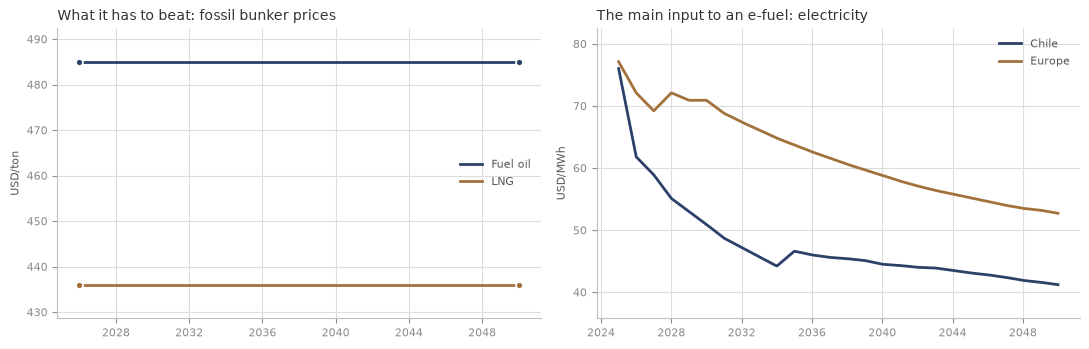

In [17]:
# @title Figure: fossil fuel and electricity prices
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))

panel(ax1, [("fossil_fuel_oil_price_global", "Fuel oil"),
            ("liquefied_natural_gas_price_global", "LNG")],
      "What it has to beat: fossil bunker prices", "USD/ton")
panel(ax2, [("electricity_cost_americas_mid", "Chile"),
            ("electricity_cost_europe_mid", "Europe")],
      "The main input to an e-fuel: electricity", "USD/MWh")

fig.tight_layout()
plt.show()


The synthesis and electrolyser cost tables are currently assumed flat in time. Learning rates (costs falling as more capacity is built) may be added in a future version of Navigate.

For bio-methanol, the CAPEX is a forecast that falls over time.

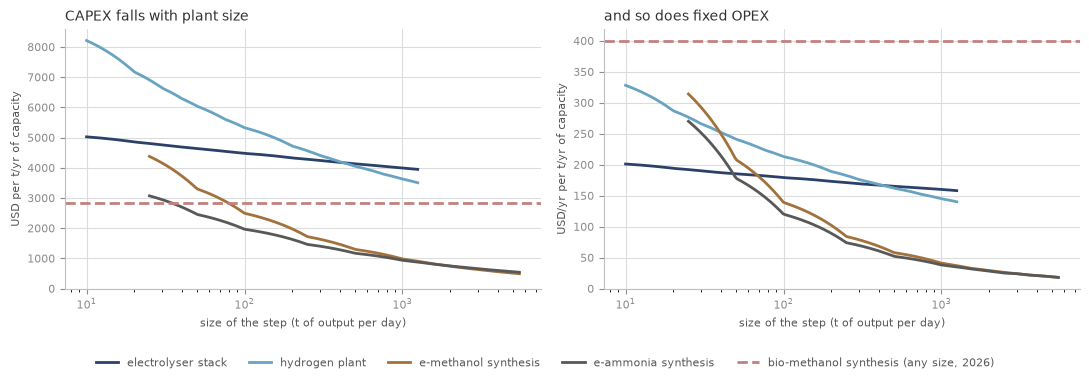

Additional input data


,inputs per t of output,electricity (MWh/t),life (yr)
step,,,
electrolyser stack,10.00 t demineralized_water,51.00,10.0
hydrogen plant,1.00 t electrolysis_stack_alkaline,4.00,20.0
e-methanol synthesis,"0.19 t hydrogen_electro_alkaline, 1.40 t carbo...",1.55,plant's
e-ammonia synthesis,"0.18 t hydrogen_electro_alkaline, 0.82 t nitro...",0.44,plant's
bio-methanol synthesis,2.42 t feedstock_biomethanol_gasification,0.52,plant's


Bio-methanol is costed per ton, not by size: CAPEX 2,840 USD per t/yr of capacity in 2026, fixed OPEX 400 USD/yr per t/yr.
Feedstock prices (USD/t): carbon_dioxide_biogenic 150, feedstock_biomethanol_gasification 65, demineralized_water 2


In [18]:
# @title Fuel production data, read off the deck
# Inputs only: every number here is read off the parsed deck, none from the run.
_region = manager.nodes.regions["europe"]     # the process economics are the same in every region
# the two hydrogen steps in blues
_STEPS = [("electrolysis_stack_alkaline", "electrolyser stack", BLUE),
          ("hydrogen_electro_alkaline", "hydrogen plant", series_colours(6)[5]),
          ("methanol_synthesis_electro_alkaline", "e-methanol synthesis", ORANGE),
          ("ammonia_synthesis_electro_alkaline", "e-ammonia synthesis", SUBINK)]


def size_curve(table):
    """A cost table across the plant sizes it is defined for, at the first year."""
    sizes = np.geomspace(table.get_y_min(), table.get_y_max(), 200)
    return sizes, np.array([table.get(0., s) for s in sizes])


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
for process, label, colour in _STEPS:
    for ax, table in ((ax1, _region.get_process_CAPEX(process)),
                      (ax2, _region.get_process_OPEX(process))):
        sizes, cost = size_curve(table)
        ax.plot(sizes, cost, color=colour, lw=2, label=label)
# bio-methanol is costed by year, not by size: a flat line at its 2026 value
_bio = "methanol_synthesis_bio_gasification"
for ax, cost in ((ax1, _region.get_process_CAPEX(_bio)), (ax2, _region.get_process_OPEX(_bio))):
    ax.axhline(scalar(cost, 0.), color=fuel_colour("methanol_bio"), lw=2, ls="--",
               label="bio-methanol synthesis (any size, 2026)")

for ax, title, ylab in ((ax1, "CAPEX falls with plant size", "USD per t/yr of capacity"),
                        (ax2, "and so does fixed OPEX", "USD/yr per t/yr of capacity")):
    ax.set_title(title, fontsize=10, color=INK, loc="left")
    ax.set_ylabel(ylab, fontsize=8, color=SUBINK)
    ax.grid(color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TICK, labelsize=8)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)
for ax in (ax1, ax2):
    ax.set_xscale("log")
    ax.set_xlabel("size of the step (t of output per day)", fontsize=8, color=SUBINK)
    ax.set_ylim(0, None)
fig.legend(*ax1.get_legend_handles_labels(), loc="lower center", ncol=5,
           fontsize=8, frameon=False, labelcolor=SUBINK)
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

# What each step needs per ton of what it makes, at the first year.
print("Additional input data")
_rows = []
for process, label, _colour in _STEPS + [("methanol_synthesis_bio_gasification", "bio-methanol synthesis", None)]:
    node = manager.nodes.processes[process]
    feeds = ", ".join(f"{scalar(c):.2f} t {f.get_name()}" for f, c in zip(node.feeds, node.conversions))
    lifetime = _region.get_process_lifetime(process)
    _rows.append({"step": label,
                  "inputs per t of output": feeds,
                  "electricity (MWh/t)": scalar(_region.get_process_energy(process)),
                  "life (yr)": scalar(lifetime) if lifetime is not None else "plant's"})
display(pd.DataFrame(_rows).set_index("step"))

print("Bio-methanol is costed per ton, not by size: "
      f"CAPEX {scalar(_region.get_process_CAPEX(_bio), 0.):,.0f} USD per t/yr of capacity in 2026, "
      f"fixed OPEX {scalar(_region.get_process_OPEX(_bio)):,.0f} USD/yr per t/yr.")
print("Feedstock prices (USD/t): " + ", ".join(
    f"{f} {scalar(_region.get_feedstock_cost(f)):,.0f}"
    for f in ("carbon_dioxide_biogenic", "feedstock_biomethanol_gasification", "demineralized_water")))


#### Feedstock availability

Fuels that contain carbon can be limited by how much of their carbon source exists.
Bio-methanol needs gasifiable biomass, and e-methanol needs biogenic CO2.

Each cap is set in `includes/producer.inc`, on the producer that uses the feedstock,
and covers all of that producer's plants. The library gives the world's supply and
the share of it shipping could use; the deck keeps only a small slice of that for
this one trade.

The cell below shows how much of each feedstock is available in this example.


  Gasification feedstock     ceiling  0.81 Mt/yr in 2026, rising to  0.95 by 2050
  Biogenic CO2 (PS)          ceiling  0.14 Mt/yr in 2026, rising to  0.53 by 2050


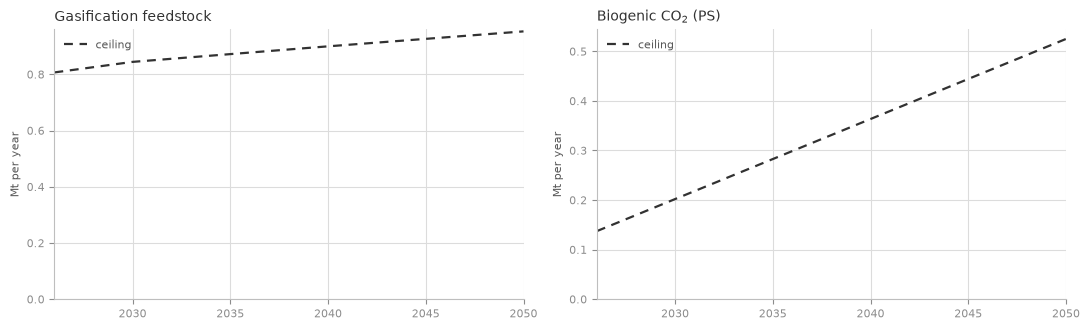

In [19]:
# @title Figure: feedstock ceilings
# What the two feedstock ceilings allow. The ceilings only - what the run draws
# against them is a result, and is plotted in Part 3.
#
# A ceiling is a deck EXPRESSION rather than a plain Forecast, so it is resolved
# the way this Part resolves emission factors: `calculate` where the node has
# one, `get(t)` where it does not.
from navigate.illustrations.plots._labels import FEEDSTOCK_LABEL

_days = manager.get_timeline()
_years = manager.get_dateline().astype("datetime64[Y]").astype(int) + 1970


def _feed_ceiling(node, when):
    """One feed ceiling in tons a year, `when` days from the start date."""
    if hasattr(node, "calculate"):
        return float(node.calculate(when))
    try:
        return float(node.get(when))
    except TypeError:
        return float(node.get())


# Every constrained feed in the deck, widest allowance first. That ordering is a
# property of the deck rather than of the run, so the Part 3 figure can reuse it
# and the two will read in the same order.
CEILINGS = sorted(
    ({"feed": _feed,
      "cap": np.array([_feed_ceiling(_node, _w) for _w in _days]) / 1e6}
     for _producer in manager.nodes.producers.values()
     for _feed, _node in _producer.feed_constraints.items() if _node is not None),
    key=lambda c: -c["cap"][-1])

fig, axes = plt.subplots(1, len(CEILINGS), figsize=(11, 3.4), sharex=True)

for ax, c in zip(np.atleast_1d(axes), CEILINGS):
    ax.plot(_years, c["cap"], color=INK, lw=1.6, ls=(0, (4, 3)), label="ceiling")
    ax.set_title(FEEDSTOCK_LABEL.get(c["feed"], c["feed"]), fontsize=10,
                 color=INK, loc="left")
    ax.set_ylabel("Mt per year", fontsize=8, color=SUBINK)
    ax.set_ylim(bottom=0.)
    ax.margins(x=0)
    ax.legend(fontsize=8, frameon=False, labelcolor=SUBINK, loc="upper left")
    ax.grid(color=GRID, lw=.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TICK, labelsize=8)
    for _side in ("top", "right"):
        ax.spines[_side].set_visible(False)
    for _side in ("left", "bottom"):
        ax.spines[_side].set_color(AXIS)

fig.tight_layout()

for c in CEILINGS:
    # the display labels carry mathtext for the figure, so flatten it for print
    _name = FEEDSTOCK_LABEL.get(c["feed"], c["feed"]).replace("$_2$", "2").replace("$", "")
    print(f"  {_name:26} ceiling {c['cap'][0]:5.2f} Mt/yr in {_years[0]}, "
          f"rising to {c['cap'][-1]:5.2f} by {_years[-1]}")
plt.show()

---

### 3. Data about bunkering

This deck adds a transport cost, `distance × rate` from the plant to the bunker port,
to the cost of each fuel. It means that fuel is cheap at the port next door and carries a
penalty at the far one. The values are invented for this example.


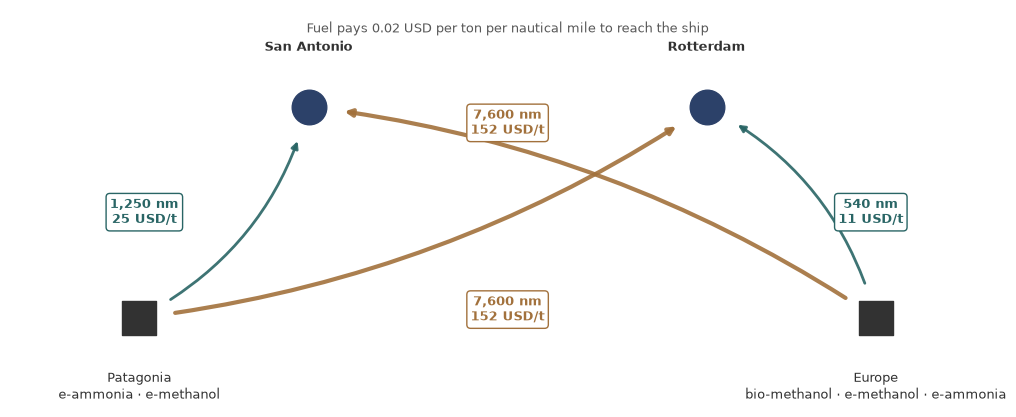

In [20]:
# @title Figure: bunker logistics
import re

text = (EXAMPLE / "includes" / "bunker_logistics.inc").read_text(encoding="utf-8")

# USD per ton per nautical mile (Navigate: `set_transport_cost`)
USD_PER_TON_NM = float(
    re.search(r'set_transport_cost\("\*",\s*([\d.]+)\)', text).group(1))

# One entry per journey the FUEL makes, plant region -> bunker port
# (Navigate: `set_distance`, from a Region to a Port). Navigate keeps the word
# "leg" for the ship's own route segments, so these are trips, not legs.
FUEL_DELIVERY_TRIPS = [(region, port, int(nm)) for region, port, nm in
                       re.findall(r'set_distance\("(\w+)",\s*"(\w+)",\s*(\d+)\)', text)]

# Drawn rather than tabulated: the point is the CONTRAST between fuel bunkered
# next door and fuel shipped to the far port, which a table makes you work out.
# Positions are schematic - this is the supply chain, not a projection.
POS = {"americas": (0.13, 0.24), "san_antonio": (0.30, 0.76),
       "europe": (0.87, 0.24), "rotterdam": (0.70, 0.76)}
CAPTION = {"americas": "Patagonia\ne-ammonia · e-methanol",
           "europe": "Europe\nbio-methanol · e-methanol · e-ammonia",
           "san_antonio": "San Antonio", "rotterdam": "Rotterdam"}
LOCAL = {("americas", "san_antonio"), ("europe", "rotterdam")}
# arc curvature, then where the label sits; keeps the two crossings legible
DRAW = {("americas", "san_antonio"): (0.22, 0.135, 0.50),
        ("europe", "rotterdam"): (0.22, 0.865, 0.50),
        ("americas", "rotterdam"): (0.12, 0.50, 0.26),
        ("europe", "san_antonio"): (0.12, 0.50, 0.72)}

fig, ax = plt.subplots(figsize=(10.5, 4.3))

for region, port, nm in FUEL_DELIVERY_TRIPS:
    rad, lx, ly = DRAW.get((region, port), (0.12, 0.5, 0.5))
    local = (region, port) in LOCAL
    colour = GREEN if local else ORANGE
    ax.annotate("", xy=POS[port], xytext=POS[region],
                arrowprops=dict(arrowstyle="-|>", color=colour,
                                lw=2.0 if local else 3.0, alpha=0.9,
                                connectionstyle=f"arc3,rad={rad}",
                                shrinkA=26, shrinkB=26))
    ax.text(lx, ly, f"{nm:,} nm\n{nm * USD_PER_TON_NM:.0f} USD/t",
            ha="center", va="center", fontsize=9, color=colour,
            fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.30", fc="white", ec=colour, lw=1.0))

for name, (x, y) in POS.items():
    is_port = name in ("san_antonio", "rotterdam")
    ax.scatter([x], [y], s=620, marker="o" if is_port else "s",
               color=BLUE if is_port else INK, zorder=4)
    ax.text(x, y + (0.13 if is_port else -0.13), CAPTION[name], ha="center",
            va="bottom" if is_port else "top", fontsize=9.5, color=INK,
            fontweight="bold" if is_port else "normal")

ax.text(0.5, 0.97, f"Fuel pays {USD_PER_TON_NM} USD per ton per nautical mile "
                   f"to reach the ship", ha="center", va="top", fontsize=9,
        color=SUBINK)
ax.set_xlim(0, 1)
ax.set_ylim(0.02, 1.0)
ax.axis("off")
fig.tight_layout()
plt.show()


---

### 4. Data about the regulations

The modelled regulations are driven by five factors: the **allowance price**,
the **intensity target**, the **penalty** for missing that target, the **scope** of emissions, and **how
much of the voyage is counted** at all. The first two are Forecasts and are
plotted below; the third is a single `Variable`; the fourth was set back in
Part 1, as `Jurisdiction` and the three coverage fractions.

The EU ETS is `Scope = TTW`, so it zero-rates the combustion carbon of every alternative
fuel — e-ammonia, e-methanol and bio-methanol carry the same factors per ton,
leaving only their methane and nitrous oxide to charge. FuelEU is
`Scope = WTW`, so it can influence the choices between the different
alternative fuel supplies.


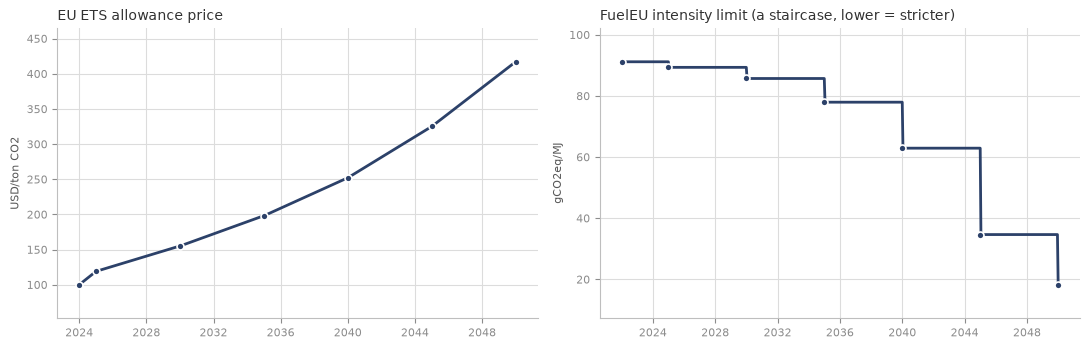

ETS allowance (USD/ton CO2)          100.0 (2024)  ->    417.0 (2050)
FuelEU limit (gCO2eq/MJ)              91.2 (2022)  ->     18.2 (2050)

FuelEU penalty for missing the cap   760.0 USD/ton, flat
EU ETS phase-in at the 2026 start     100% of emissions priced


In [21]:
# @title Figure: regulation prices and targets
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))

panel(ax1, [("eu_ets_carbon_credit_price", None)],
      "EU ETS allowance price", "USD/ton CO2")
panel(ax2, [("fuel_eu_target_reduction", None)],
      "FuelEU intensity limit (a staircase, lower = stricter)", "gCO2eq/MJ")

fig.tight_layout()
plt.show()

for name, label in [("eu_ets_carbon_credit_price", "ETS allowance (USD/ton CO2)"),
                    ("fuel_eu_target_reduction", "FuelEU limit (gCO2eq/MJ)")]:
    df = forecast_to_frame(name)
    first, last = df.iloc[0], df.iloc[-1]
    print(f"{label:34} {first['value']:7.1f} ({first['date'].year})"
          f"  ->  {last['value']:7.1f} ({last['date'].year})")

# The lever that actually moves the answer is not a Forecast at all: a single
# number with no axis is a `Variable`, read with .get().
penalty = manager.nodes.variables["fuel_eu_remedial_cost"].get()
print(f"\n{'FuelEU penalty for missing the cap':34} {penalty:7.1f} USD/ton, flat")

# And the ETS is not phasing in over this run: it is complete on day one.
phase_in = forecast_to_frame("eu_ets_maritime_phase_in")
started = phase_in.loc[phase_in["date"].dt.year <= 2026, "value"].iloc[-1]
print(f"{'EU ETS phase-in at the 2026 start':34} {started:7.0%} of emissions priced")


The ETS price climbs steadily and the FuelEU limit hardly moves before 2035,
then falls away in steps. So the pressure arrives early as a price and late as
a cap. Breaching the cap leads to a **760 USD/ton penalty** which is the strongest single lever in the deck.

#### What each regulation actually counts

The `Scope` (WTW or TTW) decides which part of the fuel chain is counted for taxation. The graph below shows what is counted for each regulation.

The two e-fuels have no WTT written in `fuel_eu.inc` on purpose: Navigate derives theirs from the production chain the deck defines since they have no regulatory default values.

The same fuel can also score a different **TTW** for FuelEU and EU ETS because each regulation carries its own emission factors.

**FuelEU is WTW**, so it charges the full combustion carbon of the molecule at the funnel. Bio-methanol is charged 72 gCO2eq/MJ TTW (the same as e-methanol, because burning either releases the same carbon). In case of biogenic carbon use, the WTT component is credited with a negative value. That is not a modelling shortcut: the regulation derives the WTT from the lifecycle value on the fuel's Proof of Sustainability, reduced by the combustion carbon.

**The EU ETS is TTW**. It zero-rates the combustion CO2 of bio- and e-fuels. So for bio-methanol the TTW is about 2 (for N2O and CH4 emissions).

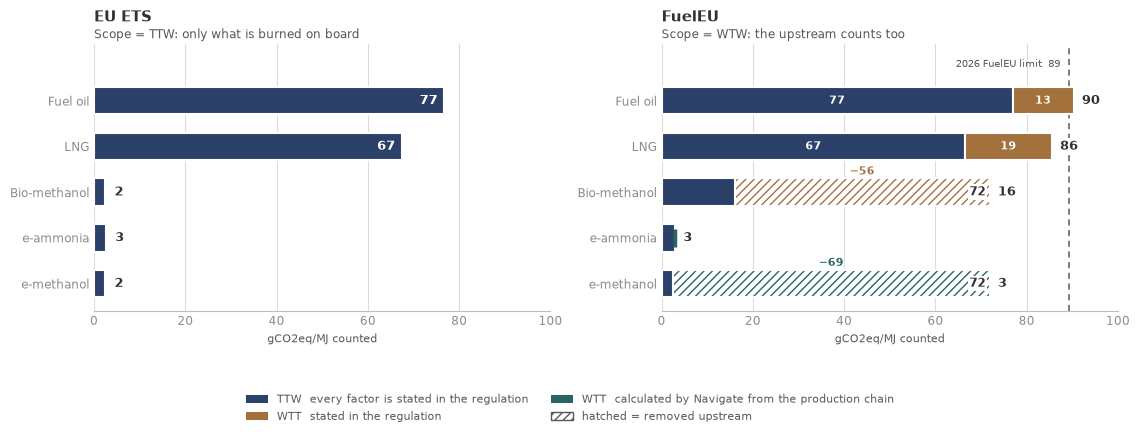

In [22]:
# @title Table: what each regulation charges each fuel
# What each regulation charges each fuel, and where each number comes from.
# The factors come from DECK_FACTORS, the copy Part 2's data-extraction cell took
# of the Regulation nodes before solving (`set_fuel_ttw` / `set_fuel_wtt` in eu_ets.inc and fuel_eu.inc).
# Where a regulation states no WTT of its own, Navigate derives one from the
# production chain instead, which is what the solved run supplies.
from navigate.illustrations.plots._labels import FUEL_LABEL, FUEL_ORDER

# Navigate's own display names and canonical fuel order, so this figure reads the
# same way as the plots the model generates. FUEL_ORDER covers every fuel the
# library knows about, so keep the five this deck actually defines.
ORDER = [f for f in FUEL_ORDER if f in manager.nodes.fuels]


def factor(node, t=0.):
    """An emission-factor node resolved to a number, or None where the deck leaves it open."""
    if node is None:
        return None
    if hasattr(node, "calculate"):
        return float(node.calculate(t))
    try:
        return float(node.get(t))      # expressions carry a Forecast, so they need a date
    except TypeError:
        return float(node.get())


def modelled_wtt(fuel_name, emission, idx=0):
    """The upstream emissions Navigate derives for a fuel from its production chain.

    The plant's own production emissions plus the delivery trip to the bunker port.
    Readable only because Part 2's data-extraction cell solved the deck -- none of this is written
    down in a .inc file. A fuel with no plant (the two fossils) has no chain, so
    there is nothing to derive.
    """
    for plant in manager.nodes.plants.values():
        if plant.fuel.get_name() != fuel_name:
            continue
        production = plant.expectation.get_production_WTT(emission, idx)
        delivery = max(plant.expectation.get_delivery_WTT(port, emission, idx)
                       for port in manager.nodes.ports)
        return production + delivery
    return None


def counted_intensity(regulation, fuel_name):
    """What `regulation` charges `fuel_name` as gCO2eq/MJ, and where the WTT came from.

    Returns (TTW, WTT, source). ton emission/ton fuel x GWP / (GJ/ton) x 1e3 -> g/MJ,
    using the regulation's OWN global warming potentials -- the two instruments do not
    use the same ones. `source` is "regulation" where the deck states a WTT factor and
    "navigate" where it states none and the production chain supplies it instead.
    """
    lhv = factor(manager.nodes.fuels[fuel_name].lower_heating_value)
    counts_wtt = str(regulation.scope).endswith("WTW")
    deck = DECK_FACTORS[regulation.get_name()]
    ttw, wtt, source = 0., 0., "regulation"
    for emission, gwp_node in deck["gwp"].items():
        gwp = factor(gwp_node)
        ttw_factor = factor(deck["ttw"].get((fuel_name, emission)))
        wtt_factor = factor(deck["wtt"].get((fuel_name, emission)))
        if wtt_factor is None and counts_wtt:
            wtt_factor, source = modelled_wtt(fuel_name, emission), "navigate"
        ttw += 0. if ttw_factor is None else ttw_factor * gwp / lhv * 1e3
        wtt += 0. if wtt_factor is None else wtt_factor * gwp / lhv * 1e3
    return ttw, wtt, source


from matplotlib.patches import Patch

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), sharex=True)
PANELS = [("eu_ets", "EU ETS", "Scope = TTW: only what is burned on board"),
          ("fuel_eu", "FuelEU", "Scope = WTW: the upstream counts too")]
LABEL_BOX = dict(boxstyle="square,pad=0.15", fc="white", ec="none")
LABEL_MIN = 10          # a bar narrower than this cannot hold a number

for ax, (reg_name, title, subtitle) in zip(axes, PANELS):
    reg = manager.nodes.regulations[reg_name]
    counts_wtt = str(reg.scope).endswith("WTW")

    for i, fuel in enumerate(ORDER):
        ttw, wtt, source = counted_intensity(reg, fuel)
        net = ttw + wtt if counts_wtt else ttw
        colour = ORANGE if source == "regulation" else GREEN

        ax.barh(i, ttw, height=.6, color=BLUE, zorder=3,
                edgecolor="white", linewidth=1.5)
        if counts_wtt and wtt > 0:
            ax.barh(i, wtt, left=ttw, height=.6, color=colour, zorder=3,
                    edgecolor="white", linewidth=1.5)
        elif counts_wtt and wtt < 0:
            # the regulation really does remove these emissions upstream, so the credit
            # is drawn eating into the TTW bar rather than extending it: what is left
            # solid is what actually counts
            # the hatch is drawn in the edge colour, so it goes on with no outline;
            # the white outline is added separately, matching the solid bars exactly,
            # so both end up the same visible thickness
            ax.barh(i, ttw - net, left=net, height=.6, facecolor="white", zorder=4,
                    edgecolor=colour, linewidth=0, hatch="////")
            ax.barh(i, ttw - net, left=net, height=.6, facecolor="none", zorder=4,
                    edgecolor="white", linewidth=1.5)
        elif counts_wtt:
            # a derived WTT that comes out at zero still has a provenance worth showing
            ax.plot([ttw], [i], marker="|", ms=13, mew=2.5, color=colour, zorder=5)

        # A single-part row (the EU ETS panel) carries one number: inside the bar,
        # or just outside it when the bar is too narrow to hold it.
        if not counts_wtt:
            if ttw >= LABEL_MIN:
                ax.annotate(f"{ttw:.0f}", (ttw - 1.5, i), ha="right", va="center",
                            fontsize=9, color="white", fontweight="bold", zorder=6)
            else:
                ax.annotate(f"{ttw:.0f}", (ttw + 2, i), va="center", fontsize=9,
                            color=INK, fontweight="bold", zorder=6)
        else:
            # Read the same way as the fuel-and-compliance bills: every part that
            # shows at the printed precision carries its number, a removed part
            # with its minus sign on top of its hatching, and the total after the
            # bar is the sum of what is printed, so the row adds up as printed.
            shown_ttw, shown_wtt = round(ttw), round(wtt)
            if shown_wtt < 0:
                # the TTW number sits at the end of the TTW extent, which on a
                # credited row is the far edge of the hatching
                ax.annotate(f"{shown_ttw}", (ttw, i), xytext=(-3, 0),
                            textcoords="offset points", ha="right", va="center",
                            fontsize=8.5, fontweight="bold", zorder=6, color=INK,
                            bbox=LABEL_BOX)
                ax.annotate(f"\u2212{-shown_wtt}", ((net + ttw) / 2, i - .3),
                            xytext=(0, 1), textcoords="offset points", ha="center",
                            va="bottom", fontsize=8, color=colour,
                            fontweight="bold", zorder=6)
            elif shown_wtt > 0:
                for value, start in ((ttw, 0.), (wtt, ttw)):
                    if value >= LABEL_MIN:
                        ax.annotate(f"{round(value)}", (start + value / 2, i),
                                    ha="center", va="center", fontsize=8,
                                    color="white", fontweight="bold", zorder=6)
                    else:
                        # too narrow to hold its number: just above the bar
                        ax.annotate(f"{round(value)}", (start + value / 2, i - .3),
                                    xytext=(0, 1), textcoords="offset points",
                                    ha="center", va="bottom", fontsize=7.5,
                                    color=INK, zorder=6)
            # with a single part, the total is its number
            ax.annotate(f"{shown_ttw + shown_wtt}", (max(ttw, net), i), xytext=(6, 0),
                        textcoords="offset points", va="center", fontsize=9,
                        color=INK, fontweight="bold", zorder=6, bbox=LABEL_BOX)

    if counts_wtt:
        limit = factor(manager.nodes.forecasts["fuel_eu_target_reduction"])
        ax.axvline(limit, color=SUBINK, lw=1.1, ls=(0, (4, 3)), zorder=2)
        ax.annotate(f"2026 FuelEU limit  {limit:.0f}", (limit - 2, -.8),
                    fontsize=7.5, color=SUBINK, ha="right", va="center")

    ax.set_title(title, fontsize=11, color=INK, loc="left", pad=16, fontweight="bold")
    ax.annotate(subtitle, (0, 1.02), xycoords="axes fraction", fontsize=8.5, color=SUBINK)
    ax.set_xlabel("gCO2eq/MJ counted", fontsize=8, color=SUBINK)
    ax.set_xlim(0, 100)
    ax.set_ylim(len(ORDER) - .4, -1.25)
    ax.set_yticks(range(len(ORDER)), [FUEL_LABEL[f] for f in ORDER])
    ax.grid(axis="x", color=GRID, lw=.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TICK, labelsize=8.5, length=0)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)

fig.legend(handles=[Patch(facecolor=BLUE, label="TTW  every factor is stated in the regulation"),
                    Patch(facecolor=ORANGE, label="WTT  stated in the regulation"),
                    Patch(facecolor=GREEN, label="WTT  calculated by Navigate from the production chain"),
                    Patch(facecolor="white", edgecolor=SUBINK, hatch="////",
                          label="hatched = removed upstream")],
           fontsize=8, frameon=False, labelcolor=SUBINK, ncol=2,
           loc="lower center", bbox_to_anchor=(.5, .005))
fig.tight_layout(rect=(0, .17, 1, 1))
plt.show()


When reading across the two panels you can see that, for bio-methanol, EU ETS gives 2 gCO2e/MJ of TTW emissions and FuelEU 16 gCO2e/MJ. The gap between those totals is bio-methanol's own production footprint: about 14 gCO2eq/MJ of growing, gasifying and shipping the biomass. FuelEU counts it; the ETS never looks upstream, so it cannot see it. The ETS therefore scores bio-methanol some 97 % better than fuel oil where FuelEU says 82 %.

---

## Part 3: Understand the logic behind the model

The idea of Navigate is to mimic the decision behavior of shipowners, operators and fuel producers to understand how the fleet transition may evolve under a given set of conditions.

The aim of this section is to go "inside Navigate's mind" and understand how the model solving actually works, step by step.

### How Navigate decides

Navigate gives a solution one year at a time.
The solving process is the same for each year and each decision maker in the model:

1. **look ahead**: make projections about the future
2. **decide**: make some fancy calculations based on your projections and take some decisions that make sense from an economic perspective (influenced by the behaviour traits of the decision maker: inertia and sensitivity)
3. **commit**: decisions have been taken and the other actors react; check how the fleet operates in "reality", which may differ from previously formed expectations.

In more detail, the model starts the year by calculating expectations and beliefs about the future from the information available — among them a look-ahead bunkering optimization, which prices the year before anything is decided. Those expectations then inform the decisions of the owners and the operators, in this order:

- efficiency measures (owners): implement (or not) efficiency technology, on existing ships when they reach their five-yearly retrofit cycle and on any ship ordered new
- operational measures (operators): change the vessels' sailing speed (while minimizing total cost per cargo-mile)
- fleet management (owners): scrap, retrofit or order new ships
- fuel bunkering (operators): which fuel to buy at which port for this year

The bunkering optimisation therefore runs twice: once as a forecast that informs the four
decisions, and once at the end of the year to commit.

What drives the decisions of the owners is mostly economic considerations, supplemented by some behavioral traits. When choosing the fuel type of new ships, owners lean towards the cheapest option but are not blind to the others: `InterFuelSensitivity` sets how sharply a cost gap between fuel types (e.g. ammonia or LNG) turns into a change of mind, and `IntraFuelSensitivity` does the same between ship designs that burn the same fuel type (this deck has only one design per fuel type, so that second axis does not decide anything here).

In other words, in Navigate, there is no "absolute winner": each option gets a **share**, larger when it is cheaper, and the sensitivities (~behavioral traits) in the deck set how sharply a cost gap turns into a share. With 300 ships those shares read as ships — "12 % e-ammonia" is about thirty-six hulls.

The fuel producers decide last, in the same year, basing their decisions on the expected fuel demand from the shipping sector: if that demand exceeds the supply already built or ordered, each producer takes its share of the expected unmet demand and turns that into fuel plants. Here too there is no "absolute winner", only shares.

Now, run the next cell that solves the model and "extracts" some information along the solving process that we can observe and analyze.


In [23]:
# @title Run the case and record what the actors believe
def run_case(tweak=None, probe_fn=None, quiet=True):
    """Parse the deck, optionally modify it, solve it, return the manager.

    With `probe_fn`, `SimulationManager._perform_time_step` is wrapped for the
    duration of the run and `probe_fn(m, idx)` is called at the end of every
    time step, so the actors' beliefs can be copied out before the next step
    overwrites them. The patch is on the class and is always put back.

    Returns `(manager, snapshots)` when probing, the manager alone otherwise.
    """
    m = SimulationManager()
    snaps = {}
    original = SimulationManager._perform_time_step

    # The expected fuel mix cannot be read after the fact: BunkerAlgorithm.transfer()
    # resets the accumulator on EVERY forward solve, so by the end of a step it holds
    # one year. Wrapping transfer is the only way to add the forward years up while
    # they exist. Only the EXPECTED scope is collected - the binding solve is Stage 4's.
    original_transfer = BunkerAlgorithm.transfer
    expected_mix, expected_first, outer = {}, {}, {"idx": 0, "call": 0}
    # The same forward solves kept apart, one entry per forward year, with what it
    # takes to say WHY a hull expects what it does: the supply each port was
    # expected to offer, which of the hull's supply caps bound, and how much oil
    # its dual-fuel engines burn above their minimum pilot share.
    expected_by_year = {}

    # The technology NPV is computed inside perform_technology_installation and
    # thrown away once the shares are drawn, so the only way to see the number the
    # decision was actually made on is to record it as it is produced. One call per
    # vessel per step, in fleet.assets order.
    # The NPV function is defined in navigate/vessel/package.py;
    # fleet_technology imports it and calls it unqualified, so the name
    # it calls is the one that has to be patched.
    original_npv = fleet_technology.npv_for_newbuilds
    npv_log = {}

    def wrapped_npv(packages_saving, packages, discount_rate):
        out = original_npv(packages_saving, packages, discount_rate)
        npv_log.setdefault(outer["idx"], []).append(np.asarray(out, dtype=float).copy())
        return out

    # The delivered-cost split is computed and thrown away: calculate_modelled_uptake
    # returns a share per plant and only the resulting plant COUNT is kept, so which
    # site the producer chose cannot be read back afterwards.
    original_uptake = producer_planning.calculate_modelled_uptake
    uptake_log = {}

    def wrapped_uptake(producer):
        out = original_uptake(producer)
        uptake_log.setdefault(outer["idx"], []).append(
            (producer.get_name(), [a.get_name() for a in producer.assets],
             np.asarray(out, dtype=float).copy()))
        return out

    # The gap a producer plans on is demand minus the supply of its running and
    # ordered plants. Both are overwritten once it has planned, so they are copied
    # here, just before: its supply, and its share of the gap, per fuel, tons/yr.
    from navigate.fuel.producer.producer import Producer
    original_planning = Producer.perform_planning
    balance_log = {}

    def wrapped_planning(self, timeline, time_step, idx):
        fair = self.expectation.get_fair_share_demand()
        for fuel in self.get_fuels():
            supply = sum(np.asarray(self.expectation.get_guaranteed_production(
                             plant.get_name()), dtype=float)
                         for plant in self.assets if plant.fuel.get_name() == fuel)
            balance_log.setdefault(idx, {})[(self.get_name(), fuel)] = {
                "supply": np.array(supply, dtype=float),
                "gap": np.array(fair[fuel], dtype=float)}
        return original_planning(self, timeline, time_step, idx)

    # The belief keeps compliance as ONE untagged number: remedial, pooling and
    # surplus all land in the same `_policy_expenses` array, and it is wiped at
    # the top of every look-ahead. Booking each contribution as it is made, and
    # clearing the book on the same reset the model uses, is the only way to
    # split the expected bill the way Stage 4 splits the committed one.
    original_add = VesselExpectation.add_policy_expenses
    original_add_path = VesselExpectation.add_policy_expenses_path
    original_reset = VesselExpectation.reset_expected_bunkering
    policy_book = {}

    def _book(idx, value, caller):
        """Credit one contribution to the scheme and ship settling it.

        The regulation name is not passed to add_policy_expenses, so the only
        place it still exists is the caller's own locals. The frame is handed in
        rather than counted back to, so adding a wrapper cannot silently break it.
        """
        local = caller.f_locals
        name = local.get("r")
        if name is None and "regulation" in local:
            name = local["regulation"].get_name()
        vessel = local.get("v") or local.get("vessel_name")
        if name and vessel:
            key = (idx, vessel, name)
            policy_book[key] = policy_book.get(key, 0.) + float(value)

    def wrapped_add(self, idx, expenses):
        _book(idx, expenses, sys._getframe(1))
        return original_add(self, idx, expenses)

    def wrapped_add_path(self, idx, expenses):
        caller = sys._getframe(1)
        for offset, value in enumerate(np.atleast_1d(np.asarray(expenses, dtype=float))):
            _book(idx + offset, value, caller)
        return original_add_path(self, idx, expenses)

    def wrapped_reset(self):
        # every vessel is reset in one loop before the look-ahead runs, so
        # clearing the whole book on any one of them is correct and simpler
        policy_book.clear()
        return original_reset(self)

    def wrapped_transfer(alg):
        original_transfer(alg)
        if alg.scope is not BunkerScopeID.EXPECTED:
            return
        outer["call"] += 1
        store = expected_mix.setdefault(outer["idx"], {})
        # call 1 is this step's own year; the rest are the years beyond it
        first = expected_first.setdefault(outer["idx"], {}) if outer["call"] == 1 else None
        for vessel_name, vessel in alg.vessels.items():
            for port_name in alg.ports:
                for fuel_name in alg.fuels:
                    tons = vessel.expectation.get_bunker_mass_expected(port_name, fuel_name)
                    if tons > 0.:
                        key = (vessel_name, port_name, fuel_name)
                        store[key] = store.get(key, 0.) + tons
                        if first is not None:
                            first[key] = first.get(key, 0.) + tons
        year = {"mix": {}, "supply": {}, "capped": set(), "excess_oil": {},
                "usable": {v: list(alg.usable_fuels[v]) for v in alg.vessels}}
        for vessel_name, vessel in alg.vessels.items():
            for port_name in alg.ports:
                for fuel_name in alg.fuels:
                    tons = vessel.expectation.get_bunker_mass_expected(port_name, fuel_name)
                    if tons > 0.:
                        key = (vessel_name, fuel_name)
                        year["mix"][key] = year["mix"].get(key, 0.) + tons
        for port_name, port in alg.ports.items():
            for fuel_name in alg.fuels:
                year["supply"][(port_name, fuel_name)] = float(
                    port.expectation.get_bunker_supply(fuel_name, alg.idx))
        for key, constraint in alg.fair_share_fuel.items():
            if abs(constraint.Pi) > 1e-6:
                year["capped"].add(key)
        # energy per (vessel, converter): pilot fuel, and all of it
        pilot, burnt = {}, {}
        for spend in (alg.spend_sea, alg.spend_port):
            for (v, c, f, *_where), var in spend.items():
                converter = alg.converters[v][c]
                if not converter.is_dual_fuel() or var.X <= 0.:
                    continue
                energy = var.X * alg.effective_lhv[(v, c, f)]
                burnt[(v, c)] = burnt.get((v, c), 0.) + energy
                if any(f == fuel.get_name() for t in converter.pilot_fuel_types
                       for fuel in alg.fuels_per_fuel_type[t]):
                    pilot[(v, c)] = pilot.get((v, c), 0.) + energy
        for (v, c), total in burnt.items():
            floor = alg.converters[v][c].minimum_pilot_fuel.get() * total
            above = max(pilot.get((v, c), 0.) - floor, 0.)
            ex = year["excess_oil"].setdefault(v, [0., 0.])
            ex[0] += above
            ex[1] += total
        year["excess_oil"] = {v: a / t for v, (a, t) in year["excess_oil"].items() if t > 0}
        expected_by_year.setdefault(outer["idx"], {})[int(alg.idx)] = year

    def wrapped(self):
        outer["idx"] = self._idx              # so transfer knows which step it is in
        outer["call"] = 0                     # and which forward year within it
        original(self)                        # let the model do its work
        snap = probe_fn(self, self._idx)
        snap["expected_mix"] = expected_mix.pop(self._idx, {})
        snap["expected_mix_first"] = expected_first.pop(self._idx, {})
        snap["expected_by_year"] = expected_by_year.pop(self._idx, {})
        snap["npv_newbuild"] = npv_log.pop(self._idx, [])
        snap["producer_uptake"] = uptake_log.pop(self._idx, [])
        snap["producer_balance"] = balance_log.pop(self._idx, {})
        # the book is cleared by the next look-ahead, so copy it out now, exactly
        # as the beliefs above are copied out - the whole forward path, not just
        # this year: Stage 4's panel reads year one out of it and Stage 1's
        # per-year panels read all of it
        snap["expected_policy"] = {
            (v, r): np.array([policy_book.get((k, v, r), 0.)
                              for k in range(self._idx, self._timeline.size)])
            for v in self.nodes.vessels for r in self.nodes.regulations}
        snaps[self._idx] = snap

    if probe_fn is not None:
        SimulationManager._perform_time_step = wrapped
        BunkerAlgorithm.transfer = wrapped_transfer
        fleet_technology.npv_for_newbuilds = wrapped_npv
        producer_planning.calculate_modelled_uptake = wrapped_uptake
        Producer.perform_planning = wrapped_planning
        VesselExpectation.add_policy_expenses = wrapped_add
        VesselExpectation.add_policy_expenses_path = wrapped_add_path
        VesselExpectation.reset_expected_bunkering = wrapped_reset
    ctx = contextlib.redirect_stdout(io.StringIO()) if quiet else contextlib.nullcontext()
    try:
        with ctx:
            m.read_deck(NAV, ARGS)
            if tweak is not None:
                tweak(m)
            m.run()
    finally:
        if probe_fn is not None:              # only undo what we did
            SimulationManager._perform_time_step = original
            BunkerAlgorithm.transfer = original_transfer
            fleet_technology.npv_for_newbuilds = original_npv
            producer_planning.calculate_modelled_uptake = original_uptake
            Producer.perform_planning = original_planning
            VesselExpectation.add_policy_expenses = original_add
            VesselExpectation.add_policy_expenses_path = original_add_path
            VesselExpectation.reset_expected_bunkering = original_reset

    return (m, snaps) if probe_fn is not None else m


def years_of(m):
    return m.get_dateline().astype("datetime64[Y]").astype(int) + 1970


def fuel_frame(m):
    """Energy consumed per fuel per year, GJ."""
    fleet = m.nodes.fleets["copper_trade"]
    consumed = fleet.profile.get_consumed_energy()
    df = pd.DataFrame({k: v for k, v in consumed.items() if np.nansum(v) > 0},
                      index=years_of(m))
    return df.loc[:, df.sum().sort_values(ascending=False).index]


def probe(m, idx):
    """Everything the actors are 'thinking' at the end of time step idx.

    `expectation` is overwritten every time step, so a belief has to be copied
    out while it is still the one that step's decisions were taken on. `profile`
    persists and is read back later with an `idx`.
    """
    forward = np.s_[idx:]
    snap = {"operator": {}, "producer": {}, "regulation": {},
            "cohorts": [], "bunkered": {}, "fuel_demand": {}}

    # the operators: their forward view of what each configuration would cost
    for name, vessel in m.nodes.vessels.items():
        e = vessel.expectation
        snap["operator"][name] = {
            "expense_path": np.array(e.get_total_fuel_expenses(forward), dtype=float),
            # the same path split in two. get_total_fuel_expenses() returns their sum,
            # and only the private arrays keep them apart.
            "fuel_path": np.array(e._fuel_expenses[forward], dtype=float),
            "policy_path": np.array(e._policy_expenses[forward], dtype=float),
        }
        # this year's bunkering plan, tons per ship, per port and fuel. Reset at
        # the start of each existing-scope transfer, so it is unambiguously this
        # step's plan rather than a running total.
        for port in m.nodes.ports:
            for fuel in m.nodes.fuels:
                tons = float(e.get_bunker_mass_existing(port, fuel))
                if tons > 0:
                    snap["bunkered"][(name, port, fuel)] = tons

    # the fleet as cohorts. The profile keeps no history of increments, so the
    # only way to see a past year's age structure is to copy it out here.
    fleet = m.nodes.fleets["copper_trade"]
    for vessel, increments in zip(fleet.get_vessels(), fleet.get_multiplier_increments()):
        for inc in increments:
            snap["cohorts"].append((vessel.get_name(), inc.age, inc.multiplier))

    # the plants as cohorts, as the fleet above: running ones by age, and those
    # still under construction (the pipeline) at a negative age, the years until
    # they open. Each cohort's output is one plant's output in the year it was
    # sanctioned, as calculate_evolution_expectation reads it, in TJ/yr.
    from navigate.util import get_increments_origin_index
    from navigate.core.misc import YEAR
    years = m.get_timeline() / YEAR
    snap["plant_cohorts"] = []
    for producer in m.nodes.producers.values():
        for plant, running, building in zip(producer.assets, producer.increments,
                                            producer.pipeline):
            lhv = float(plant.fuel.lower_heating_value.get())
            for inc in list(running) + list(building):
                origin = get_increments_origin_index(years, years[idx],
                                                     np.array([inc.decided]))
                output = float(plant.expectation.get_production(origin)[0])
                snap["plant_cohorts"].append(
                    (plant.get_name(), float(inc.age),
                     float(inc.multiplier) * output * lhv / 1e3))

    # the ladder the technology choice climbs, and whose NPV is whose
    snap["asset_order"] = [a.get_name() for a in fleet.assets]
    snap["ladder"] = [(sum(float(t.CAPEX.get()) for t in pkg.technologies),
                       pkg.technologies[-1].get_name().replace("_bulk_carrier_panamax", "")
                       if pkg.technologies else "nothing fitted")
                      for pkg in fleet.technology_packages]

    # the demand vector the producer reads -- computed earlier in THIS step,
    # before this year's newbuild and retrofit decisions. That lag is the point.
    snap["fuel_demand"] = {k: np.array(v, dtype=float)
                           for k, v in fleet.expectation.get_fuel_demand(forward).items()}

    # the producer: the two axes it chooses on
    for producer_name, producer in m.nodes.producers.items():
        # the demand the PRODUCER acts on - its fair share, in tons per year. This
        # is the series demand_newbuilds is read off, so it is the only one a
        # sizing marker can honestly be drawn against. The fleet's own fuel demand
        # above is a different quantity and does not line up with it.
        fair = producer.expectation.get_fair_share_demand()
        for plant in producer.get_plants():
            pe = plant.expectation
            snap["producer"][plant.get_name()] = {
                "producer": producer_name,
                "delivered_cost": float(pe.get_intra_fuel_metric()),
                "expected_demand": float(pe.get_inter_fuel_metric()),
                "plants_justified": float(pe.get_demand_newbuilds()),
                # one plant's own yearly output. demand_newbuilds is demand
                # divided by exactly this, so multiplying back gives the
                # production those plants would add - in mass, then energy.
                "plant_output": float(pe.get_production(idx)),
                "lhv": float(plant.fuel.lower_heating_value.get()),
                # how many plants this producer is allowed to START in a year.
                # Without it there is no way to see whether the ceiling bound.
                "max_development": float(producer.maximum_development.get()),
                # years from sanction to first production. The demand this plant
                # is sized against is the demand in the year it COMES ONLINE, not
                # the year the decision is taken - see get_plant_evaluation_timeline.
                "lead_time": float(plant.lead_time.get()),
                # tons/yr -> TJ/yr, so it can be drawn against gap_at_startup
                "demand_path": (np.nan_to_num(np.asarray(
                    fair[plant.fuel.get_name()], dtype=float))
                    * float(plant.fuel.lower_heating_value.get())) / 1e3,
            }
        # what the planning actually started this step, per plant: the uptake shares
        # it leaves behind times the plants it started in total. Not the same as
        # plants_justified, which is only the cap each plant was allowed.
        started = float(np.nan_to_num(np.asarray(producer.profile.get_development(idx),
                                                 dtype=float)))
        for share, plant in zip(producer.current_uptake, producer.get_plants()):
            snap["producer"][plant.get_name()]["plants_built"] = float(share) * started

    # the regulator: the believed unit cost, and the limit it holds ships to
    for name, regulation in m.nodes.regulations.items():
        snap["regulation"][name] = {
            "unit_cost": float(regulation.expectation.get_remedial_cost(idx)),
            "limit": float(np.nan_to_num(regulation.profile.get_shared_threshold(idx))),
        }

    return snap


# ONE solve, with the probe installed. `base` is the solved model the results
# below read; `snaps` is what the actors believed at each step on the way.
%time base, snaps = run_case(probe_fn=probe)

YEARS = years_of(base)
STEPS = sorted(snaps)
CONFIGS = ["ship_oil", "ship_lng", "ship_methanol", "ship_ammonia"]

copper_trade = base.nodes.fleets["copper_trade"]   # one binding for the fleet node

print(f"captured {len(snaps)} snapshots, {YEARS[0]} to {YEARS[-1]}")

# The two years this Part walks. 2027 is the first year that decides anything at
# all - step 0 takes no decisions, since _perform_time_step gates every decision
# behind `if self._idx > 0` - so it shows the fleet as it starts out. 2040 is far
# enough on that the conditions have changed in several ways at once.
FOCUS_YEARS = (2027, 2040)
STEP_EARLY, STEP_LATE = (int(np.flatnonzero(YEARS == y)[0]) for y in FOCUS_YEARS)


def at(getter, step):
    """One step of a per-vessel (or per-pair) profile series, keyed as stored."""
    value = getter(idx=step)
    if isinstance(value, dict):
        return {k: float(np.nan_to_num(np.asarray(v, dtype=float)))
                for k, v in value.items()}
    return float(np.nan_to_num(np.asarray(value, dtype=float)))


def total_at(getter, step):
    value = at(getter, step)
    return sum(value.values()) if isinstance(value, dict) else value


print(f"walking {FOCUS_YEARS[0]} (step {STEP_EARLY}) "
      f"and {FOCUS_YEARS[1]} (step {STEP_LATE})")


CPU times: total: 28.4 s
Wall time: 29.5 s
captured 25 snapshots, 2026 to 2050
walking 2027 (step 1) and 2040 (step 14)


---

### One time step, from the inside: 2027

#### Stage 0 — Initialization

A time step starts with an initialization. It inherits a fleet with an age
structure, plants that were sanctioned years ago, and two regulations whose
terms for this year are already fixed.


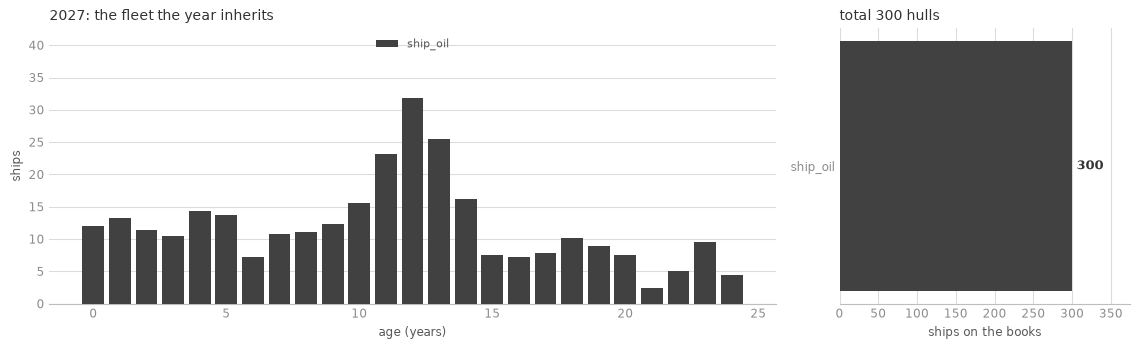

25 live cohorts: decisions are taken per cohort, against that cohort's own remaining life.

this year's regulatory terms:
  eu_ets    unit cost   133.4 USD/ton   limit: no free allowance
  fuel_eu   unit cost   760.0 USD/ton   limit: 89.34 gCO2eq/MJ


In [24]:
# @title Stage 0 figure: what 2027 inherits
# What the year inherits, as two pictures rather than a list. Drawn by a function
# taking a step, so the 2040 section can put the same picture beside this one.

from navigate.illustrations.plots._labels import FUEL_TYPE_ORDER

snap = snaps[STEP_EARLY]          # the year this Part walks


def inherited_cohorts(step):
    """Ships per (age, configuration) that a step OPENS with.

    The probe copies the cohorts out at the END of a step, so snaps[step] would
    already include the ships ordered during the year, which is the opposite of
    what Stage 0 is about. The previous step's snapshot is what it inherits.
    """
    frame = pd.DataFrame(snaps[step - 1]["cohorts"],
                         columns=["configuration", "age", "ships"])
    return frame.pivot_table(index="age", columns="configuration", values="ships",
                             aggfunc="sum", fill_value=0.)


def draw_inherited(step, axes, scale_over=None, legend=True):
    """Stage 0 for one year, into a pair of axes.

    `scale_over` names the steps whose data set the axis limits. Left alone, a
    year scales to itself; the 2040 comparison passes both years so the two rows
    can be read against each other instead of each filling its own panel.
    """
    ax1, ax2 = axes
    steps = tuple(scale_over) if scale_over else (step,)
    by_age = inherited_cohorts(step)

    # stack in Navigate's canonical fuel-type order, restricted to what this deck flies
    stack = sorted(by_age.columns,
                   key=lambda n: FUEL_TYPE_ORDER.index(base.nodes.vessels[n].fuel_type))
    colour = {n: config_colour(n) for n in stack}

    # left: the age structure. Every bar is a cohort the model decides for separately,
    # against that cohort's own remaining life.
    bottom = np.zeros(len(by_age))
    for name in stack:
        values = by_age[name].to_numpy()
        ax1.bar(by_age.index, values, bottom=bottom, width=.82, color=colour[name],
                label=config_label(name), zorder=3)
        bottom += values

    ax1.set_xlabel("age (years)", fontsize=8.5, color=SUBINK)
    ax1.set_ylabel("ships", fontsize=8.5, color=SUBINK)
    ax1.set_title(f"{YEARS[step]}: the fleet the year inherits", fontsize=10,
                  color=INK, loc="left")
    ax1.grid(axis="y", color=GRID, lw=.8)
    # headroom so the legend clears the tallest cohort
    ax1.set_ylim(0, max(inherited_cohorts(s).sum(axis=1).max()
                        for s in steps) * 1.34)
    if legend:
        ax1.legend(fontsize=8, frameon=False, labelcolor=SUBINK, ncol=4,
                   loc="upper center")

    # right: what it adds up to. The numbers are on the bars because two of these
    # colours sit close together for red-green colour blindness.
    totals = by_age[stack].sum()
    ax2.barh(range(len(stack)), totals.to_numpy(), height=.6,
             color=[colour[n] for n in stack], zorder=3)
    for i, name in enumerate(stack):
        ax2.annotate(f"{totals[name]:.0f}", (totals[name] + 6, i), va="center",
                     fontsize=9, color=INK, fontweight="bold")

    ax2.set_yticks(range(len(stack)), [config_label(n) for n in stack])
    ax2.set_xlabel("ships on the books", fontsize=8.5, color=SUBINK)
    ax2.set_title(f"total {totals.sum():.0f} hulls", fontsize=10, color=INK, loc="left")
    ax2.set_xlim(0, max(inherited_cohorts(s).sum().max() for s in steps) * 1.25)
    ax2.invert_yaxis()
    ax2.grid(axis="x", color=GRID, lw=.8)

    for ax in (ax1, ax2):
        ax.set_axisbelow(True)
        ax.tick_params(colors=TICK, labelsize=8.5, length=0)
        for side in ("top", "right", "left"):
            ax.spines[side].set_visible(False)
        ax.spines["bottom"].set_color(AXIS)


fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6),
                         gridspec_kw={"width_ratios": [2.5, 1]})
draw_inherited(STEP_EARLY, axes)
fig.tight_layout()
plt.show()

print(f"{len(snaps[STEP_EARLY - 1]['cohorts'])} live cohorts: decisions are taken "
      f"per cohort, against that cohort's own remaining life.\n")

# two numbers per regulation is not a picture, so these stay as they are
print("this year's regulatory terms:")
for name, reg in snap["regulation"].items():
    limit = "no free allowance" if reg["limit"] == 0 else f"{reg['limit']:.2f} gCO2eq/MJ"
    print(f"  {name:9} unit cost {reg['unit_cost']:7.1f} USD/ton   limit: {limit}")


#### Stage 1 — Look ahead

In this step, the operators calculate the costs of different bunkering strategies for the different available fuels given:
- the expected future compliance costs (induced by regulations)
- the expected fuel costs
- how much of each fuel the ports can supply, and how much fits in the tanks

The operators calculate the expected optimal strategy for the fleet and evaluate: how many tons of which fuel to buy at which port, the cheapest strategy between switching fuel or paying the regulation penalty. It is solved for the whole fleet at once — in fact for every fleet in the simulation — so the ships compete for the same supply. The expenses of new build ships, retrofits, etc. are not considered at this stage yet.

The cheapest bunkering strategy is solved **forward**: one optimisation for each remaining year out to 2050, run one after another.

The step hands a cost path per option to the stages below, and that is what the investment decisions are made on. It produces a second output as well: the **fuel scarcity signal**. For every ship and every leg the optimisation reports the shadow price of energy (what one more unit of energy would have cost). It is the ordinary fuel price when fuel is plentiful and rises above it when the supply is tight. This number is used to act on efficiency and speed decisions for the on-going year.

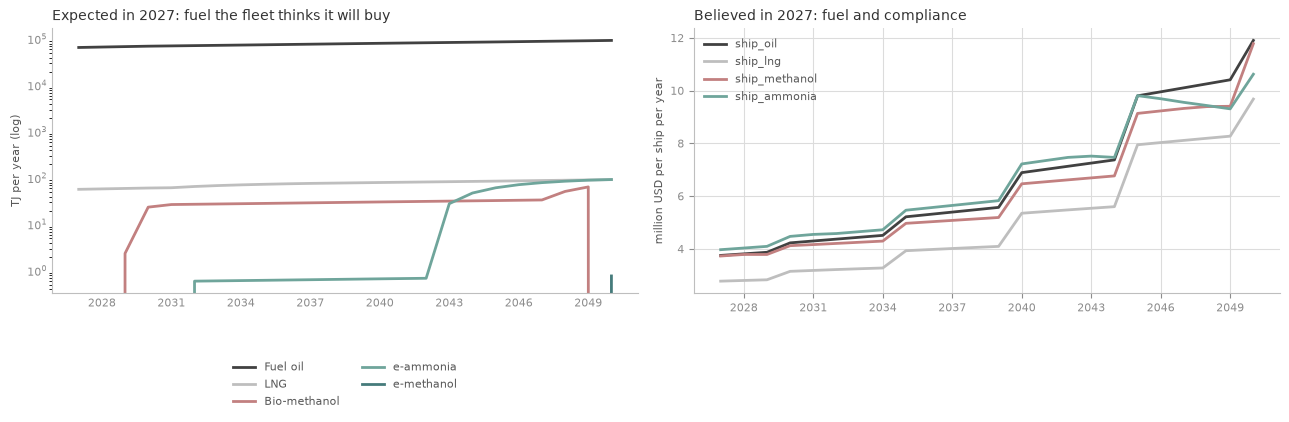

believed cost of missing the mark, this year:
  eu_ets      133.4 USD/ton
  fuel_eu     760.0 USD/ton

Nothing has been decided yet. This is only what the model believes.


In [25]:
# @title Stage 1 figures: what the fleet expects to buy and to pay
from matplotlib.patches import Patch

from navigate.illustrations.plots._labels import FUEL_ORDER
from matplotlib.ticker import MaxNLocator


def label_bill(ax, slices, credit, digits):
    """Print a bill row's numbers so that, as printed, they add up.

    `slices` are (values, starts) pairs in drawing order. Every part that shows
    at `digits` gets its number, the surplus too, and the total after the bar is
    the sum of what is printed: along a row, the parts minus the surplus give
    the total. A part running under the hatching carries its number at the end
    of its extent, as TTW does in the regulation figure; a part too narrow to
    hold its number carries it just above the bar. The surplus's number always
    sits above its hatching, with its minus sign: inside, it would cover the
    fuel number wherever the hatching is narrow.
    """
    fmt = f"{{:.{digits}f}}"
    gross = sum(v for v, _s in slices)
    narrow = .06 * (float(np.max(gross)) or 1.)
    for i in range(len(gross)):
        net = gross[i] - credit[i]
        shown = 0.
        for values, starts in slices:
            v, s = float(values[i]), float(starts[i])
            printed = round(v, digits)
            if printed == 0:
                continue
            shown += printed
            if s + v > net + 1e-9:
                ax.annotate(fmt.format(printed), (s + v, i), xytext=(-3, 0),
                            textcoords="offset points", ha="right", va="center",
                            fontsize=8, fontweight="bold", zorder=6, color=INK,
                            bbox=LABEL_BOX)
            elif v >= narrow:
                ax.annotate(fmt.format(printed), (s + v / 2, i), ha="center",
                            va="center", fontsize=8, fontweight="bold", zorder=5,
                            color="white")
            else:
                ax.annotate(fmt.format(printed), (s + v / 2, i - .3), xytext=(0, 1),
                            textcoords="offset points", ha="center", va="bottom",
                            fontsize=7, color=INK, zorder=6)
        back = round(float(credit[i]), digits)
        if back > 0:
            shown -= back
            ax.annotate("−" + fmt.format(back), (net + credit[i] / 2, i - .3),
                        xytext=(0, 1), textcoords="offset points", ha="center",
                        va="bottom", fontsize=7.5, color=cost_colour("FuelEU"),
                        fontweight="bold", zorder=6)
        ax.annotate(fmt.format(shown), (gross[i], i), xytext=(6, 0),
                    textcoords="offset points", va="center", fontsize=9,
                    color=INK, fontweight="bold")


# The other half of the look-ahead: not what it will cost, but what it expects to buy:
# the fleet's expected demand per fuel for every remaining year, on a log axis because
# oil outweighs the rest by three orders of magnitude. It comes from the snapshot, so it
# does not know how the run turned out.
def expected_demand(step):
    """What the fleet expects to buy per fuel, TJ per year, for the years ahead.

    get_fuel_demand() is a MASS in tons, so energy needs each fuel's own heating
    value rather than one divisor - oil carries 41.2 GJ/t against ammonia's 18.8,
    and dividing them alike would rank them wrongly.
    """
    believed = snaps[step]["fuel_demand"]
    lhv = {f: float(base.nodes.fuels[f].lower_heating_value.get()) for f in believed}
    return pd.DataFrame(
        {f: np.asarray(v, dtype=float) * lhv[f] / 1e3       # tons -> GJ -> TJ
         for f, v in believed.items()},
        index=YEARS[step:])


def draw_expected_demand(step, ax, scale_over=None, legend=True):
    """Stage 1's demand half for one year, into one axis."""
    demand = expected_demand(step)
    for fuel in [f for f in FUEL_ORDER if f in demand.columns and demand[f].sum() > 0]:
        ax.plot(demand.index, demand[fuel], lw=2, color=fuel_colour(fuel),
                label=fuel_label(fuel))
    ax.set_yscale("log")
    ax.set_title(f"Expected in {YEARS[step]}: fuel the fleet thinks it will buy",
                 fontsize=10, color=INK, loc="left")
    ax.set_ylabel("TJ per year (log)", fontsize=8, color=SUBINK)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    # Only when two years are being compared: one log range across both, or each
    # panel fills its own decades and the eye reads no change at all. On its own
    # the panel keeps matplotlib's limits, so this Part draws exactly as before.
    steps = tuple(scale_over) if scale_over else ()
    if len(steps) > 1:
        seen = [v for s in steps
                for v in expected_demand(s).to_numpy().ravel() if v > 0]
        ax.set_ylim(min(seen) * .6, max(seen) * 1.8)
    # no gridlines here: a decade-spanning log axis draws enough minor lines to bury the
    # pale LNG series, and the point of the panel is the ORDER of magnitude, not the value
    if legend:
        ax.legend(fontsize=8, frameon=False, labelcolor=SUBINK, ncol=2,
                  loc="upper center", bbox_to_anchor=(0.5, -0.22))
    ax.set_axisbelow(True)
    ax.tick_params(colors=TICK, labelsize=8, length=0)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)


# what it expects to buy beside what it expects that to cost
fig, (axL, ax1) = plt.subplots(1, 2, figsize=(13, 4.8))
draw_expected_demand(STEP_EARLY, axL)

# what the operators expect each configuration to cost, from this year on
for name in CONFIGS:
    colour = config_colour(name)
    path = snap["operator"][name]["expense_path"] / 1e6
    ax1.plot(YEARS[STEP_EARLY:], path, lw=2, color=colour, label=name)
ax1.set_title(f"Believed in {FOCUS_YEARS[0]}: fuel and compliance", fontsize=10,
              color=INK, loc="left")
ax1.set_ylabel("million USD per ship per year", fontsize=8, color=SUBINK)
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))   # years, not 2030.0
ax1.grid(color=GRID, lw=0.8)
ax1.set_axisbelow(True)
ax1.tick_params(colors=TICK, labelsize=8)
for side in ("top", "right"):
    ax1.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax1.spines[side].set_color(AXIS)
ax1.legend(fontsize=8, frameon=False, labelcolor=SUBINK)

fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

# the only regulation figure that belongs in a look-ahead: what the operators BELIEVE
# a unit of non-compliance will cost. What it ends up buying is settled in Stage 4.
print("believed cost of missing the mark, this year:")
for name, reg in snap["regulation"].items():
    print(f"  {name:9} {reg['unit_cost']:7.1f} USD/ton")
print("\nNothing has been decided yet. This is only what the model believes.")


##### Year by year: what each configuration expects to burn, and why

Each panel in the cell below splits one configuration's expected energy by fuel, for every year of the 2027 look-ahead.
The strip under the bars explains why a dual-fuel ship sometimes expects to burn oil instead of alternative fuels:

- **no alternative fuel on offer**: no port expects any supply of the alternative fuel the ship can burn yet, so oil is the only option
- **alternative capped by supply**: alternative fuel is available but in limited quantities, and the ship buys all of its share
- **alternative on offer, oil still cheaper**: the supply is there, but oil plus the expected compliance cost is cheaper
- **on its main fuel**: oil is down to the minimum pilot share the engine needs

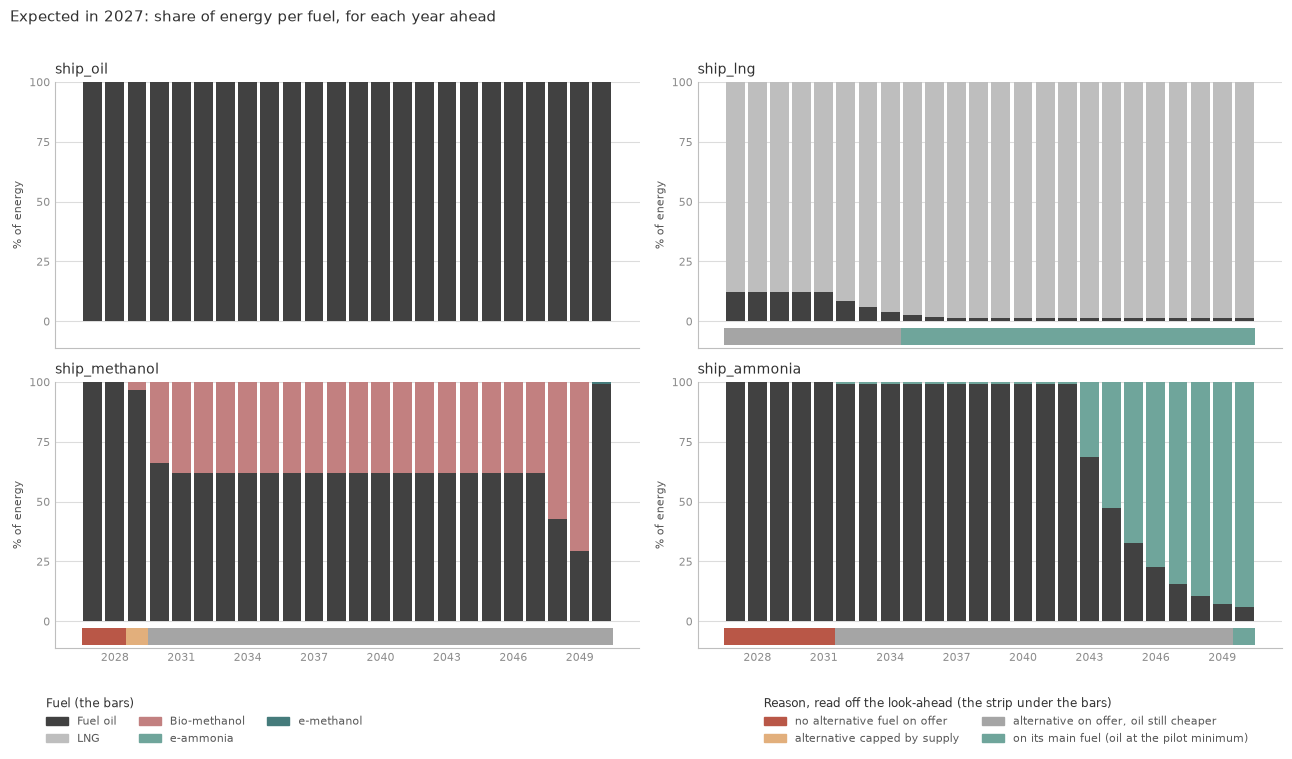

In [26]:
# @title Stage 1 figure: fuel mix per year, and why
# Stage 1, one bar per year of the look-ahead. The strip is read off the LP: the supply
# each port was expected to offer, which of the hull's supply caps bound, and whether
# its dual-fuel engines burn more oil than their minimum pilot share.
from matplotlib.patches import Patch

if "expected_by_year" not in snap:
    raise RuntimeError(
        "These snapshots predate the per-year look-ahead. Re-run the run_case cell "
        "above, then this one.")

REGIMES = {
    "none":    ("no alternative fuel on offer", "#b95747"),   # Red-4
    "capped":  ("alternative capped by supply", "#e2af7c"),   # Orange-3
    "cheaper": ("alternative on offer, oil still cheaper", "#a5a5a5"),   # Black-3
    "main":    ("on its main fuel (oil at the pilot minimum)", "#6fa59b"),   # Green-4
}


def regime(year, name):
    """Why a hull burns what it burns, in one year of the look-ahead."""
    if name not in year["excess_oil"]:
        return None                               # single-fuel engine: no choice
    # within two points: the San Antonio port stay, which no regulation covers,
    # keeps the generators on oil at almost no cost to the hull's fuel mix
    if year["excess_oil"][name] < .02:
        return "main"
    alternatives = [f for f in year["usable"][name] if f != "fossil_fuel_oil"]
    offered = {(p, f) for (p, f), supply in year["supply"].items()
               if f in alternatives and supply > 0}
    if not offered:
        return "none"
    if any(v == name and (p, f) in offered for v, p, f in year["capped"]):
        return "capped"
    return "cheaper"


def draw_mix_by_year(step, axes):
    """Expected share of energy per fuel, each year ahead, one panel per configuration."""
    by_year = snaps[step]["expected_by_year"]
    ks = sorted(by_year)
    years = YEARS[ks]
    lhv = {f: float(base.nodes.fuels[f].lower_heating_value.get()) for f in base.nodes.fuels}
    for ax, name in zip(axes.flat, CONFIGS):
        gj = {f: np.array([by_year[k]["mix"].get((name, f), 0.) * lhv[f] for k in ks])
              for f in FUEL_ORDER if f in lhv}
        total = sum(gj.values())
        bottom = np.zeros(len(ks))
        for fuel, energy in gj.items():
            if energy.sum() == 0:
                continue
            share = np.divide(energy, total, out=np.zeros_like(energy), where=total > 0) * 100
            ax.bar(years, share, bottom=bottom, width=.85, color=fuel_colour(fuel),
                   zorder=3)
            bottom += share
        for year, k in zip(years, ks):
            r = regime(by_year[k], name)
            if r:
                ax.bar(year, 7, bottom=-10, width=1, color=REGIMES[r][1], zorder=3)
        ax.set_title(name, fontsize=10, color=INK, loc="left")
        ax.set_ylim(-11, 100)
        ax.set_yticks([0, 25, 50, 75, 100])
        ax.set_ylabel("% of energy", fontsize=8, color=SUBINK)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(axis="y", color=GRID, lw=0.8)
        ax.set_axisbelow(True)
        ax.tick_params(colors=TICK, labelsize=8, length=0)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color(AXIS)
    return [f for f in gj if any(by_year[k]["mix"].get((n, f), 0.) > 0
                                 for k in ks for n in CONFIGS)]


def mix_legend(fig, fuels):
    """Two legends, kept apart: what the bars show, and what the strip under them says."""
    style = dict(fontsize=8, frameon=False, labelcolor=SUBINK, title_fontsize=8.5,
                 alignment="left")
    for handles, title, ncol, where in (
            ([Patch(color=fuel_colour(f), label=fuel_label(f)) for f in fuels],
             "Fuel (the bars)", 3, (0.03, "lower left")),
            ([Patch(color=c, label=l) for l, c in REGIMES.values()],
             "Reason, read off the look-ahead (the strip under the bars)", 2,
             (0.97, "lower right"))):
        legend = fig.legend(handles=handles, title=title, ncol=ncol, loc=where[1],
                            bbox_to_anchor=(where[0], 0), **style)
        legend.get_title().set_color(INK)


fig, axes = plt.subplots(2, 2, figsize=(13, 7.6), sharex=True)
fuels_drawn = draw_mix_by_year(STEP_EARLY, axes)
fig.suptitle(f"Expected in {YEARS[STEP_EARLY]}: share of energy per fuel, for each year ahead",
             fontsize=11, color=INK, x=0.01, ha="left")
mix_legend(fig, fuels_drawn)
fig.tight_layout(rect=(0, 0.1, 1, 0.97))
plt.show()

##### Year by year: what each configuration expects to pay

The cell below shows what each ship type would be expected to pay each year for fuel and compliance.

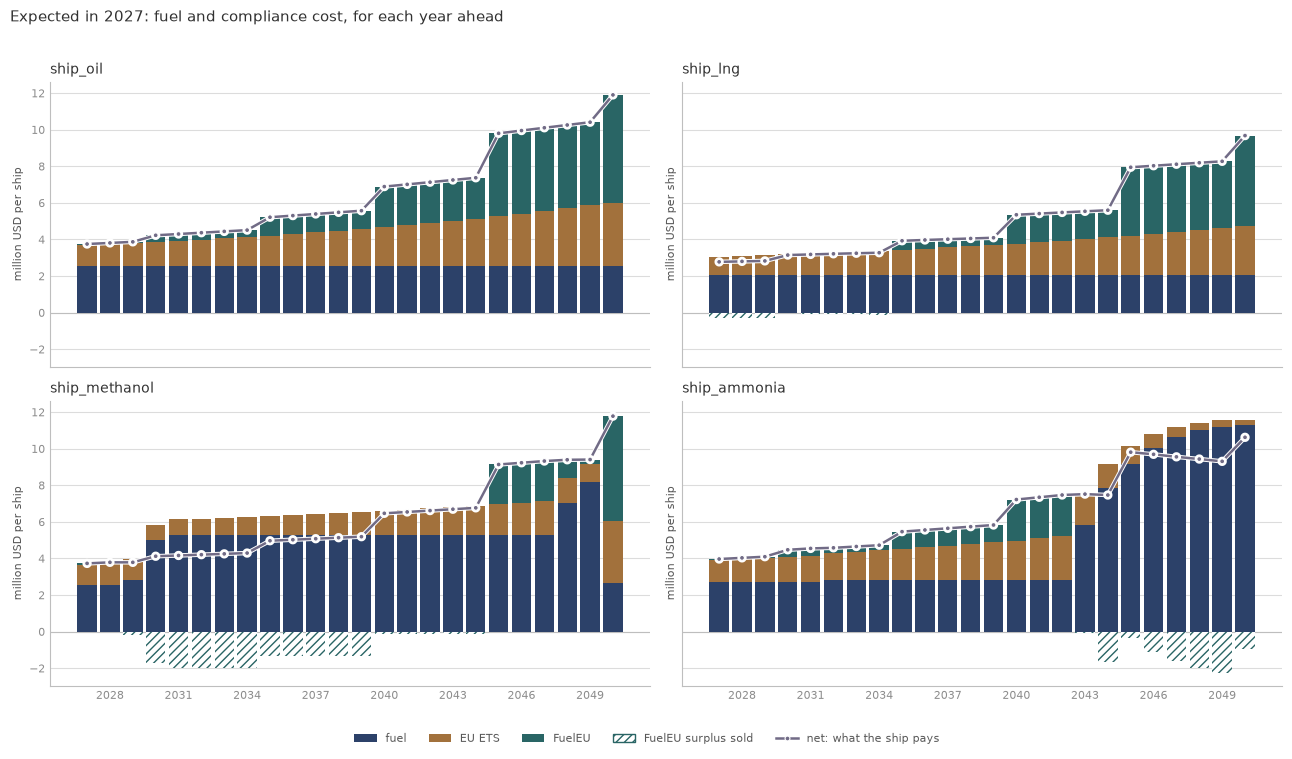

In [27]:
# @title Stage 1 figure: fuel and compliance cost per year
# Stage 1 in money, one bar per year ahead.
from matplotlib import patheffects

REG_LABEL = {"eu_ets": "EU ETS", "fuel_eu": "FuelEU"}
# the net line runs across navy, ochre and teal bars and the white hatching, so it
# takes a colour none of them use, with a white edge to lift it off the bars
NET_COLOUR = "#716b86"   # Purple-7
NET_EDGE = [patheffects.Stroke(linewidth=3.2, foreground="white"), patheffects.Normal()]


def draw_bill_by_year(step, axes):
    """Expected fuel and compliance cost per ship, each year ahead, one panel per configuration."""
    snapshot = snaps[step]
    years = YEARS[step:]
    for ax, name in zip(axes.flat, CONFIGS):
        owed = {REG_LABEL.get(r, r): snapshot["expected_policy"][(name, r)] / 1e6
                for r in base.nodes.regulations}
        parts = [("fuel", snapshot["operator"][name]["fuel_path"] / 1e6)]
        parts += [(label, np.clip(v, 0, None)) for label, v in owed.items()]
        bottom = np.zeros(len(years))
        for part, values in parts:
            ax.bar(years, values, bottom=bottom, width=.85, color=cost_colour(part),
                   zorder=3)
            bottom += values
        credit = sum(np.clip(-v, 0, None) for v in owed.values())
        ax.bar(years, -credit, width=.85, facecolor="white", hatch="////",
               edgecolor=cost_colour("FuelEU"), linewidth=0, zorder=3)
        ax.plot(years, snapshot["operator"][name]["expense_path"] / 1e6, color=NET_COLOUR,
                lw=1.8, marker="o", ms=3.5, mec="white", mew=0.8, zorder=4,
                path_effects=NET_EDGE)
        ax.axhline(0, color=AXIS, lw=0.8, zorder=2)
        ax.set_title(name, fontsize=10, color=INK, loc="left")
        ax.set_ylabel("million USD per ship", fontsize=8, color=SUBINK)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(axis="y", color=GRID, lw=0.8)
        ax.set_axisbelow(True)
        ax.tick_params(colors=TICK, labelsize=8, length=0)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color(AXIS)


def bill_legend(fig):
    fig.legend(handles=[Patch(facecolor=cost_colour("fuel"), label="fuel"),
                        Patch(facecolor=cost_colour("EU ETS"), label="EU ETS"),
                        Patch(facecolor=cost_colour("FuelEU"), label="FuelEU"),
                        Patch(facecolor="white", edgecolor=cost_colour("FuelEU"),
                              hatch="////", label="FuelEU surplus sold"),
                        plt.Line2D([], [], color=NET_COLOUR, lw=1.8, marker="o", ms=3.5,
                                   mec="white", mew=0.8, label="net: what the ship pays")],
               fontsize=8, frameon=False, labelcolor=SUBINK, ncol=5,
               loc="lower center", bbox_to_anchor=(0.5, 0))


fig, axes = plt.subplots(2, 2, figsize=(13, 7.6), sharex=True, sharey=True)
draw_bill_by_year(STEP_EARLY, axes)
fig.suptitle(f"Expected in {YEARS[STEP_EARLY]}: fuel and compliance cost, for each year ahead",
             fontsize=11, color=INK, x=0.01, ha="left")
bill_legend(fig)
fig.tight_layout(rect=(0, 0.05, 1, 0.97))
plt.show()

#### Stage 2 — Decide

The decisions of the owners and the operators are taken in this order, based on the beliefs formed
in the previous stage:

1. **Technology** (owners): equipment fitted to a ship to reduce its fuel consumption
2. **Speed** (operators): how fast to sail, within the band the deck allows
3. **The scorecard** (owners): an investment freight rate per configuration, which
   sets each configuration's share of the newbuilds: the lower the rate, the larger
   the share
4. **The fleet** (owners): scrap the oldest hulls, retrofit hulls to another fuel when
   the conversion pays, and order newbuilds on the scorecard

Not every newbuild follows the scorecard, i.e. the business case. Each year, 60 % of
them copy the previous year's mix of ship types: this is the fleet's `Inertia`.

The starting fleet is all oil, so most of the ships ordered in the first year are oil
ships because of the inertia, even when another ship type is cheaper on paper.

##### The technology ladder

The owners do not decide on each efficiency measure separately. Navigate sorts the
measures by CAPEX, cheapest first (ties keep the order the deck lists them in), and
builds a **ladder** of cumulative packages: no measure, the cheapest one, the two
cheapest, and so on up to all seven. The owners choose between these packages, so a
ship that fits a measure also fits every cheaper measure:

- a **newbuild** can take any package. Each package gets a share of the newbuilds by
  its NPV: the energy it saves, valued at the investment signal, minus its CAPEX and
  OPEX
- an **existing ship**, at its five-yearly retrofit cycle, can only climb from the
  package it already has: it stays where it is, or adds one or more of the next
  measures

The ladder in this deck, from the cheapest measure up:

exhaust-gas boiler → lighting system → variable frequency drive → propeller
improvement devices → hull painting → air lubrication → Flettner rotor

The figures below list the measures in this order. In the first one, the right panel
shows what each measure adds on top of the cheaper measures. A measure with a negative
value is still fitted to every ship that takes a dearer measure further down the
ladder. In panel 1 of the four decisions, the share of the fleet with a measure
fitted can only fall going down the list.

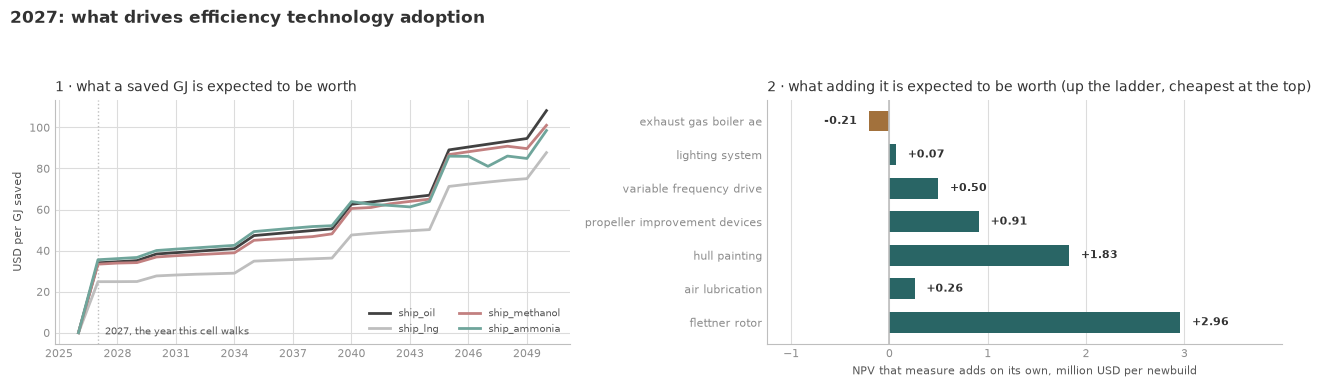

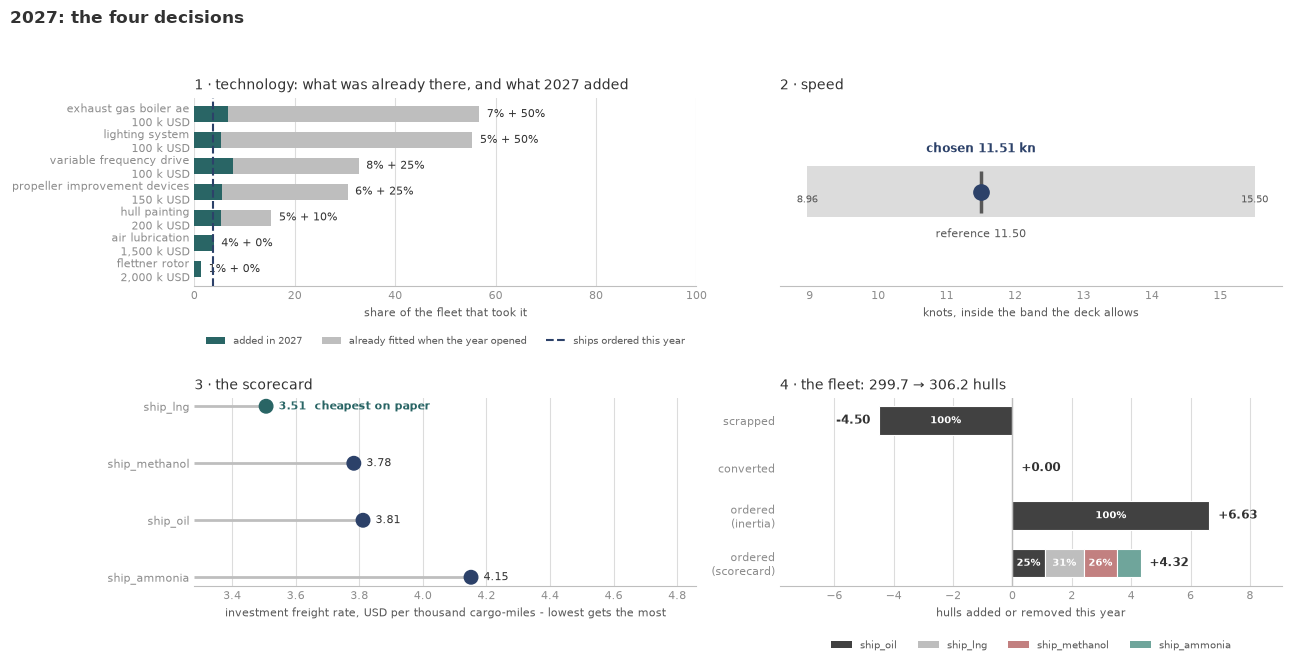

In [28]:
# @title Stage 2 figures: the four decisions
# The four levers Stage 2 pulls, side by side. Each panel is one decision, taken
# on this year's beliefs, in the order the list above gives.
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

from navigate.illustrations.plots._labels import FUEL_TYPE_ORDER
from matplotlib.ticker import MaxNLocator

def flow_by_config(getter, step, credit_destination=False):
    """One flow, split by vessel configuration.

    Conversions are keyed (from, to) rather than by a single name, so credit the
    hull to what it BECOMES and drop the same-to-same entries, which are not
    conversions at all. Scrapping and newbuilds are keyed by name already.
    """
    out = {}
    for key, value in at(getter, step).items():
        if isinstance(key, tuple):
            source, destination = key
            if source == destination:
                continue
            name = destination if credit_destination else source
        else:
            name = key
        out[name] = out.get(name, 0.) + value
    return out


def fleet_technology_uptake(profile):
    """Share of the FLEET with each technology fitted, 0 to 1, per year.

    get_technology_uptake() is keyed by (vessel, technology) and each entry is
    that CONFIGURATION's share, so summed across four configurations it can
    exceed 1. Weighting each configuration by its hulls gives the fleet share,
    as Navigate's own technology_uptake plot does.
    """
    hulls = {v: np.nan_to_num(np.asarray(n, dtype=float))
             for v, n in profile.get_existing_vessels().items()}
    shares, weights = {}, {}
    for (vessel, tech), share in profile.get_technology_uptake().items():
        w = hulls.get(vessel, 0.)
        shares[tech] = shares.get(tech, 0.) + w * np.nan_to_num(np.asarray(share, dtype=float))
        weights[tech] = weights.get(tech, 0.) + w
    return {tech: np.divide(shares[tech], weights[tech],
                            out=np.zeros_like(shares[tech]), where=weights[tech] > 0)
            for tech in shares}


def stage2_state(step):
    """Everything the four levers decided in one step, and what drove lever 1."""
    # lever 1: technology, as the FLEET share of each measure, 0 to 1.
    series_ = fleet_technology_uptake(copper_trade.profile)

    def share_at(idx):
        return {name.replace("_bulk_carrier_panamax", ""):
                float(np.nan_to_num(np.asarray(s, dtype=float))[idx])
                for name, s in series_.items()}

    uptake = share_at(step)
    # what the fleet ALREADY had when the year opened, from the library's observed
    # world-fleet shares. The difference is all this year's decision actually did.
    inherited = share_at(step - 1)

    # lever 2: speed
    speed = {k: total_at(getattr(copper_trade.profile, f"get_{k}_speed"), step)
             for k in ("actual", "reference", "minimum", "maximum")}

    # lever 3: the scorecard the newbuild choice is made on
    scores = {name: float(np.nan_to_num(
                  vessel.profile.get_investment_freight_rate(idx=step)))
              for name, vessel in base.nodes.vessels.items()
              if vessel.profile.is_active(step)}

    # lever 4: the fleet, in perform_fleet_evolution's own order
    scrap_by = flow_by_config(copper_trade.profile.get_scrap, step)
    convert_by = flow_by_config(copper_trade.profile.get_fuel_conversions, step,
                                credit_destination=True)
    order_by = flow_by_config(copper_trade.profile.get_newbuilds, step)
    # the same orders split by why they were placed. The profile keeps the three
    # sources apart; the orderbook is empty in this deck, so it is dropped when
    # it adds nothing.
    order_split = [(label, flow_by_config(getter, step)) for label, getter in (
        ("ordered\n(orderbook)", copper_trade.profile.get_orderbook_newbuilds),
        ("ordered\n(inertia)", copper_trade.profile.get_inertia_newbuilds),
        ("ordered\n(scorecard)", copper_trade.profile.get_modelled_newbuilds))]
    order_split = [(label, parts) for label, parts in order_split
                   if "orderbook" not in label
                   or any(abs(v) > 1e-9 for v in parts.values())]
    scrapped = sum(scrap_by.values())
    ordered = sum(order_by.values())
    opening = sum(at(copper_trade.profile.get_existing_vessels, step - 1).values())
    closing = sum(at(copper_trade.profile.get_existing_vessels, step).values())
    assert abs(opening - scrapped + ordered - closing) < 1e-6, \
        "the waterfall does not close"

    # how lever 1 actually chose. Two numbers decide it: what a saved GJ is WORTH
    # - the bunkering LP's energy dual, smoothed into an investment signal - and
    # what each technology COSTS to install. A package is bought when the first,
    # applied to the energy it saves, beats the second; and the choice is
    # odds-based against doing nothing, so a technology that only just pays gets
    # some of the fleet rather than all of it.
    signal_path = {n: np.nan_to_num(np.asarray(
                       base.nodes.vessels[n].profile.get_investment_signal_technology(),
                       dtype=float)) for n in CONFIGS}

    when = base.get_timeline()[step]

    def limit_now(node):
        """A technology limit is a Scalar for most, a Forecast for a gated one."""
        try:
            return float(np.nan_to_num(np.asarray(node.get(when), dtype=float)))
        except TypeError:
            return float(np.nan_to_num(np.asarray(node.get(), dtype=float)))

    # in the ladder's order, the model's own: cheapest first, ties as in the deck
    tech_rows = []
    for tech in copper_trade.technology_packages[-1].technologies:
        full = tech.get_name()
        name = full.replace("_bulk_carrier_panamax", "")
        offered = max(limit_now(copper_trade.newbuild_technology_limit[full]),
                      limit_now(copper_trade.retrofit_technology_limit[full])) > 0.
        tech_rows.append((name, float(tech.CAPEX.get()), uptake.get(name, 0.) * 100,
                          offered, inherited.get(name, 0.) * 100))

    return {"uptake": uptake, "inherited": inherited, "speed": speed,
            "scores": scores, "scrap_by": scrap_by, "convert_by": convert_by,
            "order_by": order_by, "order_split": order_split,
            "scrapped": scrapped,
            "converted": sum(convert_by.values()), "ordered": ordered,
            "opening": opening, "closing": closing,
            "signal_path": signal_path, "tech_rows": tech_rows}


# the year this Part walks: its signal path is what the figure below draws
signal_path = stage2_state(STEP_EARLY)["signal_path"]

fig2, (axV, axW) = plt.subplots(1, 2, figsize=(13, 3.9))
fig2.suptitle(f"{FOCUS_YEARS[0]}: what drives efficiency technology adoption",
              fontsize=12, color=INK, x=0.01, ha="left", fontweight="bold")

# left: the price the whole lever turns on, over the whole horizon rather than
# at a couple of years - the SHAPE is the point, since a technology bought now is
# paid for once and earns against this curve for the rest of its life.
for name in CONFIGS:
    axV.plot(YEARS, signal_path[name], lw=2, color=config_colour(name), label=name,
             zorder=3)
axV.axvline(YEARS[STEP_EARLY], color=AXIS, lw=1, ls=":", zorder=2)
axV.annotate(f"{FOCUS_YEARS[0]}, the year this cell walks",
             (YEARS[STEP_EARLY], axV.get_ylim()[0]), xytext=(5, 5),
             textcoords="offset points", fontsize=7.5, color=SUBINK, va="bottom")
axV.set_ylabel("USD per GJ saved", fontsize=8, color=SUBINK)
axV.xaxis.set_major_locator(MaxNLocator(integer=True))
axV.set_title("1 · what a saved GJ is expected to be worth", fontsize=10, color=INK, loc="left")
axV.grid(color=GRID, lw=0.8)
axV.legend(fontsize=7.5, frameon=False, labelcolor=SUBINK, ncol=2, loc="lower right")

# right: what ADDING each measure is worth on its own. The model works in
# cumulative packages, up the ladder, so the value of one measure is the step
# between two of them - a subtraction of numbers the model produced, nothing
# recomputed.
_npv = snap.get("npv_newbuild", [])
_order = snap.get("asset_order", [])
_ladder = snap.get("ladder", [])
if not _npv or not _ladder:
    raise RuntimeError(
        "These snapshots predate the NPV hook. Re-run the run_case cell above, "
        "then this one.")
_pick = _order.index(CONFIGS[0]) if CONFIGS[0] in _order else 0
_steps = np.diff(np.asarray(_npv[_pick], dtype=float)) / 1e6
_step_names = [name for _capex, name in _ladder[1:]]

axW.barh(range(len(_steps)), _steps, height=.62, zorder=3,
         color=[GREEN if v > 0 else ORANGE for v in _steps])
for _i, _v in enumerate(_steps):
    axW.annotate(f"{_v:+.2f}", (_v + (.12 if _v >= 0 else -.12), _i), va="center",
                 ha="left" if _v >= 0 else "right", fontsize=8,
                 color=INK, fontweight="bold")
axW.set_yticks(range(len(_steps)),
               [n.replace("_", " ") for n in _step_names])
axW.invert_yaxis()
axW.axvline(0, color=AXIS, lw=1.2, zorder=4)
_pad = max(abs(_steps.min()), abs(_steps.max())) * .35 if _steps.size else 1.
axW.set_xlim(_steps.min() - _pad, _steps.max() + _pad)
axW.set_xlabel("NPV that measure adds on its own, million USD per newbuild",
               fontsize=8, color=SUBINK)
axW.set_title("2 · what adding it is expected to be worth (up the ladder, cheapest at the top)",
              fontsize=10, color=INK, loc="left")
axW.grid(axis="x", color=GRID, lw=0.8)

for ax in (axV, axW):
    ax.set_axisbelow(True)
    ax.tick_params(colors=TICK, labelsize=8, length=0)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("bottom", "left"):
        ax.spines[side].set_color(AXIS)

fig2.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()


def draw_four_decisions(step, axes, scale_over=None, legend=True):
    """Stage 2's four levers for one year, into four axes (technology, speed,
    scorecard, fleet).

    `scale_over` shares the speed band and the fleet-flow axis across the years
    given. The SCORECARD is deliberately left out of it: its numbers sit close
    together, and one axis across thirteen years would flatten each year's
    spread into a single dot.
    """
    axT, axS, axC, axF = axes
    state = stage2_state(step)
    steps = tuple(scale_over) if scale_over else (step,)
    peers = [stage2_state(s) for s in steps]
    rows_, speed_ = state["tech_rows"], state["speed"]

    # 1 - technology: up the ladder, what it costs and who took it
    labels_ = [r[0].replace("_", " ") for r in rows_]
    had = [r[4] for r in rows_]
    added = [r[2] - r[4] for r in rows_]
    axT.barh(range(len(rows_)), added, height=.62, color=GREEN, zorder=3,
             label=f"added in {YEARS[step]}")
    axT.barh(range(len(rows_)), had, left=added, height=.62, color=MUTED,
             zorder=3, label="already fitted when the year opened")
    for i, (_name, _capex, share, _offered, was) in enumerate(rows_):
        axT.annotate(f"{share - was:.0f}% + {was:.0f}%", (share + 1.5, i), va="center",
                     fontsize=8, color=INK)
    # Ships ordered this year, as a share of the fleet. A measure whose green slice
    # stops at this line was taken by the newbuilds and by nobody else - which is the
    # whole difference between a fleet-wide share and the per-newbuild NPV opposite.
    axT.axvline(state["ordered"] / state["opening"] * 100, color=BLUE, lw=1.5,
                ls="--", zorder=5)
    if legend:
        axT.legend(handles=[Patch(facecolor=GREEN, label=f"added in {YEARS[step]}"),
                            Patch(facecolor=MUTED,
                                  label="already fitted when the year opened"),
                            Line2D([], [], color=BLUE, lw=1.5, ls="--",
                                   label="ships ordered this year")],
                   fontsize=7, frameon=False, labelcolor=SUBINK, ncol=3,
                   loc="upper center", bbox_to_anchor=(0.5, -0.22))
    axT.set_yticks(range(len(rows_)),
                   [f"{l}\n{r[1] / 1e3:,.0f} k USD" for l, r in zip(labels_, rows_)])
    axT.invert_yaxis()
    axT.set_xlim(0, 100)
    axT.set_xlabel("share of the fleet that took it", fontsize=8, color=SUBINK)
    axT.set_title("1 \u00b7 technology: what was already there, and what {} added"
                  .format(YEARS[step]), fontsize=10, color=INK, loc="left")
    axT.grid(axis="x", color=GRID, lw=0.8)

    # 2 - speed, against the band the deck allows
    axS.barh([0], [speed_["maximum"] - speed_["minimum"]], left=speed_["minimum"],
             height=.34, color=PALE, zorder=2)
    axS.plot([speed_["reference"]], [0], marker="|", ms=30, mew=2.5, color=SUBINK,
             zorder=4)
    axS.plot([speed_["actual"]], [0], marker="o", ms=11, color=BLUE, zorder=5)
    axS.annotate(f"chosen {speed_['actual']:.2f} kn", (speed_["actual"], .26),
                 ha="center", fontsize=8.5, color=BLUE, fontweight="bold")
    axS.annotate(f"reference {speed_['reference']:.2f}", (speed_["reference"], -.30),
                 ha="center", fontsize=8, color=SUBINK)
    for edge in ("minimum", "maximum"):
        axS.annotate(f"{speed_[edge]:.2f}", (speed_[edge], 0), xytext=(0, -2),
                     textcoords="offset points", ha="center", va="top", fontsize=7.5,
                     color=SUBINK)
    axS.set_xlim(min(p["speed"]["minimum"] for p in peers) - .4,
                 max(p["speed"]["maximum"] for p in peers) + .4)
    axS.set_ylim(-.62, .62)
    axS.set_yticks([])
    axS.set_xlabel("knots, inside the band the deck allows", fontsize=8, color=SUBINK)
    axS.set_title("2 \u00b7 speed", fontsize=10, color=INK, loc="left")

    # 3 - the scorecard. A dot plot, because these differ only slightly and bars
    # from zero would hide the whole story. Scaled to ITS OWN year, on purpose.
    # Per THOUSAND cargo-miles, as everywhere else in the workshop.
    scores_ = state["scores"]
    order_ = sorted(scores_, key=scores_.get)
    vals = [1e3 * scores_[n] for n in order_]
    best, worst = min(vals), max(vals)
    floor = best - (worst - best) * .35
    axC.hlines(range(len(order_)), floor, vals, color=MUTED, lw=2, zorder=2)
    axC.scatter(vals, range(len(order_)), s=95, zorder=4,
                color=[GREEN if v == best else BLUE for v in vals])
    for i, v in enumerate(vals):
        axC.annotate(f"{v:.2f}" + ("  cheapest on paper" if v == best else ""),
                     (v, i), xytext=(9, 0), textcoords="offset points", va="center",
                     fontsize=8, color=GREEN if v == best else INK,
                     fontweight="bold" if v == best else "normal")
    axC.set_yticks(range(len(order_)), order_)
    axC.invert_yaxis()
    axC.set_xlim(floor, worst + (worst - best) * 1.1)
    axC.set_xlabel("investment freight rate, USD per thousand cargo-miles - lowest gets the most",
                   fontsize=8, color=SUBINK)
    axC.set_title("3 \u00b7 the scorecard", fontsize=10, color=INK, loc="left")
    axC.grid(axis="x", color=GRID, lw=0.8)

    # 4 - the fleet. Only the FLOWS are drawn: opening and closing differ by about 2%,
    # so a stock-on-stock waterfall would show four bars of the same apparent height.
    # Each bar is split by configuration, in Stage 0's colours, because WHICH hulls
    # leave and which arrive is the whole point of the lever.
    hue = {n: config_colour(n) for n in CONFIGS}
    stack_ = sorted(CONFIGS,
                    key=lambda n: FUEL_TYPE_ORDER.index(base.nodes.vessels[n].fuel_type))

    def flows_of(s):
        # the orders come in two rows: those copying last year's mix (the fleet's
        # Inertia) and those the scorecard placed
        return [("scrapped", {n: -v for n, v in s["scrap_by"].items()}),
                ("converted", s["convert_by"])] + s["order_split"]

    flows_ = flows_of(state)
    # the value labels sit outside their bars, so the axis needs slack at both ends
    # or "-4.50" lands on top of the "scrapped" tick label. Worked out before the
    # bars are drawn, because the share labels are judged against it.
    every = [sum(parts.values()) for p in peers for _l, parts in flows_of(p)]
    lo, hi = min(0., min(every)), max(0., max(every))
    span = (hi - lo) or 1.
    axF.set_xlim(lo - span * .30, hi + span * .22)
    axis_width = span * 1.52

    for i, (_label, parts) in enumerate(flows_):
        run_pos = run_neg = 0.
        row_total = sum(parts.values()) or 1.
        for name in stack_:
            value = parts.get(name, 0.)
            if abs(value) < 1e-9:
                continue
            start = run_pos if value > 0 else run_neg
            axF.barh(i, value, left=start, height=.6, color=hue[name],
                     zorder=3, edgecolor="white", linewidth=.8)
            # the share of THIS flow, so the reader can see that scrapping is all one
            # configuration while ordering is spread across every one of them
            share = abs(value) / abs(row_total) * 100
            # a slice worth 29% of its row is still unreadable if the row is 3% of
            # the axis, which is what happens once both years share one scale
            if share >= 10 and abs(value) / axis_width >= 0.05:
                axF.annotate(f"{share:.0f}%", (start + value / 2, i), ha="center",
                             va="center", fontsize=7.5, color="white",
                             fontweight="bold", zorder=5)
            if value > 0:
                run_pos += value
            else:
                run_neg += value

    for i, (_label, parts) in enumerate(flows_):
        total = sum(parts.values())
        axF.annotate(f"{total:+.2f}", (total + (.3 if total >= 0 else -.3), i),
                     va="center", ha="left" if total >= 0 else "right", fontsize=8.5,
                     fontweight="bold", color=INK)
    axF.set_yticks(range(len(flows_)), [f[0] for f in flows_])
    axF.invert_yaxis()
    axF.axvline(0, color=AXIS, lw=1, zorder=4)
    axF.set_xlabel("hulls added or removed this year", fontsize=8, color=SUBINK)
    axF.set_title(f"4 \u00b7 the fleet: {state['opening']:,.1f} \u2192 "
                  f"{state['closing']:,.1f} hulls",
                  fontsize=10, color=INK, loc="left")
    axF.grid(axis="x", color=GRID, lw=0.8)
    moved = [n for n in stack_
             if any(abs(parts.get(n, 0.)) > 1e-9 for _l, parts in flows_)]
    if moved and legend:
        axF.legend(handles=[Patch(facecolor=hue[n], label=n) for n in moved],
                   fontsize=7.5, frameon=False, labelcolor=SUBINK,
                   ncol=min(len(moved), 4),
                   loc="upper center", bbox_to_anchor=(0.5, -0.24))

    for ax in (axT, axS, axC, axF):
        ax.set_axisbelow(True)
        ax.tick_params(colors=TICK, labelsize=8, length=0)
        for side in ("top", "right", "left"):
            ax.spines[side].set_visible(False)
        ax.spines["bottom"].set_color(AXIS)


fig, ((axT, axS), (axC, axF)) = plt.subplots(2, 2, figsize=(13, 7.1))
fig.suptitle(f"{FOCUS_YEARS[0]}: the four decisions", fontsize=12, color=INK,
             x=0.01, ha="left", fontweight="bold")
draw_four_decisions(STEP_EARLY, (axT, axS, axC, axF))
fig.tight_layout(rect=(0, 0.03, 1, 0.95))
plt.show()


#### What the fleet looks like now

The cell below shows what the fleet looks like at the end of the year (by age) after scrapping the old ships and ordering the new ones. 

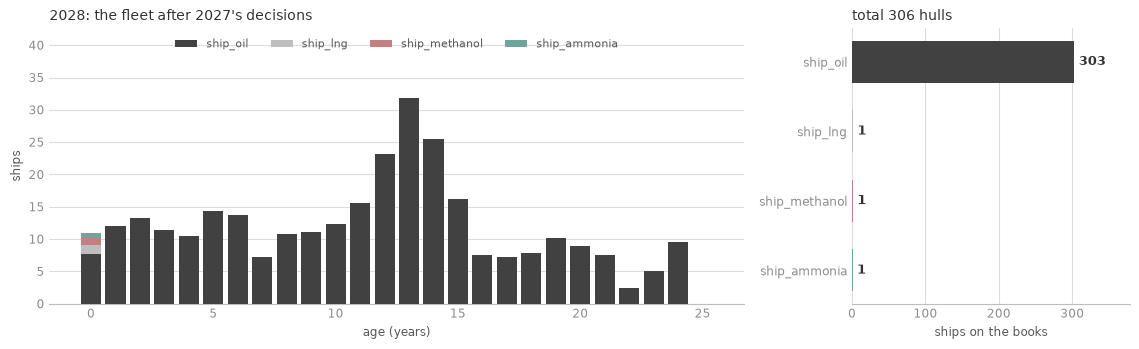

In [29]:
# @title Figure: the fleet after 2027's decisions
# Stage 0's own function, one step later: what 2028 inherits is what 2027 decided.
# Scaled with 2027, so the change between the two figures is the decision.
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6),
                         gridspec_kw={"width_ratios": [2.5, 1]})
draw_inherited(STEP_EARLY + 1, axes, scale_over=(STEP_EARLY, STEP_EARLY + 1))
axes[0].set_title(f"{YEARS[STEP_EARLY + 1]}: the fleet after {FOCUS_YEARS[0]}'s decisions",
                  fontsize=10, color=INK, loc="left")
fig.tight_layout()
plt.show()

#### Stage 3 — The producers decide too

The fuel producers act after the fleet owners and operators. First, old plants retire and finished plants start producing. Then their step has the same structure: look ahead, decide, and commit.

In the model, the producers aim to fill the expected unmet demand for each fuel, as far as their build limit and feedstock allow.

1. **Look ahead**:
   - **Expected unmet demand**: for each fuel and each year ahead, the producers take what the fleet operators expect to buy and subtract what the existing plants and the plants under construction will make. What is left is the expected unmet demand.
2. **Decide** which plants to start, and how many:
   - **Repeat**: as for the ships, part of the build repeats last year's (`Inertia`):
     60 % of last year's plants, in the same mix, and their output is taken off the
     expected unmet demand.
   - **Score**: the fuel producers score how "demanded" each fuel plant is: the average expected unmet demand for its fuel over the plant lifetime, discounted so the first years count most.
   - **Choose**: the rest of the year's build is shared out: between fuels by score (`FuelDemandSensitivity`), and between plants of the same fuel (with different processes) by delivered cost (`FuelCostSensitivity`).
   - **Build**: each plant gets its share of the year's build limit
     (`MaximumDevelopment`), capped by the feedstock left and by the expected unmet demand in the year it opens.
3. **Commit**: the plants started cannot be cancelled, and running plants produce at full capacity whatever the fleet operators end up buying. The producers then publish a new supply outlook (running plants, plants under construction and the plants they expect to add later), which becomes each port's fuel supply and sets its price.

Check <a href="https://github.com/zerocarbonshipping/navigate-zcs/blob/dev-workshop/navigate/fuel/supply_demand.py" target="_blank"><code>navigate/fuel/supply_demand.py</code></a> and <a href="https://github.com/zerocarbonshipping/navigate-zcs/blob/dev-workshop/navigate/fuel/producer/producer_planning.py" target="_blank"><code>navigate/fuel/producer/producer_planning.py</code></a> for more details.

##### 1. Look ahead: the expected unmet demand

The demand is the one the fleet operators expected in Stage 1, and the supply the
producers' own projection from the end of the previous year. The lag is intentional:
the producers act before the owners' newbuilds and retrofits decisions.

In the figure below, the solid line is the demand the producers see this year for
the years ahead, the dashed line what their running and ordered plants will supply,
and the shaded area between them the expected unmet demand.

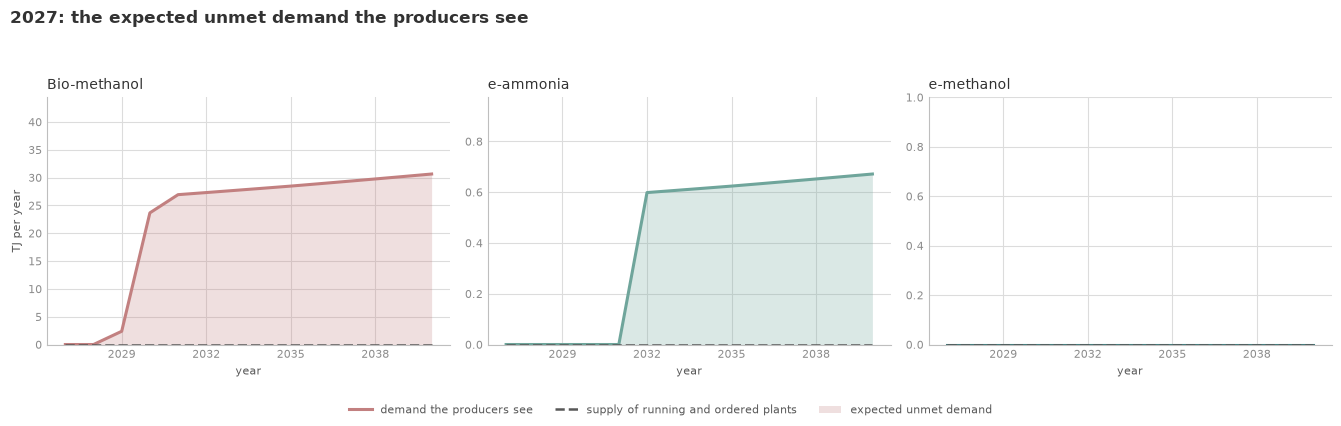

In [30]:
# @title Stage 3 figure: look ahead, the expected unmet demand
from matplotlib.colors import to_rgba
from matplotlib.transforms import blended_transform_factory

if "producer_balance" not in snap or "plant_cohorts" not in snap:
    raise RuntimeError(
        "These snapshots predate the producer records. Re-run the run_case "
        "cell above, then this one.")

PLACE = {"americas": "Chile", "europe": "Europe"}

# One panel per fuel the producers can make, in Navigate's own fuel order.
PRODUCED = fuel_sorted({base.nodes.plants[p].fuel.get_name() for p in snap["producer"]})


def _style(ax):
    ax.grid(color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TICK, labelsize=8, length=0)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)


def draw_supply_demand(step, axes, show_plant=True):
    """Steps 2, 4 and 6 for one year, one panel per fuel.

    Demand and supply are what the producers saw just before they planned: the
    supply of their running and ordered plants, and demand as that supply plus
    their shares of the gap. The bar is a new plant's lead time, and the dot what
    one plant started this year adds when it opens: the gap in its opening year
    (MinimumOfftakeDuration, one year by default, sets that window).
    With show_plant=False only the look-ahead is drawn: demand, supply, the gap.
    """
    seen = snaps[step]["producer"]
    balance = snaps[step]["producer_balance"]
    year = YEARS[step]
    stop = min(len(YEARS), step + 14)
    ahead = YEARS[step:stop]
    for ax, fuel in zip(axes, PRODUCED):
        lhv = float(base.nodes.fuels[fuel].lower_heating_value.get())
        mine = [v for (_owner, f), v in balance.items() if f == fuel]
        supply = sum(v["supply"] for v in mine)[step:stop] * lhv / 1e3
        demand = supply + sum(v["gap"] for v in mine)[step:stop] * lhv / 1e3
        colour = fuel_colour(fuel)

        ax.plot(ahead, demand, lw=2.2, color=colour, zorder=3,
                label="demand the producers see")
        ax.plot(ahead, supply, lw=1.8, color=SUBINK, ls="--", zorder=3,
                label="supply of running and ordered plants")
        ax.fill_between(ahead, supply, demand, where=demand > supply, interpolate=True, color=colour,
                        alpha=.25, linewidth=0, zorder=2, label="expected unmet demand")

        plants_ = [p for p in seen if base.nodes.plants[p].fuel.get_name() == fuel]
        d = seen[plants_[0]]
        lead = int(round(d["lead_time"]))
        opens = year + lead
        size = max(seen[p]["plants_built"] * seen[p]["plant_output"] * seen[p]["lhv"] / 1e3
                   for p in plants_)
        top = max(float(np.nanmax(demand)), float(np.nanmax(supply)))
        ax.set_ylim(0, top * 1.45 if top > 0.05 else 1.)

        if show_plant:
            band = blended_transform_factory(ax.transData, ax.transAxes)
            ax.barh(0.06, lead, left=year, height=0.07, transform=band, color=colour,
                    alpha=.35, zorder=2)
            ax.annotate(f"{lead} yr to build", (year + lead / 2, 0.06), xycoords=band,
                        ha="center", va="center", fontsize=8, color=INK)

            if size > 0.05 and opens <= ahead[-1]:
                base_ = float(supply[lead])
                ax.plot([opens] * 2, [base_, base_ + size], lw=3, color=colour, zorder=4,
                        solid_capstyle="butt")
                ax.plot(opens, base_ + size, "o", ms=9, color=colour,
                        markeredgecolor="white", markeredgewidth=1.5, zorder=5)
                ax.annotate(f"opens {opens}:\n+{size:,.1f} TJ/yr", (opens, base_ + size),
                            textcoords="offset points", xytext=(8, 6), fontsize=8.5,
                            color=INK, fontweight="bold")
            else:
                gap_open = float(demand[lead] - supply[lead]) if lead < len(ahead) else 0.
                ax.annotate("no unmet demand when it\nwould open: nothing started"
                            if gap_open < 0.05 else "nothing started",
                            (0.04, 0.8), xycoords="axes fraction", ha="left",
                            fontsize=8.5, color=SUBINK)

        ax.set_title(fuel_label(fuel), fontsize=10, color=INK, loc="left")
        ax.set_xlabel("year", fontsize=8, color=SUBINK)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=5))
        _style(ax)
    axes[0].set_ylabel("TJ per year", fontsize=8, color=SUBINK)
    return axes[0].get_legend_handles_labels()


def plant_cohorts(step):
    """TJ/yr per (age, plant) at the END of a step: after its decisions.

    Ages are whole years. A plant still under construction has a negative age,
    the years until it opens.
    """
    frame = pd.DataFrame(snaps[step]["plant_cohorts"], columns=["plant", "age", "tj"])
    if frame.empty:
        return frame
    frame["age"] = np.round(frame["age"]).astype(int)
    return frame.pivot_table(index="age", columns="plant", values="tj",
                             aggfunc="sum", fill_value=0.)


def draw_plants(step, axes, scale_over=None, legend=True):
    """The plants after a year's decisions, the way Stage 0 draws the fleet."""
    ax1, ax2 = axes
    steps = tuple(scale_over) if scale_over else (step,)
    by_age = plant_cohorts(step)
    plants_ = sorted(base.nodes.plants, key=lambda p: (
        PRODUCED.index(base.nodes.plants[p].fuel.get_name()),
        base.nodes.plants[p].region.get_name()))

    def colour_of(p):
        return fuel_colour(base.nodes.plants[p].fuel.get_name())

    def label(p):
        plant = base.nodes.plants[p]
        return (f"{fuel_label(plant.fuel.get_name())} · "
                f"{PLACE.get(plant.region.get_name(), plant.region.get_name())}")

    # left: one stack per fuel; the right panel tells the sites apart
    if not by_age.empty:
        bottom = np.zeros(len(by_age))
        for fuel in PRODUCED:
            members = [p for p in plants_ if p in by_age
                       and base.nodes.plants[p].fuel.get_name() == fuel]
            if not members:
                continue
            values = by_age[members].sum(axis=1).to_numpy()
            ax1.bar(by_age.index, values, bottom=bottom, width=.82,
                    color=fuel_colour(fuel), edgecolor="white", linewidth=.6,
                    label=fuel_label(fuel), zorder=3)
            bottom += values
    ax1.axvline(-0.5, color=AXIS, lw=1, ls=":", zorder=2)
    ax1.annotate("under construction", (-0.7, 0.97), xycoords=("data", "axes fraction"),
                 ha="right", va="top", fontsize=8, color=SUBINK)
    ax1.annotate("running", (-0.3, 0.97), xycoords=("data", "axes fraction"),
                 ha="left", va="top", fontsize=8, color=SUBINK)
    ages = [a for s in steps for a in plant_cohorts(s).index] or [0]
    ax1.set_xlim(min(min(ages), -1) - 1, max(max(ages), 1) + 1)
    peak = max((plant_cohorts(s).sum(axis=1).max() for s in steps
                if not plant_cohorts(s).empty), default=1.)
    ax1.set_ylim(0, peak * 1.3)
    ax1.set_xlabel("age (years); negative: years until it opens", fontsize=8.5,
                   color=SUBINK)
    ax1.set_ylabel("TJ per year", fontsize=8.5, color=SUBINK)
    ax1.set_title(f"{YEARS[step]}: the plants after the producers' decisions",
                  fontsize=10, color=INK, loc="left")
    if legend:
        ax1.legend(fontsize=7.5, frameon=False, labelcolor=SUBINK, ncol=3,
                   loc="upper center", bbox_to_anchor=(0.5, -0.2))

    # right: what it adds up to, running and under construction apart
    totals = {}
    for p in plants_:
        col = by_age[p] if (not by_age.empty and p in by_age) else pd.Series(dtype=float)
        totals[p] = (float(col[col.index >= 0].sum()), float(col[col.index < 0].sum()))
    span = max(sum(t) for s in steps for t in [
        (float(plant_cohorts(s)[p][plant_cohorts(s).index >= 0].sum()),
         float(plant_cohorts(s)[p][plant_cohorts(s).index < 0].sum()))
        for p in plants_ if not plant_cohorts(s).empty and p in plant_cohorts(s)] + [(1., 0.)])
    for i, p in enumerate(plants_):
        colour = colour_of(p)
        run, build = totals[p]
        ax2.barh(i, run, height=.6, color=colour, edgecolor="white",
                 linewidth=.6, zorder=3)
        ax2.barh(i, build, left=run, height=.6, color=to_rgba(colour, .3),
                 edgecolor=colour, linewidth=.8, zorder=3)
        ax2.annotate(f"{run + build:,.1f}", (run + build + span * .03, i), va="center",
                     fontsize=8.5, color=INK, fontweight="bold")
    ax2.set_yticks(range(len(plants_)), [label(p) for p in plants_])
    ax2.invert_yaxis()
    ax2.set_xlim(0, span * 1.3)
    ax2.set_xlabel("TJ per year, running + under construction", fontsize=8.5,
                   color=SUBINK)
    ax2.set_title("total per plant", fontsize=10, color=INK, loc="left")
    for ax in (ax1, ax2):
        _style(ax)
    ax1.grid(axis="x", visible=False)
    ax2.grid(axis="y", visible=False)

fig, axes = plt.subplots(1, len(PRODUCED), figsize=(13.5, 4.2))
fig.suptitle(f"{FOCUS_YEARS[0]}: the expected unmet demand the producers see", fontsize=12, color=INK,
             x=0.01, ha="left", fontweight="bold")
handles, labels_ = draw_supply_demand(STEP_EARLY, np.atleast_1d(axes), show_plant=False)
fig.legend(handles, labels_, fontsize=8, frameon=False, labelcolor=SUBINK, ncol=3,
           loc="lower center")
fig.tight_layout(rect=(0, 0.07, 1, 0.93))
plt.show()

##### 2. Decide: which plants, and how many

In the next cell, the first figure shows, for each fuel, the plant started to meet the expected unmet fuel demand. The bar along the bottom is a new plant's lead time, and the dot what it adds when it opens: at most the expected unmet demand in that year.

The second figure shows the plants after this year's decisions: their output by age, with the plants still under construction at a negative age (the years until they open).

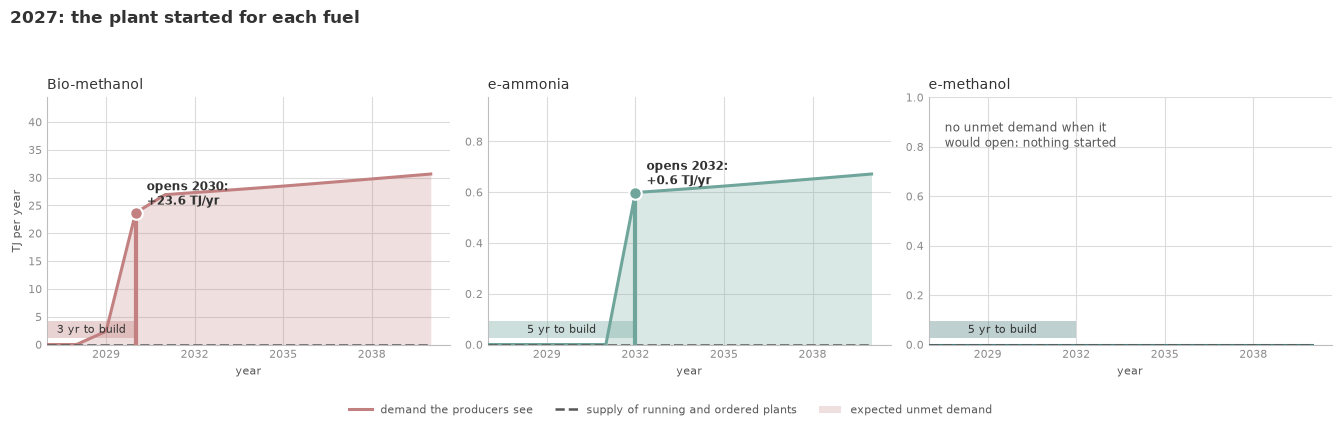

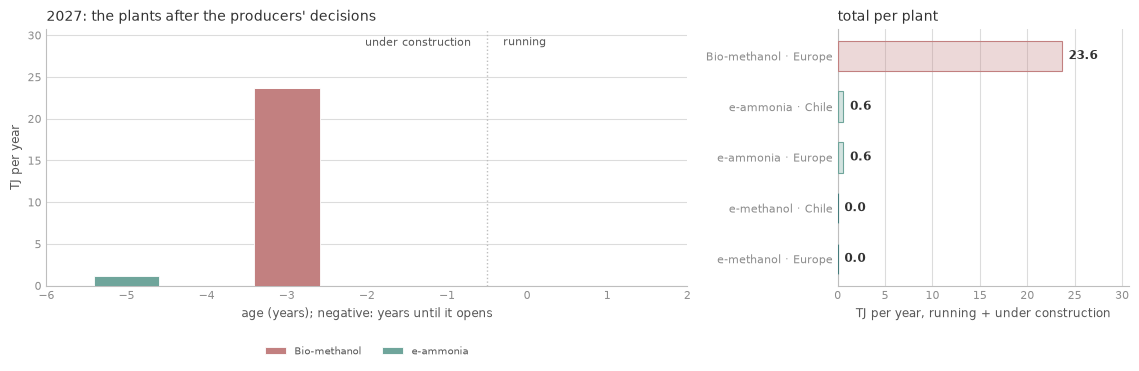

No producer came near its build limit, so the shares of Choose decided nothing:
  producer_efuel         0.0003 of   8.31 plants  ( 0.00% of the limit)
  producer_biofuel       0.0024 of   8.31 plants  ( 0.03% of the limit)


In [31]:
# @title Stage 3 figures: decide, which plants and how many
fig, axes = plt.subplots(1, len(PRODUCED), figsize=(13.5, 4.2))
fig.suptitle(f"{FOCUS_YEARS[0]}: the plant started for each fuel", fontsize=12, color=INK,
             x=0.01, ha="left", fontweight="bold")
handles, labels_ = draw_supply_demand(STEP_EARLY, np.atleast_1d(axes))
fig.legend(handles, labels_, fontsize=8, frameon=False, labelcolor=SUBINK, ncol=3,
           loc="lower center")
fig.tight_layout(rect=(0, 0.07, 1, 0.93))
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9), gridspec_kw={"width_ratios": [2.2, 1]})
draw_plants(STEP_EARLY, axes)
fig.tight_layout()
plt.show()

by_owner = {}
for _plant, _d in snap["producer"].items():
    by_owner.setdefault(_d["producer"], []).append(_plant)
print("No producer came near its build limit, so the shares of Choose decided nothing:")
for _owner, _members in by_owner.items():
    _cap = snap["producer"][_members[0]]["max_development"]
    _used = sum(snap["producer"][p]["plants_justified"] for p in _members)
    print(f"  {_owner:20} {_used:8.4f} of {_cap:6.2f} plants  "
          f"({_used / _cap * 100:5.2f}% of the limit)")

##### 3. Commit

At the end of their decision step, the producers publish their supply outlook. It tells the fleet operators what fuel they can buy this year and what they can expect in the years ahead.
Two points in it matter:

- **The plants they expect to add later**: the outlook also counts plants not ordered
  yet. It assumes each producer will build every year as many plants as its build
  limit and feedstock allow, whether or not the fuel is needed. So the fleet operators
  expect more alternative fuel in the future than the producers are building today.
- **The fuel price at the ports**: the average cost of producing and delivering the fuel, weighted by each plant's output, with no margin.

##### Not shown in this example

The producers' step has a few more settings that this deck leaves at their
defaults, so they change nothing here:

- When several producers make the same fuel, they fill its expected unmet demand in
  proportion to how much of that fuel each can add this year, given its build limit
  and the feedstock it has left. For example, a producer that could add three times
  as much as another takes three quarters of it. Here each fuel has a single producer.
- `MinimumOfftakeDuration` sizes a plant on the smallest expected unmet demand over several years
  instead of its opening year alone (one year by default).
- `MaximumRampUp` limits how fast a producer can raise its build rate from one year
  to the next (no limit by default).
- When the build limit binds and a plant reaches its cap, its unused share goes to
  the producer's other plants.
- `set_export_distribution` sets how a producer's output is split between the ports
  (evenly by default), and the delivered cost that compares its plants is averaged
  with the same weights.

#### Stage 4 — Fleet commit: final bunkering algorithm

This step runs the "real" bunkering algorithm for this year: the same solve as in Stage 1, but on the fleet as Stage 2 left it (new ships, speeds and technologies) and on the fuel the producers actually supply this year.

The result can differ slightly from the Stage 1 belief, since the fleet and the fuel supply have changed since. But this is what the ships actually burn and pay this year. The figures below show the bill and the fuel of one ship of each configuration, whether the fuel the plants made was burned, and what the transport cost is. When checking the results, remember that ordering a dual-fuel ship and burning its fuel are two different decisions: in 2027 every ship including the dual fuel vessels, still burns oil or LNG.

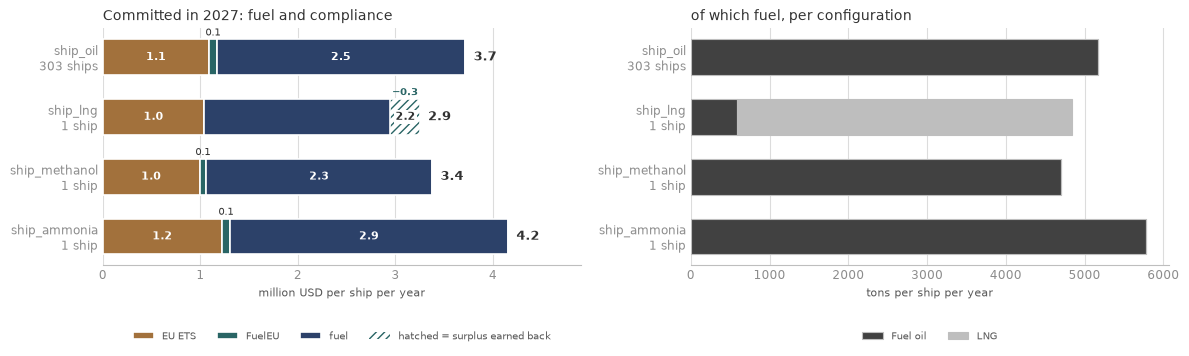

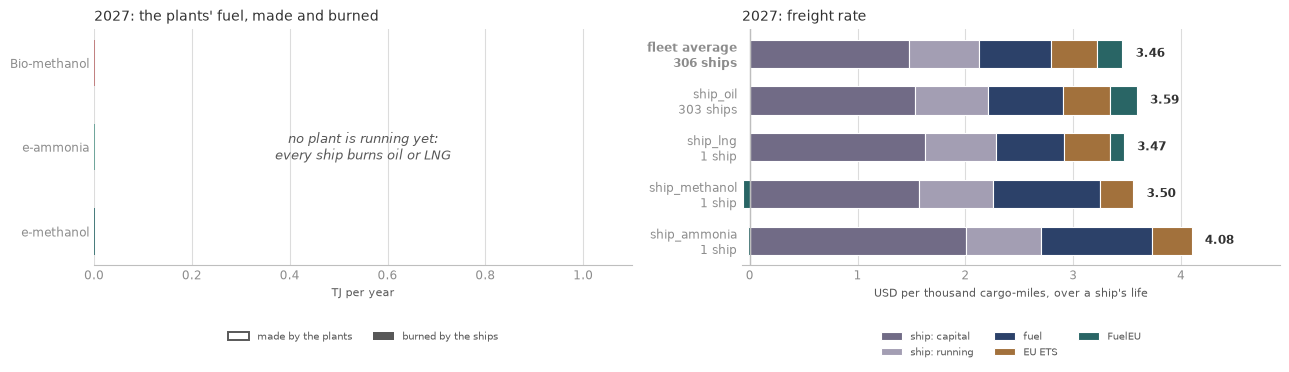

In [32]:
# @title Stage 4 figures: what the year committed
from matplotlib.colors import to_rgba

from navigate.illustrations.plots._labels import FUEL_ORDER


def tons_limit(*steps):
    """One x limit for the fuel panels, so the years can be compared by eye."""
    return 1.05 * max(
        sum(t for (v, _p, _f), t in snaps[step]["bunkered"].items() if v == name)
        for step in steps
        for name in CONFIGS)


def ship_label(name, step):
    """A configuration's name, with how many ships of it sail this year."""
    ships = at(copper_trade.profile.get_existing_vessels, step)
    count = sum(ships.values()) if name == "fleet average" else ships.get(name, 0.)
    return f"{name}\n{count:,.0f} ship{'' if round(count) == 1 else 's'}"


# The year as it was actually committed. This comes from the profile, which keeps
# the spend per fuel and the remedial units per regulation - so it can split
# compliance by scheme and show the surplus a compliant ship earns back.
def plot_committed_bill(step, axes=None, scale_over=None, legend=True):
    """This year's realised bill: fuel and compliance, and the fuel behind it."""

    def series(getter):
        return float(np.nan_to_num(np.asarray(getter(), dtype=float))[step])

    REG_LABEL = {"eu_ets": "EU ETS", "fuel_eu": "FuelEU"}

    # bunker.X is per vessel and the fleet multiplier is applied separately, so every
    # figure below is one ship of that configuration, not the sub-fleet.
    rows = {}
    for name in CONFIGS:
        profile = base.nodes.vessels[name].profile
        spend = sum(series(lambda f=fuel: profile.get_fuel_expenses(f))
                    for fuel in base.nodes.fuels) / 1e6
        # get_remedial_expenses() is a SINGLE accumulator that every regulation adds
        # into, so it cannot be read as one scheme's bill. The remedial units ARE
        # kept per regulation, and units x the believed unit cost splits it exactly.
        part = {}
        for reg_name, regulation in base.nodes.regulations.items():
            units = series(lambda r=reg_name: profile.get_remedial_units(r))
            part[REG_LABEL.get(reg_name, reg_name)] = (
                units * regulation.expectation.get_remedial_cost(step) / 1e6)
        # pooling sits with the scheme that offers it
        part["FuelEU"] = (part.get("FuelEU", 0.)
                          + series(profile.get_flexibility_expenses) / 1e6)
        # and a ship that beats the limit is PAID. Leaving this out is what made a
        # compliant hull look as though it had overspent against its own forecast.
        rows[name] = {"fuel": spend, **part,
                      "credit": series(profile.get_surplus_revenue) / 1e6}
        # the bar needs the parts, but the parts must still add up to the whole
        assert abs(sum(part.values())
                   - (series(profile.get_remedial_expenses)
                      + series(profile.get_flexibility_expenses)) / 1e6) < 1e-6

    own_figure = axes is None
    if own_figure:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.0))
    axA, axB = axes
    y = range(len(CONFIGS))

    # Read the way the TTW/WTW figure reads. The surplus is a credit: drawn white
    # and hatched in the colour of the scheme that pays it (FuelEU), eating back
    # into the bar, so what stays solid is what the ship pays. Fuel goes last, so
    # the credit only ever eats into that one slice, as the WTT credit eats into
    # TTW there. label_bill() prints the numbers so that each row adds up.
    credit = np.array([rows[n]["credit"] for n in CONFIGS])

    left = np.zeros(len(CONFIGS))
    slices = []
    for part_name in ("EU ETS", "FuelEU", "fuel"):
        values = np.array([rows[n][part_name] for n in CONFIGS])
        axA.barh(list(y), values, left=left, height=.6, color=cost_colour(part_name),
                 label=part_name, zorder=3, edgecolor="white", linewidth=1.2)
        slices.append((values, left.copy()))
        left += values
    axA.barh(list(y), -credit, left=left, height=.6, facecolor="white",
             hatch="////", edgecolor=cost_colour("FuelEU"), linewidth=0, zorder=4,
             label="hatched = surplus earned back")
    axA.barh(list(y), -credit, left=left, height=.6, facecolor="none",
             edgecolor="white", linewidth=1.2, zorder=4)
    label_bill(axA, slices, credit, digits=1)
    axA.set_title(f"Committed in {YEARS[step]}: fuel and compliance",
                  fontsize=10, color=INK, loc="left")
    axA.set_xlim(0, left.max() * 1.18)
    axA.set_xlabel("million USD per ship per year", fontsize=8, color=SUBINK)
    axA.legend(fontsize=7.5, frameon=False, labelcolor=SUBINK, ncol=4,
               loc="upper center", bbox_to_anchor=(0.5, -0.24))

    # in tons, on one scale for every year in scale_over
    mix = snaps[step]["bunkered"]
    fuels_used = [f for f in FUEL_ORDER if any(k[2] == f for k in mix)]
    left = np.zeros(len(CONFIGS))
    for fuel_name in fuels_used:
        values = np.array([sum(v for (n2, _p, f), v in mix.items()
                               if n2 == name and f == fuel_name) for name in CONFIGS])
        axB.barh(list(y), values, left=left, height=.6, color=fuel_colour(fuel_name),
                 label=fuel_label(fuel_name), zorder=3, edgecolor=AXIS, linewidth=0.8)
        left += values
    axB.set_title("of which fuel, per configuration", fontsize=10, color=INK, loc="left")
    axB.set_xlim(0, tons_limit(*(scale_over or (step,))))
    axB.set_xlabel("tons per ship per year", fontsize=8, color=SUBINK)
    # one legend serves every year in scale_over, so it names every fuel they used
    shown = [f for f in FUEL_ORDER
             if any(k[2] == f for s in (scale_over or (step,))
                    for k in snaps[s]["bunkered"])]
    axB.legend(handles=[Patch(facecolor=fuel_colour(f), edgecolor=AXIS, linewidth=0.8,
                              label=fuel_label(f)) for f in shown],
               fontsize=7.5, frameon=False, labelcolor=SUBINK, ncol=len(shown),
               loc="upper center", bbox_to_anchor=(0.5, -0.24))

    for ax in (axA, axB):
        ax.set_yticks(list(y), [ship_label(n, step) for n in CONFIGS])
        ax.invert_yaxis()
        ax.grid(axis="x", color=GRID, lw=0.8)
        ax.set_axisbelow(True)
        ax.tick_params(colors=TICK, labelsize=8.5, length=0)
        for side in ("top", "right", "left"):
            ax.spines[side].set_visible(False)
        ax.spines["bottom"].set_color(AXIS)
    if not legend:            # one legend is enough when the years are stacked
        for ax in (axA, axB):
            if ax.get_legend() is not None:
                ax.get_legend().remove()
    if own_figure:
        fig.tight_layout(rect=(0, 0.04, 1, 1))
        plt.show()


def fuel_use(step):
    """TJ of each produced fuel made by the plants, and burned by the ships."""
    rows = {}
    for fuel in PRODUCED:
        made = sum(float(np.nan_to_num(np.asarray(
            p.profile.get_production_energy(fuel), dtype=float))[step])
            for p in base.nodes.producers.values() if p.can_produce(fuel)) / 1e3
        burned = float(np.nan_to_num(np.asarray(
            copper_trade.profile.get_consumed_energy(fuel), dtype=float))[step]) / 1e3
        rows[fuel] = (made, burned)
    return rows


def draw_fuel_use(step, axU, scale_over=None, legend=True):
    """Whether the fuel the plants made this year was burned."""
    steps = tuple(scale_over) if scale_over else (step,)

    # ---- the plants' fuel: made, and burned ---------------------------------
    # made is the outline, burned the solid bar inside it, so what is left
    # hollow is fuel made but not burned
    use = fuel_use(step)
    y = range(len(PRODUCED))
    for i, fuel in enumerate(PRODUCED):
        made, burned = use[fuel]
        axU.barh(i, made, height=.55, facecolor="none", edgecolor=fuel_colour(fuel),
                 linewidth=1.4, zorder=4)
        axU.barh(i, burned, height=.55, color=fuel_colour(fuel), zorder=3)
    reach = max(max(m, b) for s in steps for m, b in fuel_use(s).values())
    if max(max(m, b) for m, b in use.values()) <= 0:
        axU.annotate("no plant is running yet:\nevery ship burns oil or LNG",
                     (0.5, 0.5), xycoords="axes fraction", ha="center", va="center",
                     fontsize=9, color=SUBINK, style="italic")
    axU.set_yticks(list(y), [fuel_label(f) for f in PRODUCED])
    axU.invert_yaxis()
    axU.set_xlim(0, (reach or 1.) * 1.1)
    axU.set_xlabel("TJ per year", fontsize=8, color=SUBINK)
    axU.set_title(f"{YEARS[step]}: the plants' fuel, made and burned", fontsize=10, color=INK, loc="left")
    if legend:
        axU.legend(handles=[Patch(facecolor="none", edgecolor=SUBINK, linewidth=1.4,
                                  label="made by the plants"),
                            Patch(facecolor=SUBINK, label="burned by the ships")],
                   fontsize=7.5, frameon=False, labelcolor=SUBINK, ncol=2,
                   loc="upper center", bbox_to_anchor=(0.5, -0.24))

    axU.grid(axis="x", color=GRID, lw=0.8)
    axU.set_axisbelow(True)
    axU.tick_params(colors=TICK, labelsize=8.5, length=0)
    for side in ("top", "right", "left"):
        axU.spines[side].set_visible(False)
    axU.spines["bottom"].set_color(AXIS)


from navigate.investment.metric import calculate_net_present_value
from _style import swatch
from navigate.investment.post_process import _operating_flows

FREIGHT_PARTS = ["ship: capital", "ship: running", "fuel", "EU ETS", "FuelEU"]
FREIGHT_COLOUR = {"ship: capital": swatch("purple", 7), "ship: running": swatch("purple", 4),
                  "fuel": cost_colour("fuel"), "EU ETS": cost_colour("EU ETS"),
                  "FuelEU": cost_colour("FuelEU")}


def freight_parts(step):
    """The freight rate of each configuration, and of the fleet, split into its parts.

    Navigate's freight rate is not one year's bill: it is the cost of a ship from
    this year to the end of its life, discounted, over the cargo-miles it carries
    (navigate/investment/post_process.py). This rebuilds it the same way, part by
    part, in USD per thousand cargo-miles, and checks the parts add up.
    """
    timeline = base.get_timeline()
    unit_cost = {r: np.array([reg.expectation.get_remedial_cost(i) for i in range(timeline.size)])
                 for r, reg in base.nodes.regulations.items()}
    rows, fleet, fleet_cargo = {}, dict.fromkeys(FREIGHT_PARTS, 0.), 0.
    for name in CONFIGS:
        vessel = base.nodes.vessels[name]
        prof = vessel.profile
        ships = copper_trade.profile.get_existing_vessels(name, step)
        if ships <= 0 or not prof.cost_is_calculated(step):
            continue
        rate = vessel.cost_of_capital.get(timeline[step])
        year_flow, overlap = _operating_flows(step, prof.get_lead_time(step),
                                              prof.get_lifetime(step), timeline)

        def npv(series):
            return calculate_net_present_value(
                np.interp(year_flow, timeline, series) * overlap, rate)

        ets = np.nan_to_num(np.asarray(prof.get_remedial_units("eu_ets"), dtype=float)) \
            * unit_cost["eu_ets"]
        capital = vessel.expectation.get_capex_npv(step)
        part = {"ship: capital": capital,
                "ship: running": vessel.expectation.get_asset_charter_npv(step) - capital,
                "fuel": npv(prof.get_total_fuel_expenses())
                        + npv(prof.get_total_levy_expenses()),
                "EU ETS": npv(ets),
                "FuelEU": npv(prof.get_regulation_expenses()) - npv(ets)}
        cargo = npv(prof.get_cargo_miles())
        rows[name] = {k: 1e3 * v / cargo for k, v in part.items()}
        # the fleet rate weighs each ship by its numbers, as Navigate does
        age = calculate_net_present_value(overlap, rate)
        for k, v in part.items():
            fleet[k] += ships * v / age
        fleet_cargo += ships * prof.get_cargo_miles(step)
    fleet = {k: 1e3 * v / fleet_cargo for k, v in fleet.items()}
    model = 1e3 * total_at(copper_trade.profile.get_instantaneous_freight_rate, step)
    assert abs(sum(fleet.values()) - model) < 1e-6 * max(model, 1.), (sum(fleet.values()), model)
    return {"fleet average": fleet, **rows}


def draw_freight_breakdown(step, ax, scale_over=None, legend=True):
    """What moving cargo costs over a ship's life, and what that cost is made of."""
    steps = tuple(scale_over) if scale_over else (step,)
    rows = freight_parts(step)
    names = list(rows)
    y = range(len(names))
    pos, neg = np.zeros(len(names)), np.zeros(len(names))
    for part in FREIGHT_PARTS:
        values = np.array([rows[n][part] for n in names])
        start = np.where(values >= 0, pos, neg)
        ax.barh(list(y), values, left=start, height=.6, color=FREIGHT_COLOUR[part],
                edgecolor="white", linewidth=.8, zorder=3, label=part)
        pos += np.where(values >= 0, values, 0.)
        neg += np.where(values < 0, values, 0.)
    reach = max(sum(max(v, 0.) for v in r.values()) for s in steps
                for r in freight_parts(s).values())
    for i, n in enumerate(names):
        ax.annotate(f"{sum(rows[n].values()):.2f}", (pos[i] + reach * .03, i), va="center",
                    fontsize=8.5, color=INK, fontweight="bold")
    ax.axvline(0, color=AXIS, lw=1, zorder=4)
    ax.set_yticks(list(y), [ship_label(n, step) for n in names])
    ax.get_yticklabels()[0].set_fontweight("bold")
    ax.invert_yaxis()
    ax.set_xlim(min(0., neg.min() * 1.2), reach * 1.2)
    ax.set_xlabel("USD per thousand cargo-miles, over a ship's life", fontsize=8,
                  color=SUBINK)
    ax.set_title(f"{YEARS[step]}: freight rate", fontsize=10,
                 color=INK, loc="left")
    if legend:
        ax.legend(fontsize=7.5, frameon=False, labelcolor=SUBINK, ncol=3,
                  loc="upper center", bbox_to_anchor=(0.5, -0.24))
    ax.grid(axis="x", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TICK, labelsize=8.5, length=0)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)


plot_committed_bill(STEP_EARLY)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
draw_fuel_use(STEP_EARLY, axes[0])
draw_freight_breakdown(STEP_EARLY, axes[1])
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()


After the year is completed, every belief is overwritten by
next year's look-ahead.

---

### Thirteen years on: the same step in 2040

Tadaaa, we are now 13 years later (we repeated the 2027 step multiple times and we are now checking what happens at the year 2040). The logic is the same as before but the conditions have changed.


In [33]:
# @title What changed between 2027 and 2040
# What CHANGED between the two steps. The levers themselves are drawn further
# down, one stage at a time; these are the conditions the stages answered to.
late = snaps[STEP_LATE]


def compare(label, early, late_value, fmt="{:>12,.2f}"):
    print(f"  {label:34}{fmt.format(early):>14}{fmt.format(late_value):>14}")


print(f"{'':36}{FOCUS_YEARS[0]:>14}{FOCUS_YEARS[1]:>14}")
print("  " + "-" * 60)
for name in snap["regulation"]:
    compare(f"{name}: unit cost, USD/ton",
            snap["regulation"][name]["unit_cost"], late["regulation"][name]["unit_cost"])
compare("fuel_eu limit, gCO2eq/MJ",
        snap["regulation"]["fuel_eu"]["limit"], late["regulation"]["fuel_eu"]["limit"])

print()
for step, year in ((STEP_EARLY, FOCUS_YEARS[0]), (STEP_LATE, FOCUS_YEARS[1])):
    converted = at(copper_trade.profile.get_fuel_conversions, step)
    live = {k: v for k, v in converted.items() if v > 1e-9}
    print(f"  conversions in {year}: {live if live else 'none - no cohort was both in a '
          'retrofit cycle and worth converting'}")

                                              2027          2040
  ------------------------------------------------------------
  eu_ets: unit cost, USD/ton                133.39        252.00
  fuel_eu: unit cost, USD/ton               760.00        760.00
  fuel_eu limit, gCO2eq/MJ                   89.34         62.90

  conversions in 2027: none - no cohort was both in a retrofit cycle and worth converting
  conversions in 2040: none - no cohort was both in a retrofit cycle and worth converting


#### Stage 0 — Initialization (2027 vs 2040)

Each year starts from what it inherits: the fleet with its age structure, the plants already sanctioned, and this year's terms of the two regulations. By 2040 the fleet is no longer all oil, and some plants are running.

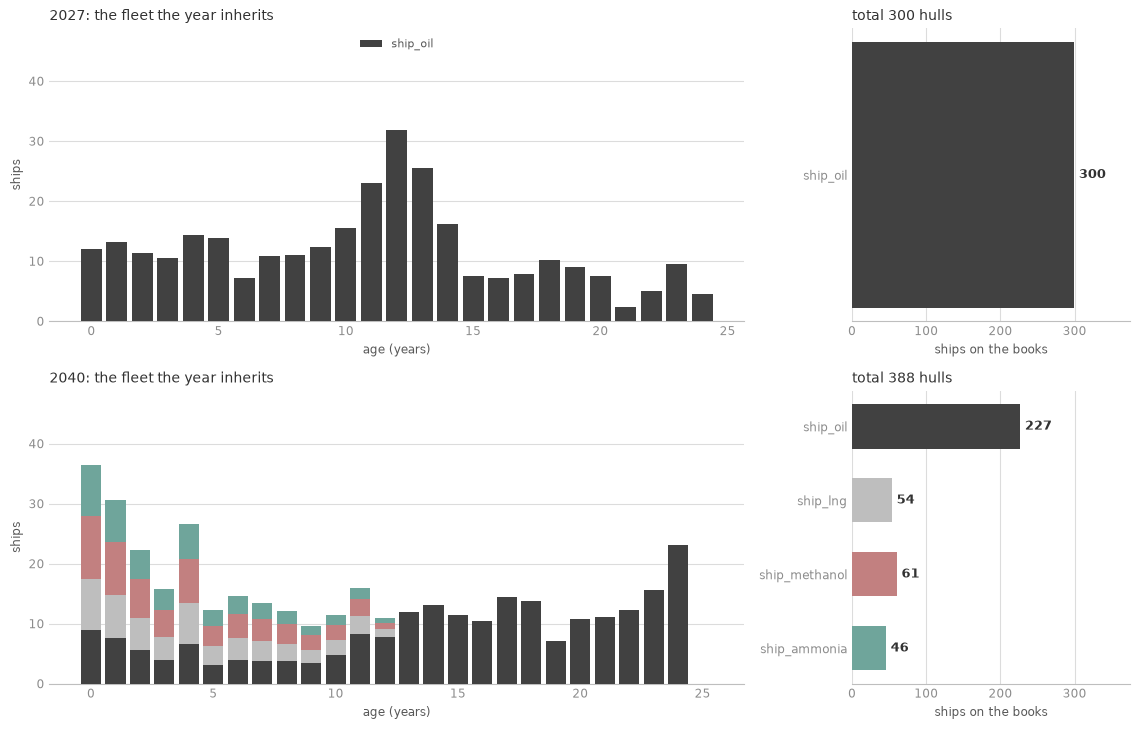

In [34]:
# @title Stage 0 figure, 2027 vs 2040
# Stage 0, both years. Same function, same scale: what the year inherits.
fig, axes = plt.subplots(2, 2, figsize=(11.5, 7.4),
                         gridspec_kw={"width_ratios": [2.5, 1]})
for row, step in enumerate((STEP_EARLY, STEP_LATE)):
    draw_inherited(step, axes[row], scale_over=(STEP_EARLY, STEP_LATE), legend=row == 0)
fig.tight_layout()
plt.show()

#### Stage 1 — Look ahead (2027 vs 2040)

The operators again calculate the cheapest bunkering strategy for every year ahead, given the expected fuel and compliance costs and the fuel the ports can supply. The figures compare what they expect to buy, and what they expect it to cost.

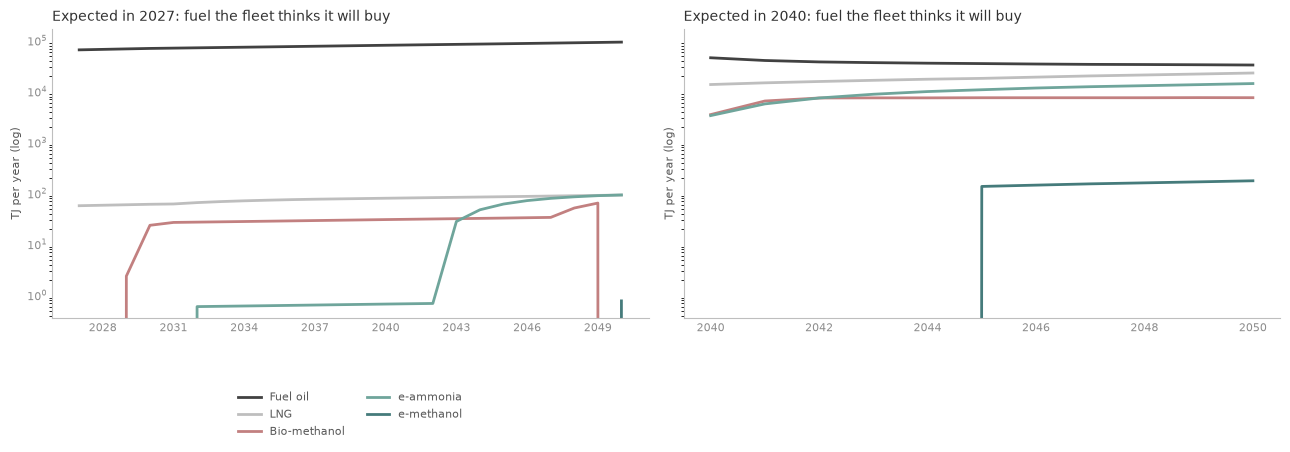

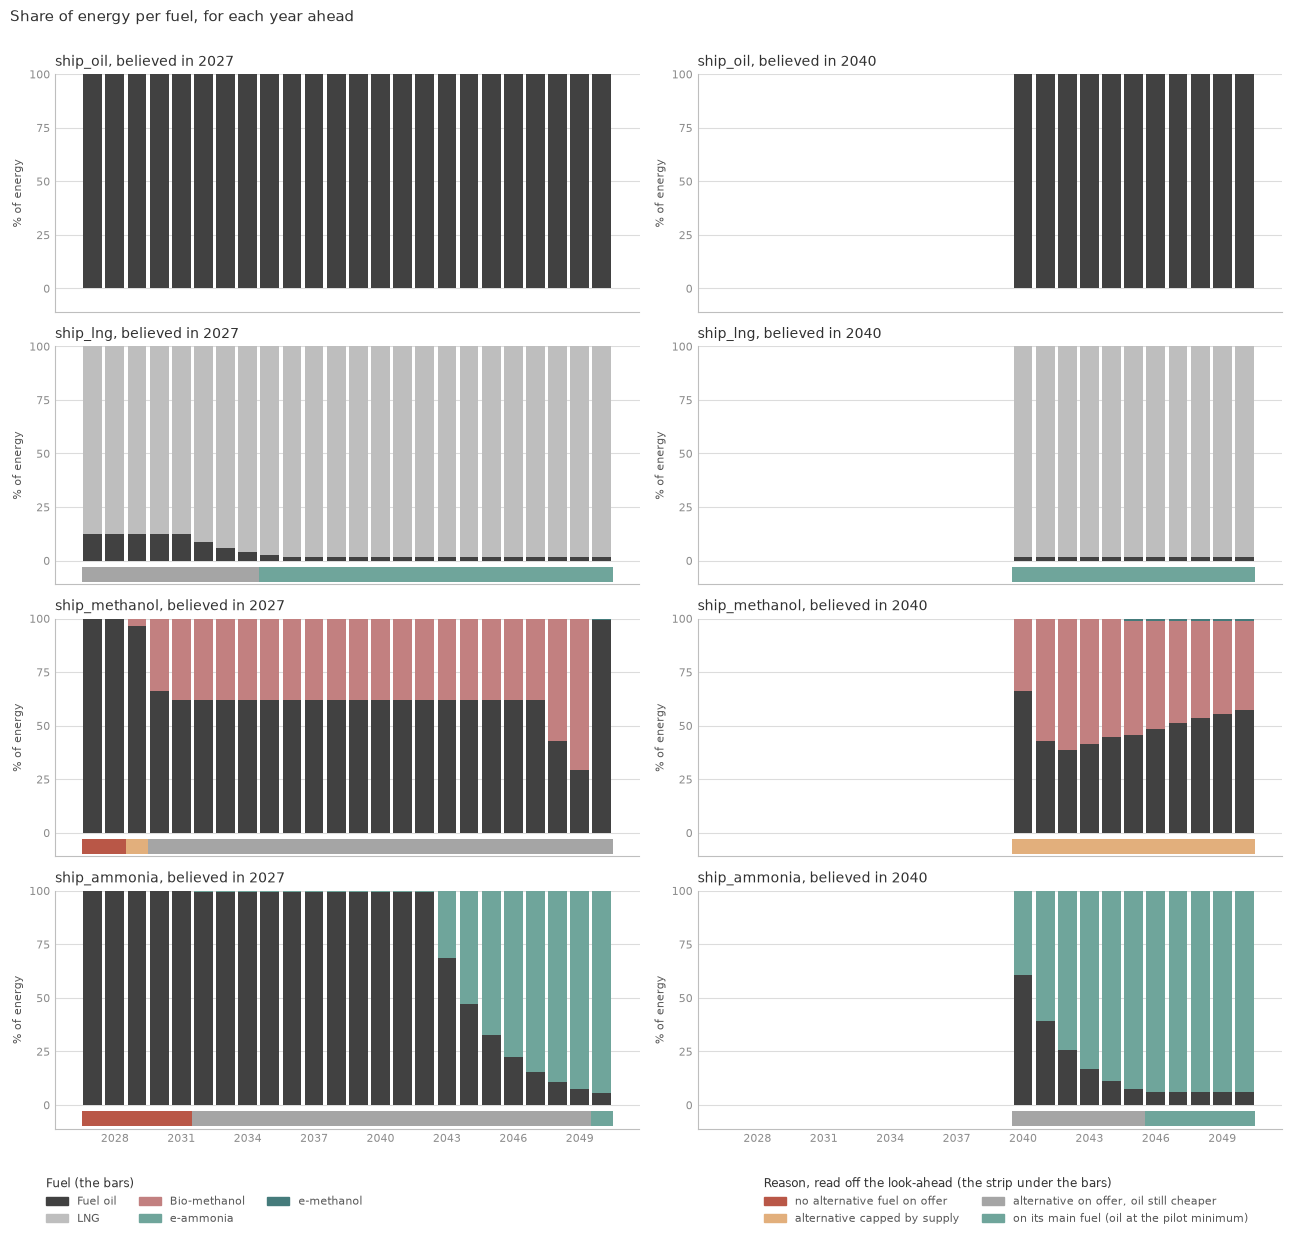

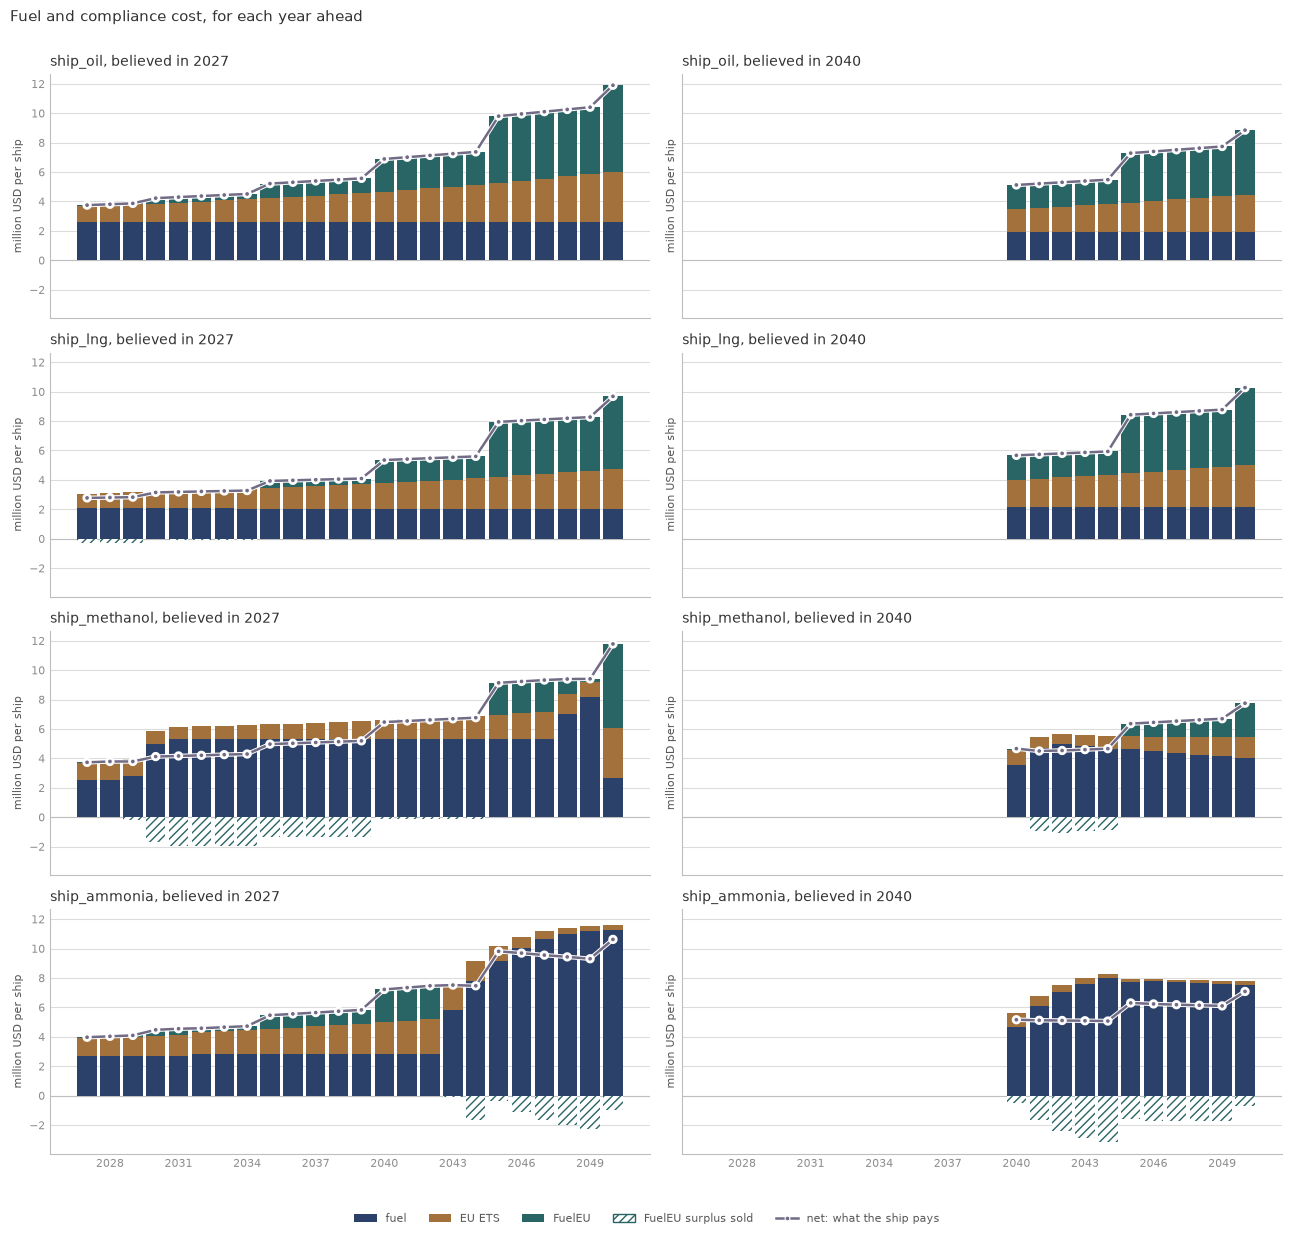

In [35]:
# @title Stage 1 figures, 2027 vs 2040
# Stage 1, both years. The look-ahead's two outputs - what it expects to buy,
# and what it expects that to cost.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for col, step in enumerate((STEP_EARLY, STEP_LATE)):
    draw_expected_demand(step, axes[col], scale_over=(STEP_EARLY, STEP_LATE),
                         legend=col == 0)
fig.tight_layout()
plt.show()


def side_by_side(draw, title, **share):
    """One column per focus year, one row per configuration, on one time axis.

    2040 only looks as far as 2027 did minus thirteen years, so its column starts
    later; the shared axis is what keeps that from reading as a change of mind.
    """
    fig, axes = plt.subplots(len(CONFIGS), 2, figsize=(13, 12.5), sharex=True, **share)
    for col, step in enumerate((STEP_EARLY, STEP_LATE)):
        drawn = draw(step, axes[:, col])
        for ax, name in zip(axes[:, col], CONFIGS):
            ax.set_title(f"{name}, believed in {YEARS[step]}", fontsize=10, color=INK,
                         loc="left")
    fig.suptitle(title, fontsize=11, color=INK, x=0.01, ha="left")
    return fig, drawn


fig, fuels_drawn = side_by_side(draw_mix_by_year,
                                "Share of energy per fuel, for each year ahead")
mix_legend(fig, fuels_drawn)
fig.tight_layout(rect=(0, 0.06, 1, 0.98))
plt.show()

fig, _ = side_by_side(draw_bill_by_year, "Fuel and compliance cost, for each year ahead",
                      sharey=True)
bill_legend(fig)
fig.tight_layout(rect=(0, 0.04, 1, 0.98))
plt.show()

#### Stage 2 — Decide (2027 vs 2040)

The owners and operators take the same four decisions, in the same order: technology, speed, the scorecard and the fleet. Each column shows one year.

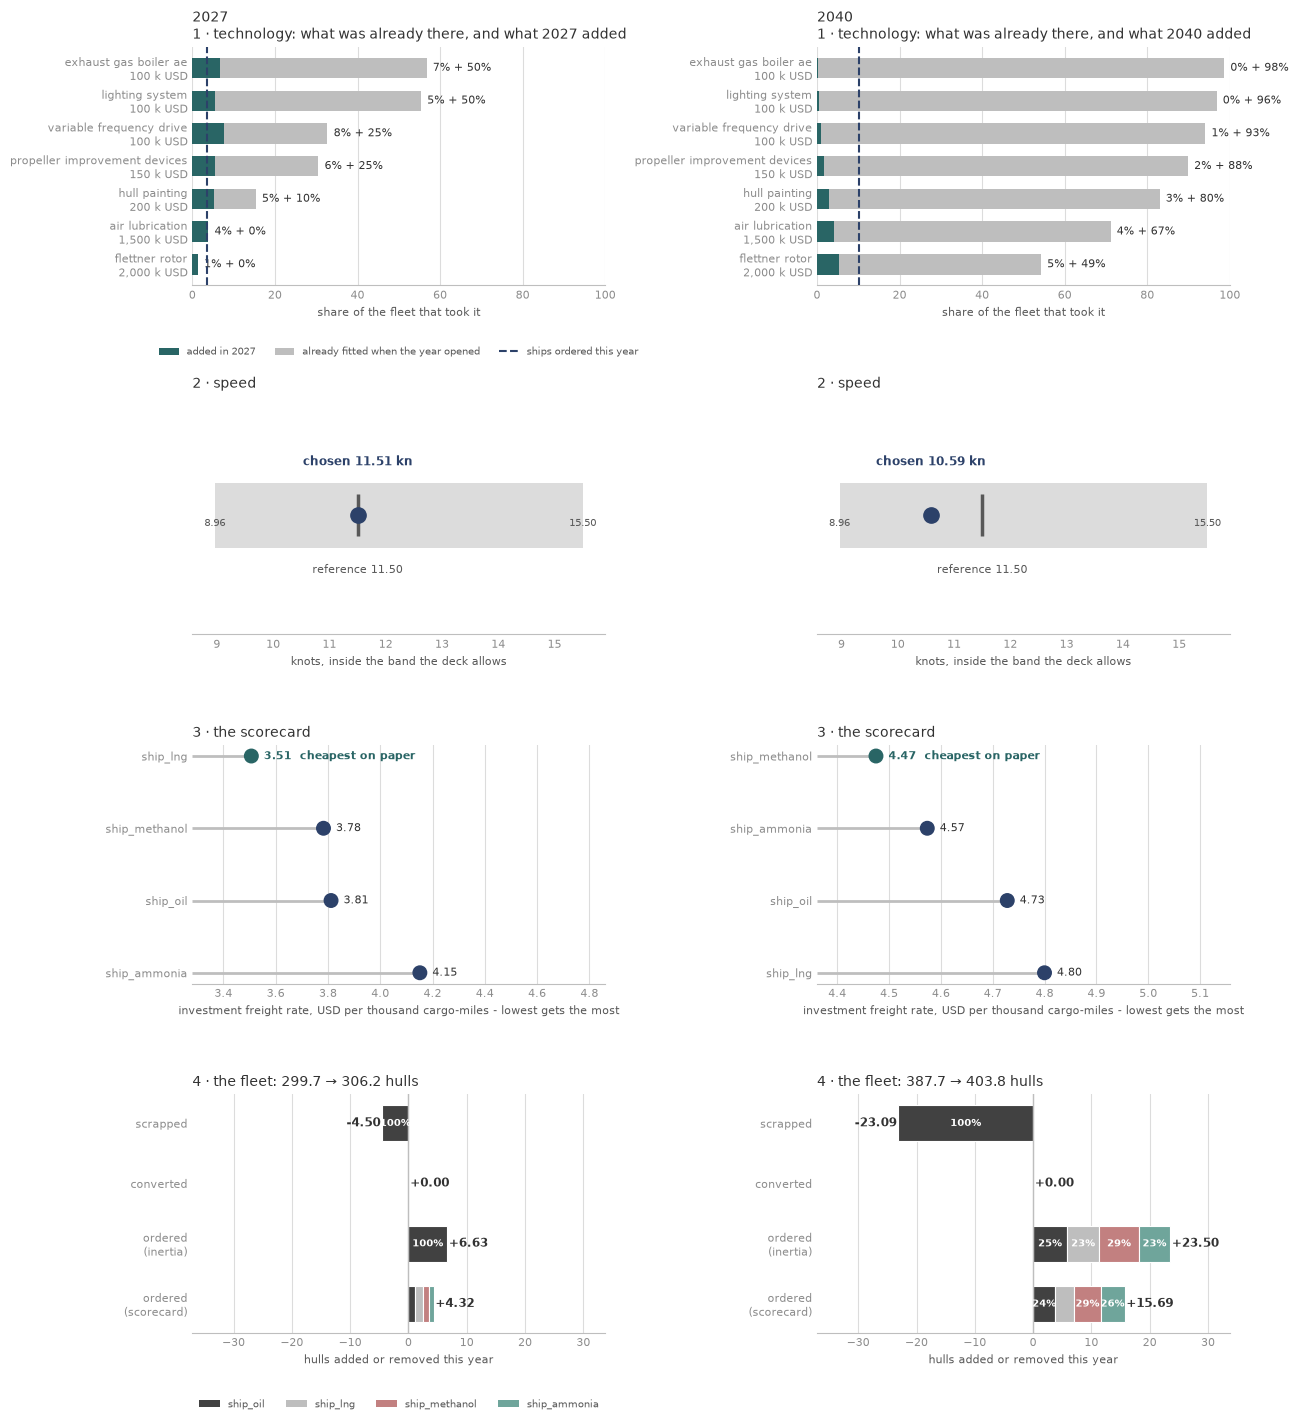

In [36]:
# @title Stage 2 figures, 2027 vs 2040
# Stage 2, both years. Four panels per year will not fit across one row, so here
# the YEAR IS THE COLUMN: 2027 on the left, 2040 on the right, each column in the
# same order as the 2×2 above - technology, speed, scorecard, fleet.
fig, axes = plt.subplots(4, 2, figsize=(13, 14.5))
for col, step in enumerate((STEP_EARLY, STEP_LATE)):
    draw_four_decisions(step, axes[:, col], scale_over=(STEP_EARLY, STEP_LATE),
                        legend=col == 0)
    # get_title() returns the CENTRE title, which is empty here - every title in
    # this notebook is set loc="left" - so ask for the one that exists.
    axes[0][col].set_title(f"{YEARS[step]}\n" + axes[0][col].get_title(loc="left"),
                           fontsize=10, color=INK, loc="left")
fig.tight_layout(rect=(0, 0.01, 1, 1))
plt.show()

#### Stage 3 — The producers decide too (2027 vs 2040)

The producers again build towards the expected unmet demand, as far as their build limit and feedstock allow. Each row shows one year.

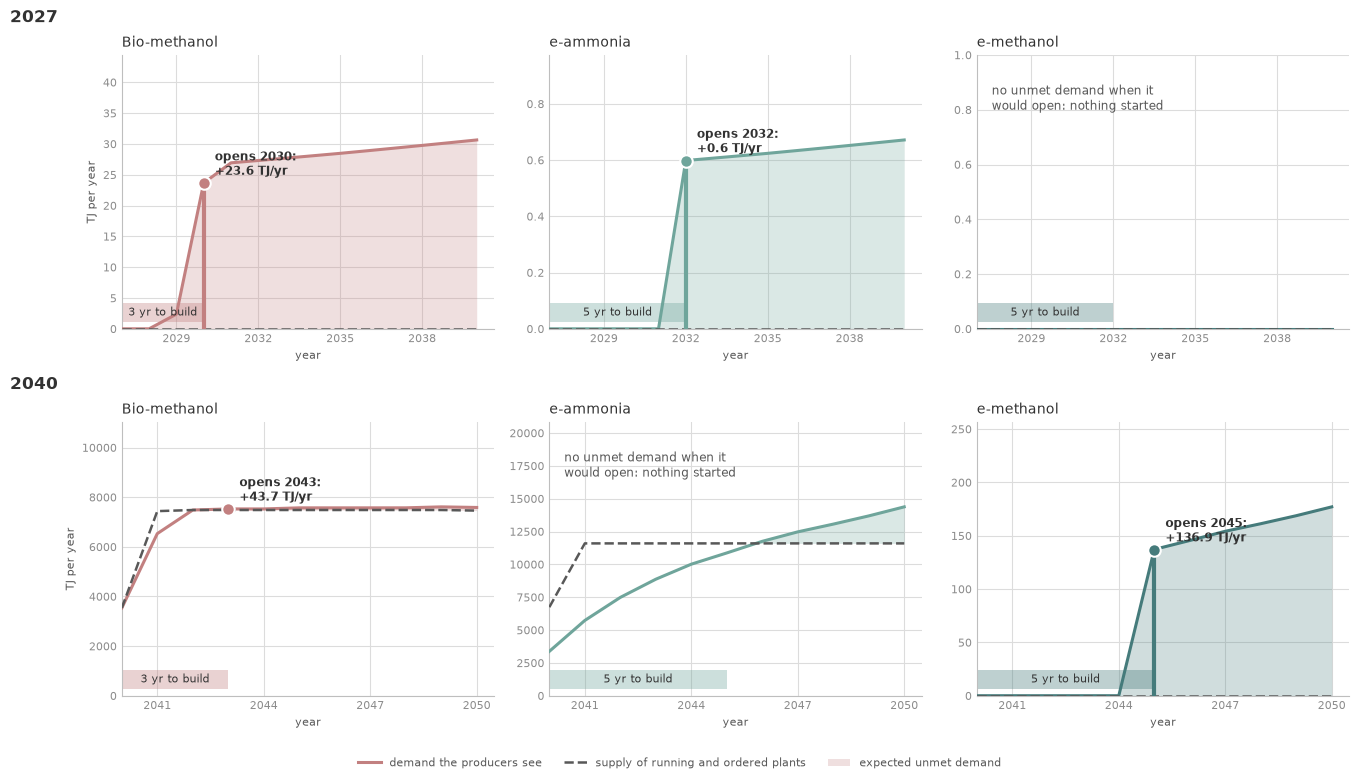

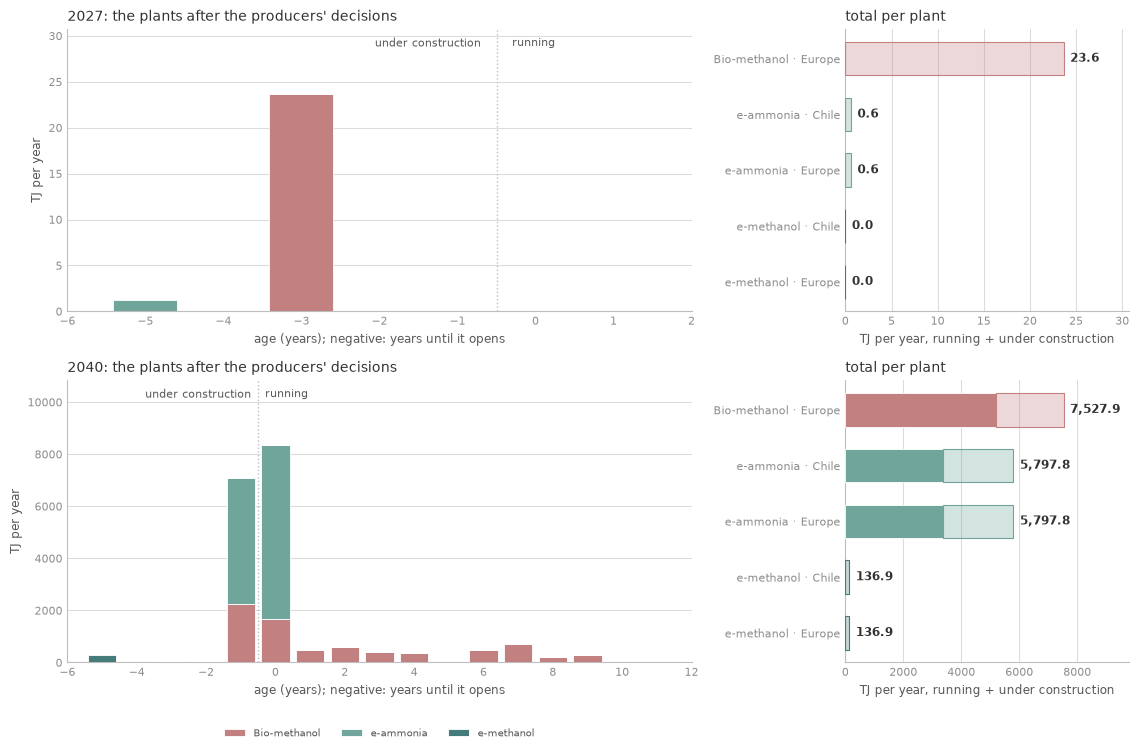

In [37]:
# @title Stage 3 figures, 2027 vs 2040
# Stage 3, both years, one row each. Every panel keeps its own scale: the 2040
# gaps and plants are many times the 2027 ones.
fig, axes = plt.subplots(2, len(PRODUCED), figsize=(13.5, 7.8))
for row, step in enumerate((STEP_EARLY, STEP_LATE)):
    handles, labels_ = draw_supply_demand(step, axes[row])
    axes[row][0].annotate(str(YEARS[step]), (-0.3, 1.12), xycoords="axes fraction",
                          fontsize=12, color=INK, fontweight="bold")
fig.legend(handles, labels_, fontsize=8, frameon=False, labelcolor=SUBINK, ncol=3,
           loc="lower center")
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(11.5, 7.6), gridspec_kw={"width_ratios": [2.2, 1]})
for row, step in enumerate((STEP_EARLY, STEP_LATE)):
    draw_plants(step, axes[row], legend=row == 1)
fig.tight_layout()
plt.show()

#### Stage 4 — Commit: the bunkering algorithm that binds (2027 vs 2040)

The year is committed with the real bunkering algorithm, on the fleet and the fuel supply of that year. By 2040 the dual-fuel ships burn mostly their own fuel, and part of the e-ammonia made is not burned.

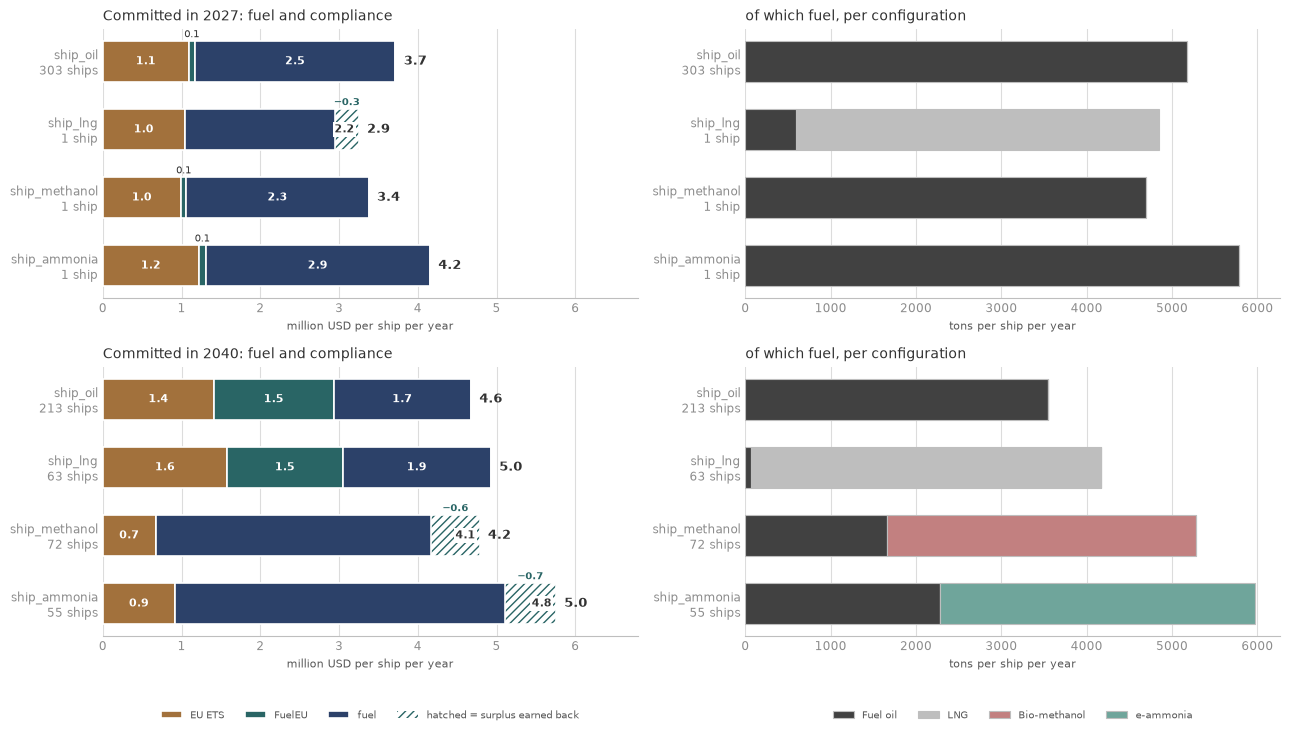

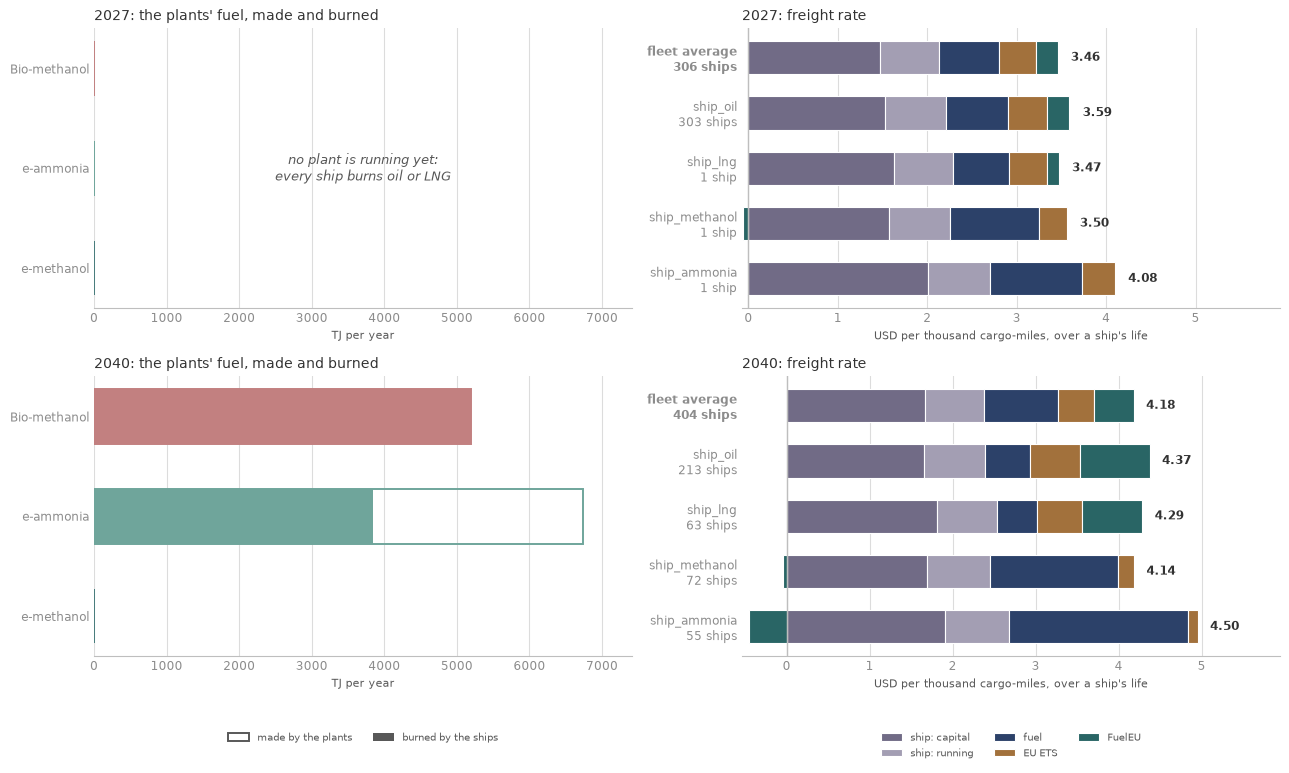

In [38]:
# @title Stage 4 figures, 2027 vs 2040
# Stage 4, both years, laid out as the 2027 figures above, one row per year. All
# the tons panels share one scale (scale_over) and both bill panels another.
fig, axes = plt.subplots(2, 2, figsize=(13, 7.6))
for row, step in enumerate((STEP_EARLY, STEP_LATE)):
    plot_committed_bill(step, axes=axes[row], scale_over=(STEP_EARLY, STEP_LATE),
                        legend=row == 1)
_wide = max(ax.get_xlim()[1] for ax in axes[:, 0])
for ax in axes[:, 0]:
    ax.set_xlim(0, _wide)
fig.tight_layout(rect=(0, 0.02, 1, 1))
plt.show()

# the plants' fuel and the freight rate, both years on one scale per panel
fig, axes = plt.subplots(2, 2, figsize=(13, 8.0))
for row, step in enumerate((STEP_EARLY, STEP_LATE)):
    draw_fuel_use(step, axes[row, 0], scale_over=(STEP_EARLY, STEP_LATE),
                  legend=row == 1)
    draw_freight_breakdown(step, axes[row, 1], scale_over=(STEP_EARLY, STEP_LATE),
                           legend=row == 1)
fig.tight_layout(rect=(0, 0.02, 1, 1))
plt.show()


---

### Results for a full simulation

In this section, we analyze the results of the full simulation instead of looking at specific years in detail.


### 1. Fleet evolution

#### What the fleet became, and how it got there

The next cell shows how the fleet evolved over time and the number of newbuild and retrofitted ships.

Each ship can only retrofit every 5 years (`RetrofitFrequency`, 5 by default). Navigate groups the ships by age, and each age group decides on its own, so in a given year only four or five of the twenty-five age groups are allowed to retrofit.

The fleet grows from 300 hulls to roughly 490, because `TradeGrowth` is switched on in `includes/fleet.inc` — about 2.2 % a year, easing to 1.4–1.5 % from 2030.

fleet 300 -> 492 hulls;  over the horizon 480 ordered, 13 converted, 288 scrapped


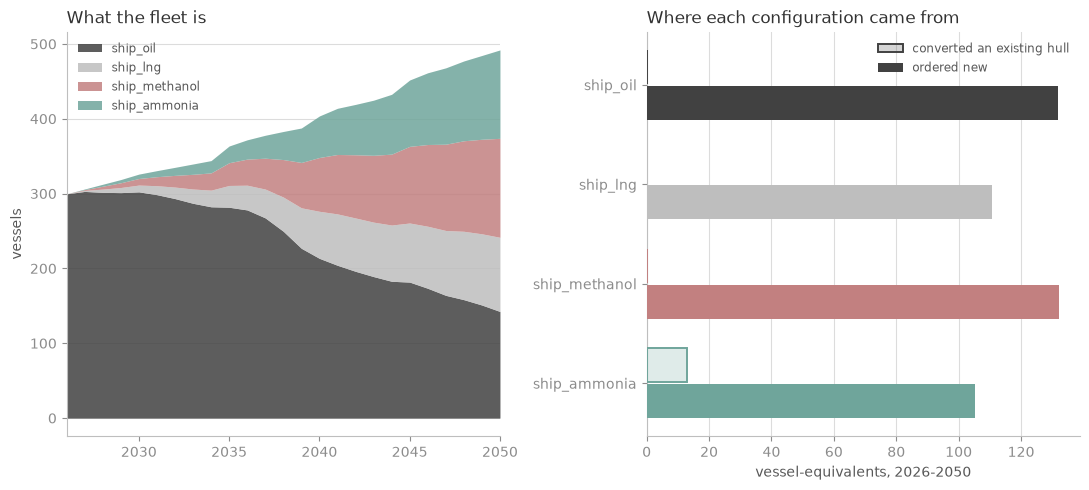

In [39]:
# @title Figure: fleet evolution
# One figure for the fleet: what it is at each date, and where each configuration
# came from.
from matplotlib.colors import to_rgba


def sum_over(d):
    """Sum a profile dict of per-vessel (or per-pair) series into one series."""
    return sum(np.nan_to_num(np.asarray(v, dtype=float)) for v in d.values())


hulls = pd.DataFrame({config_label(k): np.nan_to_num(np.asarray(v, dtype=float))
                      for k, v in copper_trade.profile.get_existing_vessels().items()},
                     index=YEARS)

# Where each configuration's hulls came from, summed over the horizon. A retrofit
# is credited to what the hull BECOMES, so both bars answer one question: how did
# this configuration get here?
arrived = {}
for (_from, _to), _series in copper_trade.profile.get_fuel_conversions().items():
    _total = float(np.nansum(_series))
    if _total > 1e-6:
        arrived.setdefault(_to, {"retrofitted": 0., "ordered": 0.})["retrofitted"] += _total
for _config, _series in copper_trade.profile.get_newbuilds().items():
    _total = float(np.nansum(_series))
    if _total > 1e-6:
        arrived.setdefault(_config, {"retrofitted": 0., "ordered": 0.})["ordered"] += _total
routes = pd.DataFrame(arrived).T.reindex([c for c in CONFIGS if c in arrived])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5.0))

hulls.plot.area(ax=ax1, linewidth=0, alpha=0.85,
                color=[config_colour(c) for c in hulls.columns])
ax1.set_title("What the fleet is", fontsize=12.5, color=INK, loc="left")
ax1.set_ylabel("vessels", fontsize=10, color=SUBINK)
ax1.margins(x=0)
ax1.legend(fontsize=8.75, frameon=False, labelcolor=SUBINK, loc="upper left")

# Same grammar as the belief-vs-commitment figure in Stage 4: hollow for the
# route that reuses what is already there, solid for the one that buys new.
for i, name in enumerate(routes.index):
    ax2.barh(i - .18, routes.loc[name, "retrofitted"], height=.34,
             facecolor=to_rgba(config_colour(name), .22),
             edgecolor=config_colour(name), linewidth=1.4, zorder=3,
             label="converted an existing hull" if i == 0 else None)
    ax2.barh(i + .18, routes.loc[name, "ordered"], height=.34,
             color=config_colour(name), zorder=3,
             label="ordered new" if i == 0 else None)
ax2.set_yticks(list(range(len(routes))), [config_label(n) for n in routes.index])
ax2.invert_yaxis()
ax2.set_title("Where each configuration came from", fontsize=12.5, color=INK, loc="left")
ax2.set_xlabel(f"vessel-equivalents, {YEARS[0]}-{YEARS[-1]}", fontsize=10, color=SUBINK)
ax2.legend(fontsize=8.75, frameon=False, labelcolor=SUBINK)

for ax in (ax1, ax2):
    ax.grid(axis="y" if ax is ax1 else "x", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TICK, labelsize=10)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)

fig.tight_layout()

_total = hulls.sum(axis=1)
_scrapped = float(np.nansum(sum_over(copper_trade.profile.get_scrap())))
print(f"fleet {_total.iloc[0]:.0f} -> {_total.iloc[-1]:.0f} hulls;  over the horizon "
      f"{routes['ordered'].sum():.0f} ordered, {routes['retrofitted'].sum():.0f} "
      f"converted, {_scrapped:.0f} scrapped")
plt.show()

#### Energy efficiency over the horizon

The next cell shows which efficiency technologies are fitted to the fleet over time, and how much energy they save.

technology energy saving:  2026  1.3%   2038 12.9%   2050 20.5%


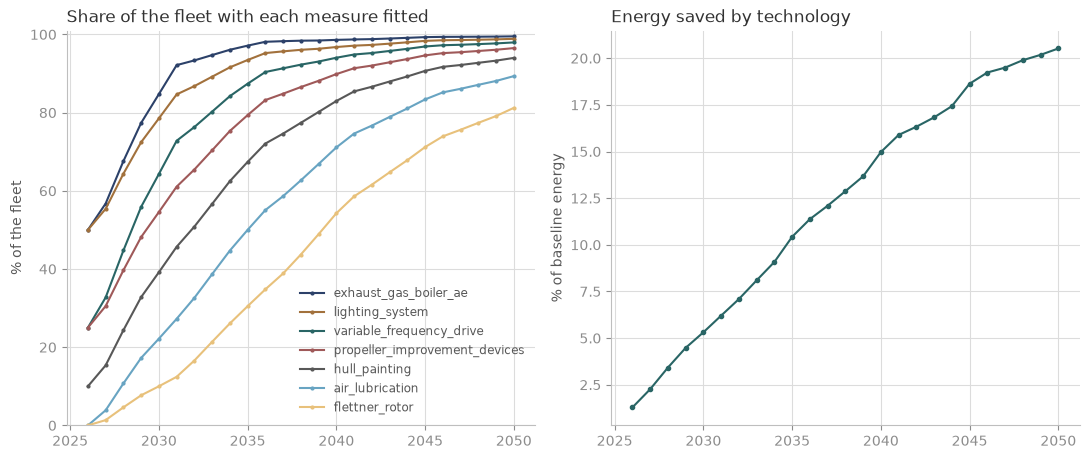

In [40]:
# @title Figure: efficiency technology over time
# What got fitted, and when.
#
# get_technology_uptake() is keyed by (vessel, technology) and each entry is that
# CONFIGURATION's share, so adding them up gives a number that runs to 4.0 on a
# four-configuration fleet and is not a share of anything. fleet_technology_uptake()
# (Stage 2 above) weights each configuration by how many hulls it has, which is
# bounded by 1 - and is what Navigate's own technology_uptake plot draws.
fitted = pd.DataFrame({str(k).replace("_bulk_carrier_panamax", ""):
                       100. * np.nan_to_num(np.asarray(v, dtype=float))
                       for k, v in
                       fleet_technology_uptake(copper_trade.profile).items()},
                      index=YEARS)
fitted = fitted.loc[:, fitted.max() > 1e-4]
# legend in the model's ladder order, cheapest first
_ladder_order = [t.get_name().replace("_bulk_carrier_panamax", "")
                 for t in copper_trade.technology_packages[-1].technologies]
fitted = fitted[[n for n in _ladder_order if n in fitted]]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.7))

fitted.plot(ax=ax1, marker=".", ms=4, color=series_colours(fitted.columns))
ax1.set_title("Share of the fleet with each measure fitted", fontsize=12.5, color=INK,
              loc="left")
ax1.set_ylabel("% of the fleet", fontsize=10, color=SUBINK)
ax1.set_ylim(0, 101)
ax1.legend(fontsize=8.75, frameon=False, labelcolor=SUBINK)

saving = np.nan_to_num(copper_trade.profile.get_technology_energy_saving()) * 100
ax2.plot(YEARS, saving, marker="o", ms=3, color=GREEN)
ax2.set_title("Energy saved by technology", fontsize=12.5, color=INK, loc="left")
ax2.set_ylabel("% of baseline energy", fontsize=10, color=SUBINK)

for ax in (ax1, ax2):
    ax.grid(color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TICK, labelsize=10)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)

fig.tight_layout()

print(f"technology energy saving:  {YEARS[0]} {saving[0]:4.1f}%"
      f"   {YEARS[len(YEARS) // 2]} {saving[len(saving) // 2]:4.1f}%"
      f"   {YEARS[-1]} {saving[-1]:4.1f}%")
plt.show()


### 2. Fuel supply and demand

#### What each fuel costs to make

The next cell shows the calculated production cost of each fuel, per GJ, for one plant sanctioned in 2026 and one sanctioned in 2040, at the plant size used in that year. It covers bio-methanol as well as the e-fuels.

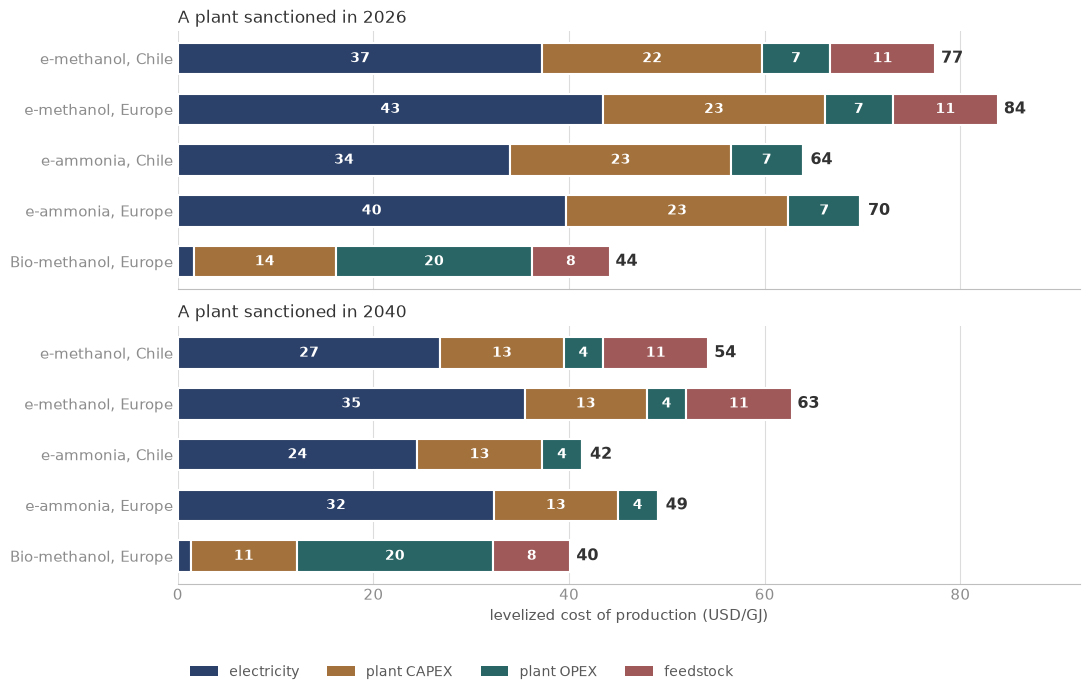

In [41]:
# @title Figure: production cost of each fuel
# Navigate reports one levelized cost per plant (navigate/fuel/production.py).
# It is linear in the cost flows, so each part is the same calculation with only
# that flow switched on, and the parts add up to the model's total.
import copy
from contextlib import contextmanager

from matplotlib.patches import Patch
from navigate.fuel import production

COST_STEPS = ["_calculate_process_cost", "_calculate_energy_cost",
              "_calculate_feedstock_cost", "_calculate_transport_cost"]
PARTS = {  # part: (the cost step kept on, the flow type dropped from it)
    "plant CAPEX": ("_calculate_process_cost", "add_fixed_opex"),
    "plant OPEX": ("_calculate_process_cost", "add_capex_flow"),
    "electricity": ("_calculate_energy_cost", None),
    "feedstock": ("_calculate_feedstock_cost", None),
    "transport": ("_calculate_transport_cost", None),
}


@contextmanager
def only(step, dropped):
    """Switch off every cost step but `step`, and `dropped` within it."""
    names = COST_STEPS + ["add_capex_flow", "add_fixed_opex"]
    saved = {name: getattr(production, name) for name in names}
    off = lambda *args, **kwargs: None
    try:
        for name in COST_STEPS:
            if name != step:
                setattr(production, name, off)
        if dropped:
            setattr(production, dropped, off)
        yield
    finally:
        for name, function in saved.items():
            setattr(production, name, function)


def levelized_parts(plant, idx):
    """USD/GJ per part for a plant sanctioned at time step `idx`, on a copy of it."""
    timeline, emissions = base.get_timeline(), base.nodes.emissions
    lhv = plant.fuel.lower_heating_value.get()
    parts = {}
    for part, (step, dropped) in PARTS.items():
        trial = copy.deepcopy(plant)
        with only(step, dropped):
            production.calculate_plant_production_expectations(trial, emissions, timeline, idx)
        parts[part] = trial.expectation.get_levelized_production_cost(idx) / lhv
    total = plant.profile.get_investment_cost()[idx] / lhv
    assert abs(sum(parts.values()) - total) < 1e-6 * total, (plant.get_name(), parts, total)
    return parts


_REGION = {"americas": "Chile", "europe": "Europe"}
_SANCTIONED = [2026, 2040]
_FUEL_ROWS = ["methanol_electro", "ammonia_electro", "methanol_bio"]
_plants = sorted(base.nodes.plants.values(),
                 key=lambda p: (_FUEL_ROWS.index(p.fuel.get_name()), p.region.get_name()))
_rows = [f"{fuel_label(p.fuel.get_name())}, {_REGION.get(p.region.get_name(), p.region.get_name())}"
         for p in _plants]

_DRAWN = [("electricity", BLUE), ("plant CAPEX", ORANGE),
          ("plant OPEX", GREEN), ("feedstock", series_colours(4)[3])]

_costs = {year: [levelized_parts(p, list(YEARS).index(year)) for p in _plants]
          for year in _SANCTIONED}
_xmax = max(sum(parts.values()) for year in _SANCTIONED for parts in _costs[year]) * 1.1

fig, axes = plt.subplots(len(_SANCTIONED), 1, figsize=(11, 7.0), sharex=True)
for ax, year in zip(axes, _SANCTIONED):
    _left = [0.] * len(_plants)
    for part, colour in _DRAWN:
        _values = [parts[part] for parts in _costs[year]]
        ax.barh(range(len(_plants)), _values, left=_left, height=.62, color=colour,
                zorder=3, edgecolor="white", linewidth=1.5)
        for i, (value, start) in enumerate(zip(_values, _left)):
            if value >= 4.:              # only where the segment can hold a number
                ax.annotate(f"{value:.0f}", (start + value / 2, i), ha="center",
                            va="center", fontsize=10, color="white", fontweight="bold",
                            zorder=5)
        _left = [a + b for a, b in zip(_left, _values)]
    for i, total in enumerate(_left):
        ax.annotate(f"{total:.0f}", (total + 0.6, i), va="center", fontsize=11.25,
                    color=INK, fontweight="bold")
    ax.set_title(f"A plant sanctioned in {year}", fontsize=12.5, color=INK, loc="left")
    ax.set_yticks(range(len(_plants)), _rows)
    ax.set_xlim(0, _xmax)
    ax.invert_yaxis()
    ax.grid(axis="x", color=GRID, lw=.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TICK, labelsize=10.625, length=0)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)

axes[-1].set_xlabel("levelized cost of production (USD/GJ)", fontsize=10.625, color=SUBINK)
axes[-1].legend(handles=[Patch(facecolor=colour, label=part) for part, colour in _DRAWN],
                fontsize=10, frameon=False, labelcolor=SUBINK, ncol=4,
                loc="lower left", bbox_to_anchor=(0, -.42))
fig.tight_layout()
plt.show()


#### What the fleet bunkers, and when

The next cell shows the energy the fleet bunkers each year, by fuel, first for the whole fleet and then for each ship type. A dual-fuel ship that bunkers oil counts as oil here.

Share of total energy over 2026-2050:
  Fuel oil                    73.8%
  LNG                         12.8%
  Bio-methanol                 5.7%
  e-ammonia                    7.2%
  e-methanol                   0.5%


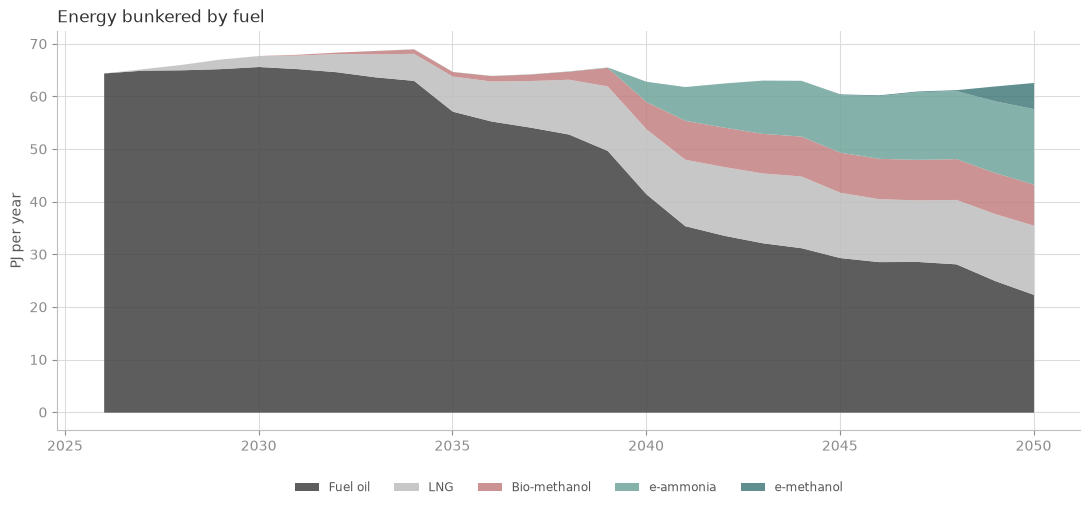

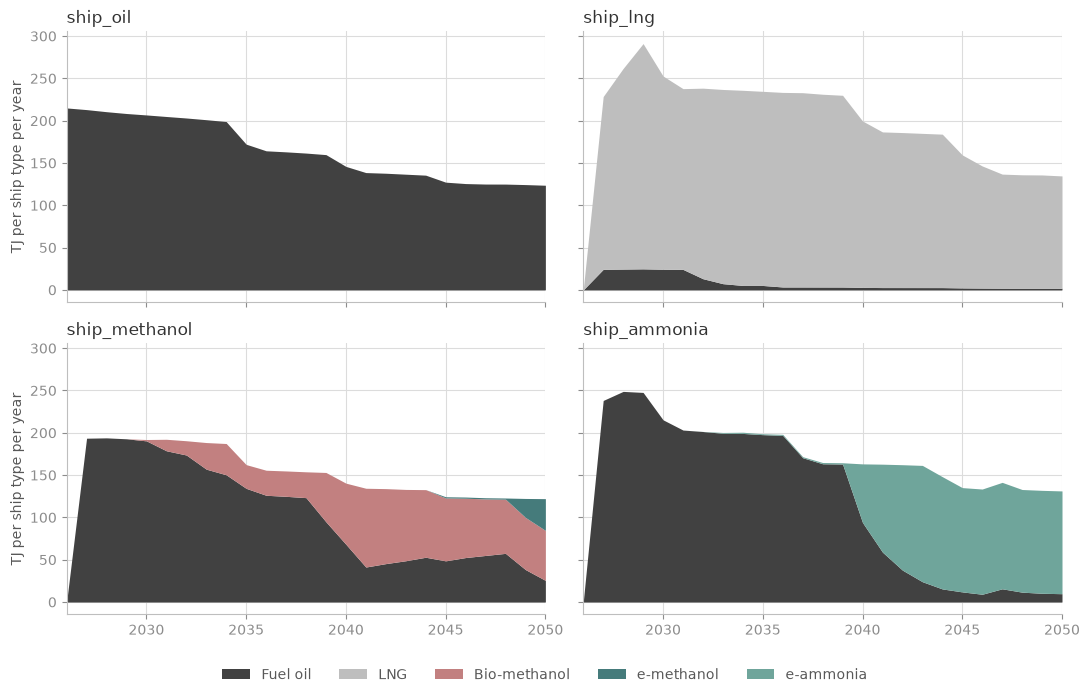

In [42]:
# @title Figure: energy bunkered by fuel
fuels = fuel_frame(base)
fuels = fuels[fuel_sorted(fuels.columns)]      # Navigate's own stacking order
_fc = [fuel_colour(f) for f in fuels.columns]
# fuel_frame is in GJ; PJ keeps the axis to two digits, as the producer panels use
_show = (fuels / 1e6).rename(columns=fuel_label)   # "Bio-methanol", not "methanol_bio"

fig, ax1 = plt.subplots(figsize=(11, 5.2))

_show.plot.area(ax=ax1, linewidth=0, alpha=0.85, color=_fc)
ax1.set_title("Energy bunkered by fuel", fontsize=12.5, color=INK, loc="left")
ax1.set_ylabel("PJ per year", fontsize=10, color=SUBINK)
ax1.legend(fontsize=8.75, frameon=False, labelcolor=SUBINK, ncol=5,
           loc="upper center", bbox_to_anchor=(0.5, -0.10))
ax1.grid(color=GRID, lw=0.8)
ax1.set_axisbelow(True)
ax1.tick_params(colors=TICK, labelsize=10)
for side in ("top", "right"):
    ax1.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax1.spines[side].set_color(AXIS)

fig.tight_layout()

print("Share of total energy over 2026-2050:")
energy_share = (fuels.sum() / fuels.sum().sum() * 100).round(1)
for k, v in energy_share.items():
    print(f"  {fuel_label(k):26} {v:5.1f}%")
plt.show()


# The fleet view above hides which HULL burned what, and that is what explains the
# compliance bills in Stage 1: a methanol ship that cannot get methanol burns oil and
# pays for it. One panel per configuration, in Navigate's own fuel colours.
#
# Note this is what was actually bunkered, not what the look-ahead expected. Navigate
# resets the expected-bunkering accumulator on every forward solve, so the expectation
# is only ever the latest year - the realised series is the one that can be read back.
from navigate.illustrations.plots._labels import FUEL_ORDER

fig, axes = plt.subplots(2, 2, figsize=(11, 7.0), sharex=True, sharey=True)
axes = axes.ravel()

for ax, name in zip(axes, CONFIGS):
    consumed = base.nodes.vessels[name].profile.get_consumed_energy()
    frame = pd.DataFrame({f: np.nan_to_num(np.asarray(v, dtype=float))
                          for f, v in consumed.items()}, index=YEARS)
    frame = frame.loc[:, frame.sum() > 0]
    order = [f for f in FUEL_ORDER if f in frame.columns]

    bottom = np.zeros(len(frame))
    for fuel in order:
        values = frame[fuel].to_numpy() / 1e3
        ax.fill_between(YEARS, bottom, bottom + values, color=fuel_colour(fuel),
                        label=fuel_label(fuel), linewidth=0)
        bottom += values

    ax.set_title(name, fontsize=11.875, color=INK, loc="left")
    ax.set_xlabel("")
    ax.grid(color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TICK, labelsize=10)
    ax.margins(x=0)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)

for ax in (axes[0], axes[2]):
    ax.set_ylabel("TJ per ship type per year", fontsize=10, color=SUBINK)

# one legend for the four panels, listing every fuel that appears in any of them
seen = {}
for ax in axes:
    for handle, label in zip(*ax.get_legend_handles_labels()):
        seen.setdefault(label, handle)
fig.legend(seen.values(), seen.keys(), fontsize=10, frameon=False, labelcolor=SUBINK,
           ncol=len(seen), loc="lower center", bbox_to_anchor=(0.5, 0.0))
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

#### What the feedstock ceilings decided

The next cell shows the two feedstock ceilings of this example against what the plants actually used: gasification biomass, which limits bio-methanol and binds from 2041, and biogenic CO2, which limits e-methanol and binds only in the last year, 2050. Once a ceiling binds, the fuel it limits cannot grow any further, and any extra demand has to go to other fuels.


  Gasification feedstock     ceiling  0.95 Mt/yr by 2050,   binds from 2041, in 10 of 25 years
  Biogenic CO2 (PS)          ceiling  0.53 Mt/yr by 2050,   binds from 2050, in 1 of 25 years


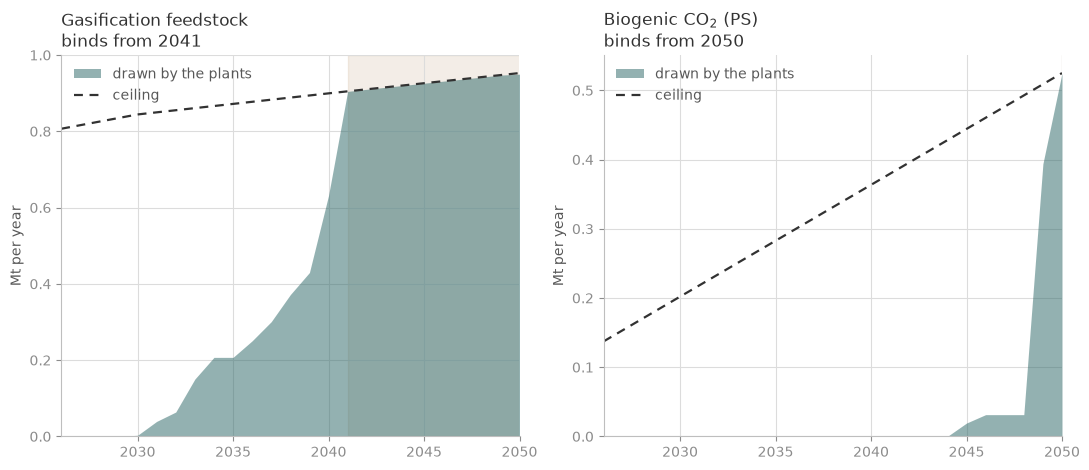

In [43]:
# @title Figure: feedstock ceilings against what was used
# The same two ceilings as Part 2, now against what the run drew. Consumption is
# a run output - the profile aggregates it, and each constrained feed has one
# producer in this deck, so the two line up. The ceilings are reused from
# CEILINGS rather than recomputed: they are deck inputs and have not moved.
DREW = []
for _c in CEILINGS:
    _drawn = np.nan_to_num(np.asarray(
        base.profile.get_feed_mass(_c["feed"]), dtype=float)) / 1e6
    _tight = _drawn >= 0.99 * _c["cap"]
    DREW.append({**_c, "drawn": _drawn, "tight": _tight,
                 "from": int(YEARS[_tight][0]) if _tight.any() else None,
                 "count": int(_tight.sum()),
                 "peak": float(np.nanmax(_drawn / _c["cap"]))})

fig, axes = plt.subplots(1, len(DREW), figsize=(11, 4.8), sharex=True)

for ax, c in zip(np.atleast_1d(axes), DREW):
    ax.fill_between(YEARS, 0., c["drawn"], color=GREEN, alpha=.5, linewidth=0,
                    label="drawn by the plants")
    ax.plot(YEARS, c["cap"], color=INK, lw=1.6, ls=(0, (4, 3)), label="ceiling")
    if c["from"]:
        # the years the ceiling, rather than the price, is deciding
        ax.axvspan(c["from"], YEARS[-1], color=ORANGE, alpha=.12, zorder=0)
        head = f"binds from {c['from']}"
    else:
        head = f"never binds \u2014 peak {100 * c['peak']:.0f}% of it"
    ax.set_title(f"{FEEDSTOCK_LABEL.get(c['feed'], c['feed'])}\n{head}",
                 fontsize=12.5, color=INK, loc="left")
    ax.set_ylabel("Mt per year", fontsize=10, color=SUBINK)
    ax.set_ylim(bottom=0.)
    ax.margins(x=0)
    ax.legend(fontsize=10, frameon=False, labelcolor=SUBINK, loc="upper left")
    ax.grid(color=GRID, lw=.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TICK, labelsize=10)
    for _side in ("top", "right"):
        ax.spines[_side].set_visible(False)
    for _side in ("left", "bottom"):
        ax.spines[_side].set_color(AXIS)

fig.tight_layout()

for c in DREW:
    _name = FEEDSTOCK_LABEL.get(c["feed"], c["feed"]).replace("$_2$", "2").replace("$", "")
    _when = (f"binds from {c['from']}, in {c['count']} of {len(YEARS)} years"
             if c["from"] else
             f"never binds, peak draw {100 * c['peak']:.0f}% of it")
    print(f"  {_name:26} ceiling {c['cap'][-1]:5.2f} Mt/yr by {YEARS[-1]},"
          f"   {_when}")
plt.show()

#### What the producers sanctioned, and the lag before it arrives

The operators and the fuel producers never talk directly. The producers build
plants for the fuel the fleet **expects** to buy, and the fleet can only buy what
the producers make. This creates a delay, on purpose: the producers use the
fleet's expectation from the start of the year, before that year's new ships and
retrofits, and a plant then takes several years to build.

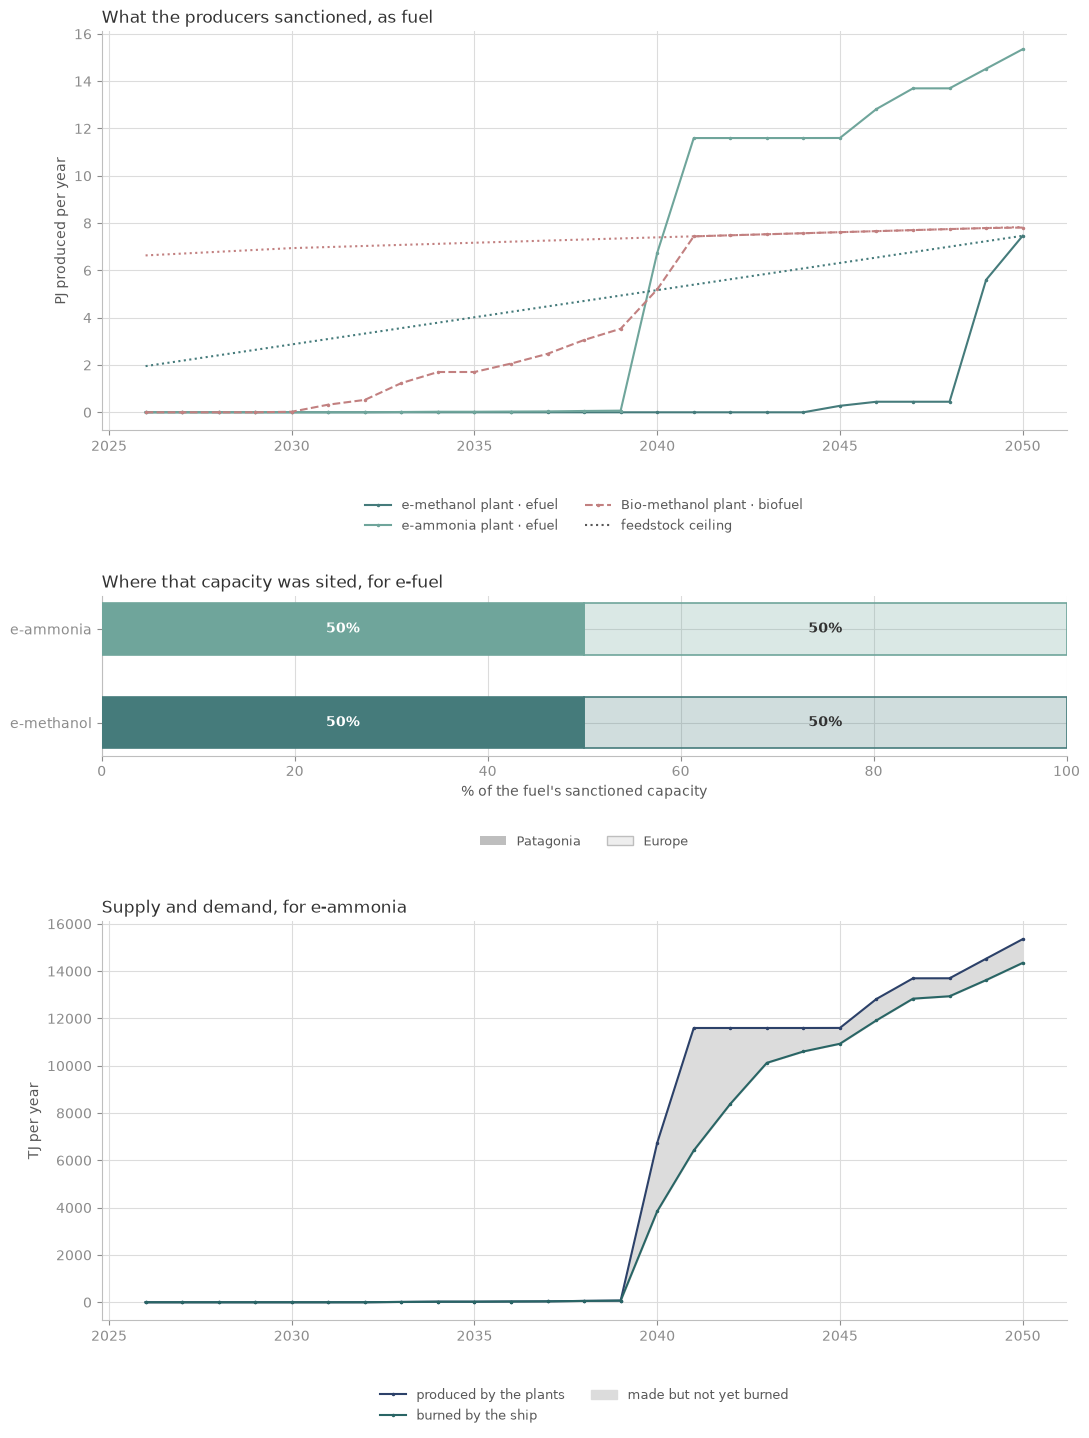

  first capacity sanctioned: 2028
  first e-ammonia burned:  2032
  production vs delivery, largest gap over the horizon: 0.0 TJ/year

The e-fuel producer owns both sites for each of its fuels, so it splits
its build between them on delivered cost instead of picking one.


In [44]:
# @title Figure: producers, siting, and supply against demand
FUEL = "ammonia_electro"        # the largest e-fuel in the baseline; the others behave the same

# one panel per row, so each gets the full width of the page
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(11, 14.5),
                                    gridspec_kw={"height_ratios": [1, .4, 1]})

# What those sanctions actually produce. A plant COUNT is not comparable across
# fuels or across years: an ammonia plant and a methanol plant are different
# sizes, and the library's capacity forecast grows over the horizon, so a plant
# built in 2030 is smaller than one built in 2040. Energy is the common unit, and
# get_production_energy is the model's own number rather than count x capacity.
# Colour is the fuel, so two plants making it share one - the region is the dash.
for _producer in base.nodes.producers.values():
    for _fuel, _series in _producer.profile.get_production_energy().items():
        _made = np.nan_to_num(np.asarray(_series, dtype=float)) / 1e6
        if _made.max() <= 0:
            continue
        ax1.plot(YEARS, _made, marker=".", ms=3, color=fuel_colour(_fuel),
                 ls="-" if "efuel" in _producer.get_name() else "--",
                 label=f"{fuel_label(_fuel)} plant \u00b7 "
                       f"{_producer.get_name().replace('producer_', '')}")
ax1.set_title("What the producers sanctioned, as fuel", fontsize=12.5, color=INK,
              loc="left")
ax1.set_ylabel("PJ produced per year", fontsize=10, color=SUBINK)

# The feedstock ceilings, drawn as the most fuel they allow. A Conversions entry
# is tons of feed per ton of fuel, so the ceiling over it, times the heating
# value, is the production that ceiling caps. Only a ceiling production actually
# comes near is drawn: e-ammonia has no constrained feed at all, and one sitting
# far above its fuel says nothing and flattens everything else into the floor.
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D

NEAR = 0.5          # near enough to draw: production reaches half of it


def _resolve(node, when):
    """A deck number that may be a Forecast, an Expression or a plain value."""
    if hasattr(node, "calculate"):
        return float(node.calculate(when))
    try:
        return float(node.get(when))
    except TypeError:
        return float(node.get())


_days = base.get_timeline()
_drew_ceiling = False
for _producer in base.nodes.producers.values():
    for _feed, _node in _producer.feed_constraints.items():
        if _node is None:
            continue
        for _plant in _producer.get_plants():
            _names = [f.get_name() for f in _plant.process.feeds]
            if _feed not in _names:
                continue
            _fuel_name = _plant.fuel.get_name()
            _conv = _resolve(_plant.process.conversions[_names.index(_feed)], 0.)
            _lhv = float(_plant.fuel.lower_heating_value.get())
            _cap = np.array([_resolve(_node, _w) for _w in _days]) / _conv * _lhv / 1e6
            _drawn = np.nan_to_num(np.asarray(
                _producer.profile.get_production_energy(_fuel_name), dtype=float)) / 1e6
            if np.nanmax(_drawn / _cap) >= NEAR:
                ax1.plot(YEARS, _cap, ls=":", lw=1.5, zorder=2,
                         color=fuel_colour(_fuel_name))
                _drew_ceiling = True
            break          # the plants of one producer share the one ceiling

_h, _l = ax1.get_legend_handles_labels()
if _drew_ceiling:
    _h = _h + [Line2D([], [], ls=":", lw=1.5, color=SUBINK)]
    _l = _l + ["feedstock ceiling"]
ax1.legend(_h, _l, fontsize=9.375, frameon=False, labelcolor=SUBINK, ncol=2,
           loc="upper center", bbox_to_anchor=(0.5, -0.14))

# ---- where that capacity was sited -----------------------------------------
# The producer owns two sites for each e-fuel. This is the capacity each site
# started, summed over the horizon. It is capacity sanctioned, not output: Navigate records production per (producer, fuel) and
# never per plant, so the realised split by region is not something the run can
# be asked for.
REGION_LABEL = {"americas": "Patagonia", "europe": "Europe"}
sited = {}
for _step in STEPS:
    for _asset, _seen in snaps[_step]["producer"].items():
        _built = _seen.get("plants_built", 0.)
        if _built <= 0:
            continue
        _plant = base.nodes.plants[_asset]
        _key = (_plant.fuel.get_name(), _plant.region.get_name())
        sited[_key] = sited.get(_key, 0.) + (
            _built * _seen["plant_output"] * _seen["lhv"] / 1e3)

# Only a fuel the producer could have built in more than one place. Bio-methanol
# has just the one site, so its 100% is an artefact of there being no choice, not
# a decision the delivered-cost axis made.
_sited_fuels = fuel_sorted({f for f, _r in sited
                            if sum(v for (ff, _rr), v in sited.items() if ff == f) > 0
                            and len({r for ff, r in sited if ff == f}) > 1})
_sited_regions = sorted({r for _f, r in sited})
for _i, _f in enumerate(_sited_fuels):
    _tot = sum(v for (ff, _r), v in sited.items() if ff == _f)
    _left = 0.
    for _r in _sited_regions:
        _pct = 100. * sited.get((_f, _r), 0.) / _tot
        if _pct <= 0:
            continue
        _solid = _r == "americas"
        ax2.barh(_i, _pct, left=_left, height=.55, zorder=3,
                 facecolor=fuel_colour(_f) if _solid else to_rgba(fuel_colour(_f), .25),
                 edgecolor=fuel_colour(_f), linewidth=1.2)
        if _pct >= 12:
            ax2.annotate(f"{_pct:.0f}%", (_left + _pct / 2, _i), ha="center",
                         va="center", fontsize=10, fontweight="bold", zorder=5,
                         color="white" if _solid else INK)
        _left += _pct
ax2.set_yticks(range(len(_sited_fuels)), [fuel_label(f) for f in _sited_fuels])
ax2.invert_yaxis()
ax2.set_xlim(0, 100)
ax2.set_title("Where that capacity was sited, for e-fuel", fontsize=12.5,
              color=INK, loc="left")
ax2.set_xlabel("% of the fuel's sanctioned capacity", fontsize=10, color=SUBINK)
ax2.legend(handles=[Patch(facecolor=MUTED, label=REGION_LABEL["americas"]),
                    Patch(facecolor=to_rgba(MUTED, .25), edgecolor=MUTED,
                          label=REGION_LABEL["europe"])],
           fontsize=9.375, frameon=False, labelcolor=SUBINK, ncol=2,
           loc="upper center", bbox_to_anchor=(0.5, -0.42))

# The lag, for one fuel: what the plants made, and what the ship burned. In a
# closed two-port system everything made is delivered - see the check printed
# below - so the bottleneck is never the port; it is the plant and its build
# lead time.
consumed = np.nan_to_num(np.asarray(
    copper_trade.profile.get_consumed_energy(FUEL), dtype=float))
produced = np.nan_to_num(np.asarray(
    sum(p.profile.get_production_energy(FUEL) for p in base.nodes.producers.values()
        if p.can_produce(FUEL)), dtype=float))
supply = np.nan_to_num(np.asarray(
    sum(port.profile.get_bunker_supply_energy(FUEL) for port in base.nodes.ports.values()),
    dtype=float))

ax3.plot(YEARS, produced / 1e3, label="produced by the plants",
         marker=".", ms=3, color=BLUE)
ax3.plot(YEARS, consumed / 1e3, label="burned by the ship",
         marker=".", ms=3, color=GREEN)
ax3.fill_between(YEARS, consumed / 1e3, produced / 1e3, color=PALE, zorder=0,
                 label="made but not yet burned")
ax3.set_title(f"Supply and demand, for {fuel_label(FUEL)}", fontsize=12.5, color=INK,
              loc="left")
ax3.set_ylabel("TJ per year", fontsize=10, color=SUBINK)
ax3.legend(fontsize=9.375, frameon=False, labelcolor=SUBINK, ncol=2,
           loc="upper center", bbox_to_anchor=(0.5, -0.14))

for ax in (ax1, ax2, ax3):
    ax.grid(color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TICK, labelsize=10)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)

fig.tight_layout(h_pad=2.5)
plt.show()

# the lag, as two dates rather than a shape
_first_burn = next((y for y, c in zip(YEARS, consumed) if c > 0), None)
_dev = [np.nan_to_num(np.asarray(p.profile.get_cumulative_development(), dtype=float))
        for p in base.nodes.producers.values() if p.can_produce(FUEL)]
_sanctioned = sum(_dev) if _dev else np.zeros(len(YEARS))
_first_plant = next((y for y, d in zip(YEARS, _sanctioned) if d > 0), None)
print(f"  first capacity sanctioned: {_first_plant}")
print(f"  first {fuel_label(FUEL)} burned:  {_first_burn}")
print(f"  production vs delivery, largest gap over the horizon: "
      f"{np.max(np.abs(supply - produced)) / 1e3:,.1f} TJ/year")
print()
print("The e-fuel producer owns both sites for each of its fuels, so it splits")
print("its build between them on delivered cost instead of picking one.")

### 3. What the regulations did

The next cell shows the GHG intensity each ship type achieved with the fuel it
burned, against the FuelEU limit: on green ground it earns surplus, on red ground
it has to buy compliance. The right panel shows the fleet's well-to-wake emissions
over time.

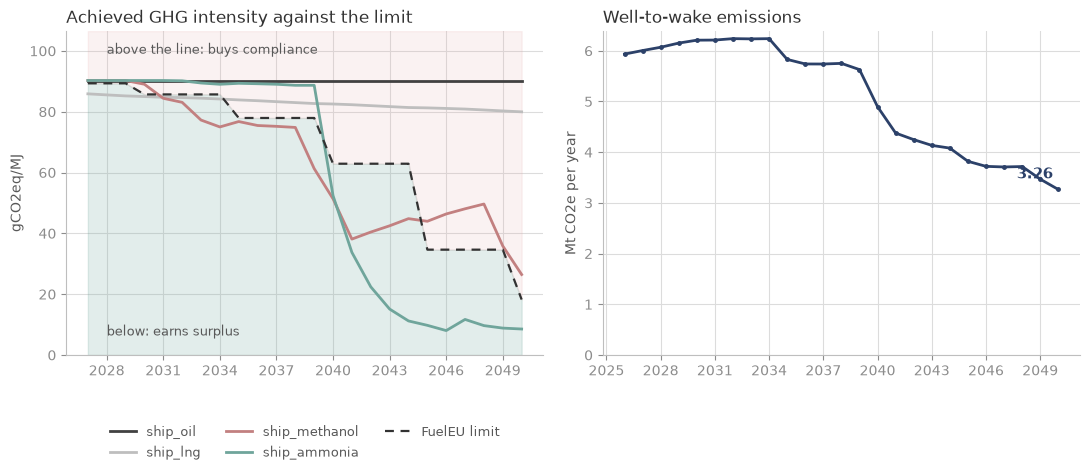

  well-to-wake 2026:    5.93 Mt/yr   2050:    3.26 Mt/yr   over the horizon     127.4 Mt
  EU ETS   2027:     334 M USD   2050:     529 M USD   over the horizon    11,484 M USD
  FuelEU   2027:      23 M USD   2050:     839 M USD   over the horizon     8,089 M USD
  ship_oil        below the limit in  0 of 24 years
  ship_lng        below the limit in  8 of 24 years
  ship_methanol   below the limit in 14 of 24 years
  ship_ammonia    below the limit in 11 of 24 years


In [45]:
# @title Figure: GHG intensity and emissions
# The compliance panel borrows regulation_compliance.py's colours - COMPLIANT
# and BREACH are that module's own green and red - but not its shading. The
# library splits each measured value at the threshold and stacks the two halves;
# here the GROUND is shaded instead, so four hulls can be drawn over it and
# compared. Beside it, the emissions the fleet ends up with - the line the whole
# compliance story is trying to bend.
from matplotlib.ticker import MaxNLocator
# status colours, imported here rather than in Part 2's setup cell so this
# section stays self-contained
from _style import BREACH, COMPLIANT

fuel_eu = base.nodes.regulations["fuel_eu"]
eu_ets = base.nodes.regulations["eu_ets"]


def whole(getter):
    return np.nan_to_num(np.asarray(getter(), dtype=float))


# step 0 takes no decisions, so compliance is not computed there - start at the
# first year that has one, or the lines drop to zero and the axis follows them
live = slice(1, None)

fig, (axL, axR) = plt.subplots(1, 2, figsize=(11, 5.2))

# ---- 1. over and under the limit -------------------------------------------
# FuelEU credits the fuel actually burned, not the hull's capability, so what
# matters is the BLENDED intensity each configuration achieves.
limit = whole(fuel_eu.profile.get_shared_threshold)
achieved = fuel_eu.profile.get_vessel_compliance()
_top = max(limit[live].max(),
           max(whole(lambda n=n: achieved[n])[live].max() for n in CONFIGS)) * 1.18

# the ground, as the library shades it: compliant below the threshold, breach above
axL.fill_between(YEARS[live], 0., limit[live], color=COMPLIANT, alpha=.20, zorder=1)
axL.fill_between(YEARS[live], limit[live], _top, color=BREACH, alpha=.14, zorder=1)
for name in CONFIGS:
    axL.plot(YEARS[live], whole(lambda n=name: achieved[n])[live], lw=2,
             color=config_colour(name), label=config_label(name), zorder=3)
axL.plot(YEARS[live], limit[live], lw=1.6, ls=(0, (4, 3)), color=INK,
         label="FuelEU limit", zorder=4)
axL.annotate("above the line: buys compliance", (YEARS[2], _top * .93),
             fontsize=9.375, color=SUBINK)
axL.annotate("below: earns surplus", (YEARS[2], _top * .06), fontsize=9.375,
             color=SUBINK)
axL.set_title("Achieved GHG intensity against the limit", fontsize=12.5, color=INK,
              loc="left")
axL.set_ylabel("gCO2eq/MJ", fontsize=10, color=SUBINK)
axL.set_ylim(0, _top)
axL.legend(fontsize=9.375, frameon=False, labelcolor=SUBINK, ncol=3,
           loc="upper center", bbox_to_anchor=(0.5, -0.18))

# ---- 2. what it all adds up to ---------------------------------------------
# The same series notebook 3 plots for the whole world fleet, here for one
# trade: WELL-TO-WAKE, so how each fuel was made counts too, not just the
# funnel. Every lever in Session 1 is ultimately aimed at this line.
# Mt, not kt: get_best_unit_mass picks Mt/year at this fleet's magnitude, so
# fleet_emission_absolute.py would label it the same way. Session 1's sensitivity analysis reports
# the same quantity in kt, where a one-per-cent change still has to be legible.
_wtw = whole(copper_trade.profile.get_total_equivalent_WTW) / 1e6
axR.plot(YEARS, _wtw, lw=2, marker=".", ms=5, color=BLUE)
axR.annotate(f"{_wtw[-1]:,.2f}", (YEARS[-1], _wtw[-1]), xytext=(-4, 8),
             textcoords="offset points", ha="right", fontsize=10.625,
             color=BLUE, fontweight="bold")
axR.set_title("Well-to-wake emissions", fontsize=12.5, color=INK, loc="left")
axR.set_ylabel("Mt CO2e per year", fontsize=10, color=SUBINK)
axR.set_ylim(bottom=0.)

for ax in (axL, axR):
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TICK, labelsize=10)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)

fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

print(f"  {'well-to-wake':8} {YEARS[0]}: {_wtw[0]:7,.2f} Mt/yr   "
      f"{YEARS[-1]}: {_wtw[-1]:7,.2f} Mt/yr   "
      f"over the horizon {_wtw.sum():9,.1f} Mt")
for _name, _reg in (("EU ETS", eu_ets), ("FuelEU", fuel_eu)):
    _bill = (whole(_reg.profile.get_remedial_expenses)
             + whole(_reg.profile.get_flexibility_expenses)) / 1e6
    print(f"  {_name:8} {YEARS[1]}: {_bill[1]:7,.0f} M USD   "
          f"{YEARS[-1]}: {_bill[-1]:7,.0f} M USD   "
          f"over the horizon {_bill[live].sum():9,.0f} M USD")
for _name in CONFIGS:
    _under = int(np.sum(whole(lambda n=_name: achieved[n])[live] < limit[live]))
    print(f"  {_name:15} below the limit in {_under:2d} of {len(YEARS) - 1} years")

### 4. What the trade cost

The next cell shows:

- The **instantaneous freight rate** on the fleet: what the trade cost in that year, given the fuel prices and compliance bills that actually materialised.
- The **investment freight rate** on each vessel configuration: the
  forward-looking, levelized cost of transport. This is the number the
  discrete-choice model compares between configurations, so it is what explains *why* one was picked. A configuration that is not in the fleet in a given year has no value and simply does not plot.

These numbers are calculated before any redistribution mechanisms of the collected taxes. 

instantaneous freight rate   2026: 3.43   2050: 4.71   (+37%)

In the right-hand panel, whichever configuration sits lowest in a given
year is the one most likely to be ordered that year. That crossover is
the mechanism behind the fuel mix in section 2.


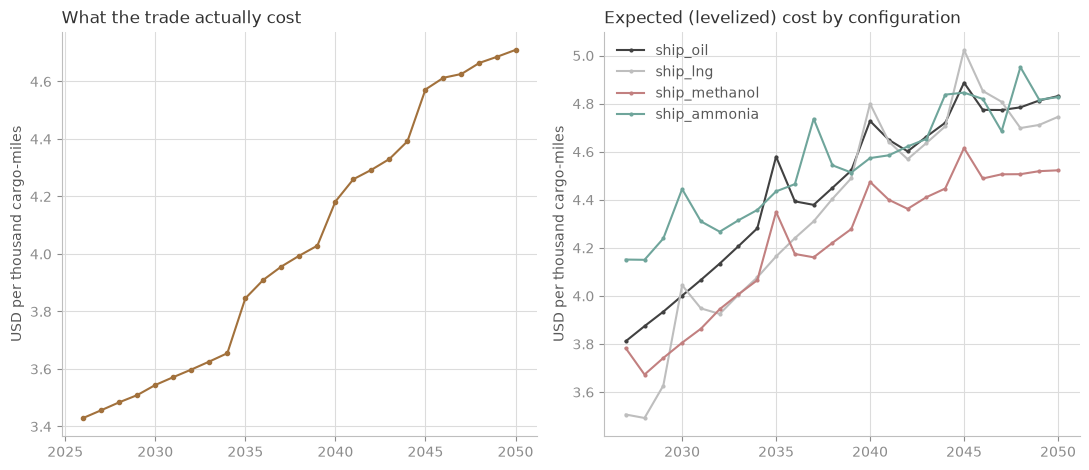

In [46]:
# @title Figure: what the trade cost
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.8))

# USD per THOUSAND cargo-miles, which is what Navigate's own
# fleet_investment_metric plot reports (divisor = 1./1e3) and what notebook 3
# uses. Per cargo-mile the numbers read 0.0046 - four leading zeros on an axis.
inst = 1e3 * np.asarray(copper_trade.profile.get_instantaneous_freight_rate(),
                        dtype=float)
ax1.plot(YEARS, inst, marker="o", ms=3, color=ORANGE)
ax1.set_title("What the trade actually cost", fontsize=12.5, color=INK, loc="left")
ax1.set_ylabel("USD per thousand cargo-miles", fontsize=10, color=SUBINK)

# What each configuration was expected to cost. This is the metric the
# newbuild choice is made on.
for name, vessel in base.nodes.vessels.items():
    ax2.plot(YEARS, 1e3 * np.asarray(vessel.profile.get_investment_freight_rate(),
                                     dtype=float),
             marker=".", ms=4, color=config_colour(name),
             label=config_label(name))
ax2.set_title("Expected (levelized) cost by configuration", fontsize=12.5, color=INK,
              loc="left")
ax2.set_ylabel("USD per thousand cargo-miles", fontsize=10, color=SUBINK)
ax2.legend(fontsize=10, frameon=False, labelcolor=SUBINK)

for ax in (ax1, ax2):
    ax.grid(color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TICK, labelsize=10)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)

fig.tight_layout()

print(f"instantaneous freight rate   {YEARS[0]}: {inst[0]:.2f}   "
      f"{YEARS[-1]}: {inst[-1]:.2f}   ({(inst[-1] / inst[0] - 1) * 100:+.0f}%)")
print()
print("In the right-hand panel, whichever configuration sits lowest in a given")
print("year is the one most likely to be ordered that year. That crossover is")
print("the mechanism behind the fuel mix in section 2.")
plt.show()

### Summary: who decided what

| Result you saw | Actor | Mechanism | Turn it with |
|---|---|---|---|
| Which fuel is bunkered where, each year | operators | **linear program**, all ships at once, cost minimising | prices, supply, regulation, `set_bunkering_inertia` |
| Sailing speed | operators | **cost-minimising speed**, energy valued at the LP shadow price | `MaximumSpeedChange`, `AllowSpeedManagement` |
| Efficiency technology fitted | owners | **logit on NPV**, energy saved valued at the LP shadow price | `TechnologySensitivity`, technology costs |
| Fuel conversion (retrofit) | owners | **logit on NPV** against ship CAPEX | `FuelConversionSensitivity`, conversion costs |
| Newbuild mix | owners | **two-axis logit** on levelized cost of transport, partly repeating last year's mix | `InterFuelSensitivity`, `IntraFuelSensitivity`, `Inertia` |
| Scrapping | owners | **age rule**, not a choice at all | `Lifetime`, `FixedScrapRate` |
| Which plants get built | fuel producers | **two-axis logit** on demand, then delivered cost, partly repeating last year's mix | `FuelDemandSensitivity`, `FuelCostSensitivity`, `Inertia` |
| Limits and penalty prices | regulator | **set in the deck**, no reaction to the fleet | the regulation files |
| Cargo carried | nobody | **exogenous**, no demand response | `TradeGrowth` |

In Navigate, owners and operators are represented together by one node, the
`Fleet`, which stands for the whole segment. The split above shows who would take
each decision in practice: operators run the ships, owners decide what ships
there are and what is fitted to them.


---

## Part 4: How much behaviour matters

The behavioural traits of the owners turn a cost gap into a share of the fleet (seen in Part 2 of this session). The next cells let you check how changing those traits could affect the results against the reference case:

- **`INTER_FUEL`** (`InterFuelSensitivity`): how sharply owners pick between fuel types when ordering a newbuild.
- **`FUEL_CONVERSION`** (`FuelConversionSensitivity`): how decisively owners retrofit the hulls they already own.
- **`TECHNOLOGY`** (`TechnologySensitivity`): how decisively owners fit
  efficiency technology.
- **`INERTIA`** (`Inertia` on the `Fleet`): the share of each year's newbuilds that
  copy the previous year's mix of ship types, whatever the costs. Only the rest
  is chosen on the scorecard.

Run the next cell to set up the sensitivity run.


In [47]:
# @title How much behaviour matters: the machinery (nothing to edit)
from _style import scen_colour

FOSSIL = {"fossil_fuel_oil", "liquefied_natural_gas"}


def both(*tweaks):
    """Apply several levers to one freshly parsed deck."""
    def tweak(m):
        for t in tweaks:
            t(m)
    return tweak


def sensitivity(attribute, odds):
    """Set one of the decision sensitivities outright.

    Unlike the price levers of Session 1 these are not multipliers: the value IS the odds
    ratio the deck would have carried, and what it is measured against depends
    on the metric. The fuel choice runs on LCOT, which is lower-is-better: the
    odds a fuel gets when its LCOT is 10% higher, so it sits below 1 and lower
    is sharper. Conversion and technology run on NPV: the odds an option gets
    when its NPV advantage equals 5% of the ship CAPEX, so they sit above 1 and
    higher is sharper.
    """
    def tweak(m):
        getattr(m.nodes.fleets["copper_trade"],
                f"set_{attribute}_sensitivity")(float(odds))
    return tweak


def inertia(share):
    """Set the fleet's newbuild Inertia outright: a share, not an odds ratio."""
    def tweak(m):
        m.nodes.fleets["copper_trade"].set_inertia(float(share))
    return tweak


# one lever each, named after the deck's own sensitivity, in the order Part 2
# listed them. Inter and intra are the two axes of the newbuild choice: which fuel
# type, then which ship design within that type.
# IntraFuelSensitivity is left out on purpose: this deck has a single design per
# fuel type, so each group has one member and no value changes anything. Part 3
# ("How Navigate decides") says what it means.
SENSITIVITIES = [
    ("INTER_FUEL", "inter_fuel", "newbuild mix, between fuel types"),
    ("FUEL_CONVERSION", "fuel_conversion", "whether to retrofit an existing hull"),
    ("TECHNOLOGY", "technology", "whether to fit efficiency technology"),
]
# where each one starts, so the lever cell can tell an edited value from the
# default without those defaults being typed in twice
REFERENCE_ODDS = {
    _attribute: float(getattr(base.nodes.fleets["copper_trade"],
                              f"{_attribute}_sensitivity").get())
    for _lever, _attribute, _what in SENSITIVITIES}
REFERENCE_INERTIA = float(base.nodes.fleets["copper_trade"].inertia.get())


def summarise(m):
    """One solve, read the way notebook 3 reads its fleets."""
    fleet = m.nodes.fleets["copper_trade"]
    years = years_of(m)
    wtw = np.nan_to_num(np.asarray(
        fleet.profile.get_total_equivalent_WTW(), dtype=float))

    energy, by_year = {}, {}
    for fuel, series in fleet.profile.get_consumed_energy().items():
        values = np.nan_to_num(np.asarray(series, dtype=float))
        if values.sum() <= 0:
            continue
        energy[fuel] = float(values.sum())
        by_year[fuel] = values
    grand = sum(energy.values())
    last_all = sum(float(v[-1]) for v in by_year.values())
    last_alt = sum(float(v[-1]) for f, v in by_year.items() if f not in FOSSIL)

    return {"years": years,
            "wtw": wtw / 1e3,                                  # kt CO2e per year
            "mix": {k: 100. * v / grand for k, v in energy.items()},
            # PJ per year, stacked in Navigate's own fuel order
            "by_year": {f: by_year[f] / 1e6 for f in fuel_sorted(by_year)},
            # USD per THOUSAND cargo-miles, as everywhere else in the workshop
            "freight": 1e3 * np.asarray(
                fleet.profile.get_instantaneous_freight_rate(), dtype=float),
            "alt_last": 100. * last_alt / last_all if last_all else 0.}


def plot_cases(cases):
    """Emissions, the fuel bunkered and the freight rate, one line or panel per case.

    `cases` maps a label ("reference", "your scenario") to what summarise()
    returns. The same figure shows the reference on its own and the
    comparison with your scenario. It is drawn at the width the page shows it,
    so the type stays readable: emissions and cost on top, the fuel mix below."""
    from matplotlib.ticker import MaxNLocator

    order = list(cases)
    TITLE, LABEL, TICK_SIZE = 12.5, 10.5, 10

    fig = plt.figure(figsize=(11, 8.2), constrained_layout=True)
    grid = fig.add_gridspec(2, len(order), height_ratios=[1, 1.05])
    # top row: emissions and cost, each half the width whatever the number of cases
    top_grid = grid[0, :].subgridspec(1, 2, wspace=0.08)
    axE = fig.add_subplot(top_grid[0, 0])
    axC = fig.add_subplot(top_grid[0, 1])
    # bottom row: one fuel-mix panel per case, on a shared scale so they read
    # against each other
    mix_axes = [fig.add_subplot(grid[1, 0])]
    mix_axes += [fig.add_subplot(grid[1, k], sharex=mix_axes[0], sharey=mix_axes[0])
                 for k in range(1, len(order))]

    for s in order:
        axE.plot(cases[s]["years"], cases[s]["wtw"], lw=2.4, marker=".", ms=7,
                 label=s, color=scen_colour(s))
    axE.set_title("Well-to-wake emissions", fontsize=TITLE, color=INK, loc="left")
    axE.set_ylabel("kt CO2e per year", fontsize=LABEL, color=SUBINK)
    axE.set_ylim(bottom=0.)
    if len(order) > 1:
        axE.legend(fontsize=LABEL, frameon=False, labelcolor=SUBINK, loc="lower left")

    # the two end labels land within a few cents of each other, so push the
    # lower series' label below its point rather than letting them overlap
    _high = max(order, key=lambda s: cases[s]["freight"][-1])
    for s in order:
        axC.plot(cases[s]["years"], cases[s]["freight"], lw=2.4, marker=".", ms=7,
                 label=s, color=scen_colour(s))
        axC.annotate(f"{cases[s]['freight'][-1]:,.2f}",
                     (cases[s]["years"][-1], cases[s]["freight"][-1]),
                     xytext=(-4, 8 if s == _high else -16),
                     textcoords="offset points", ha="right",
                     fontsize=LABEL, color=scen_colour(s), fontweight="bold")
    axC.set_title("Freight rate: what moving the cargo cost", fontsize=TITLE,
                  color=INK, loc="left")
    axC.set_ylabel("USD per thousand cargo-miles", fontsize=LABEL, color=SUBINK)
    axC.set_ylim(bottom=0.)
    # The rate carries what the fleet pays out and almost nothing it gets back:
    # Navigate has no rebate or subsidy funded from what a regulator collects,
    # so a scheme that recycled its revenue would sit lower than this.
    axC.text(.03, .04,
             "Carbon and compliance payments are in this rate." + chr(10)
             + "None of what regulators collect is paid back:" + chr(10)
             + "the model has no rebate or subsidy funded from it.",
             transform=axC.transAxes, fontsize=8.5, color=SUBINK,
             va="bottom", ha="left", linespacing=1.5)

    fuels = fuel_sorted({f for c in cases.values() for f in c["by_year"]})
    for ax, s in zip(mix_axes, order):
        stack = [cases[s]["by_year"].get(f, np.zeros(len(cases[s]["years"])))
                 for f in fuels]
        ax.stackplot(cases[s]["years"], *stack,
                     colors=[fuel_colour(f) for f in fuels],
                     labels=[fuel_label(f) for f in fuels], linewidth=0, alpha=.9)
        ax.set_title(f"Fuel bunkered, {s}", fontsize=TITLE, color=INK, loc="left")
        ax.margins(x=0)
    mix_axes[0].set_ylabel("PJ per year", fontsize=LABEL, color=SUBINK)
    fig.legend(*mix_axes[0].get_legend_handles_labels(), fontsize=LABEL,
               frameon=False, labelcolor=SUBINK, ncol=len(fuels),
               loc="outside lower center")

    for ax in (axE, axC, *mix_axes):
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(color=GRID, lw=.8)
        ax.set_axisbelow(True)
        ax.tick_params(colors=TICK, labelsize=TICK_SIZE, length=0)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color(AXIS)

    return fig


def plot_traits(values):
    """Part 2's share curves again, for the reference and for your values.

    `values` maps each attribute in SENSITIVITIES to the odds ratio to draw.
    share_by_cost, share_by_npv and style come from Part 2's figure cell.
    Technology is weighed the way a conversion is, NPV against 5% of the ship
    CAPEX, so it uses the same formula.
    """
    panels = [
        ("inter_fuel", share_by_cost, np.linspace(-0.3, 0.3, 121), 0.10,
         "Choosing a fuel type: INTER_FUEL",
         "how much more this fuel type costs than the other",
         "share of the newbuilds", "10 % dearer", "lower left"),
        ("fuel_conversion", share_by_npv, np.linspace(-0.15, 0.15, 121), 0.05,
         "Retrofitting a ship: FUEL_CONVERSION",
         "NPV of the conversion, as a share of the ship's CAPEX",
         "share of eligible ships that convert", "NPV worth 5 % of CAPEX",
         "upper left"),
        ("technology", share_by_npv, np.linspace(-0.15, 0.15, 121), 0.05,
         "Fitting a measure: TECHNOLOGY",
         "NPV of the measure, as a share of the ship's CAPEX",
         "share of ships that fit it", "NPV worth 5 % of CAPEX", "upper left"),
    ]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
    for ax, (attr, share, x, point, title, xlab, ylab, at, where) in zip(axes, panels):
        lines = [("reference", REFERENCE_ODDS[attr])]
        if values[attr] != REFERENCE_ODDS[attr]:
            lines.append(("your scenario", values[attr]))
        for s, odds in lines:
            ax.plot(x, share(x, odds), color=scen_colour(s), lw=2.4, zorder=3,
                    label=f"{s} ({odds:g}): {share(point, odds):.0%}")
            ax.plot(point, share(point, odds), "o", color=scen_colour(s), ms=7,
                    mec="white", mew=1.5, zorder=4)
        style(ax, title, xlab)
        ax.set_ylabel(ylab, fontsize=8, color=SUBINK)
        ax.legend(title=f"share at {at}", fontsize=8, title_fontsize=8,
                  frameon=False, labelcolor=SUBINK, loc=where)
    fig.tight_layout(w_pad=3)
    return fig


def run_your_scenario():
    """Draw the traits set in the YOUR SCENARIO cell, solve them, compare with the reference.

    Reads INTER_FUEL, FUEL_CONVERSION, TECHNOLOGY and INERTIA from the notebook
    when it is called, so the cell that sets them only has to call this.
    """
    BEHAVIOR = [("INTER_FUEL", INTER_FUEL, "inter_fuel"),
                ("FUEL_CONVERSION", FUEL_CONVERSION, "fuel_conversion"),
                ("TECHNOLOGY", TECHNOLOGY, "technology")]
    CHANGED = [(n, v) for n, v, a in BEHAVIOR if v != REFERENCE_ODDS[a]]
    TWEAKS = [sensitivity(a, v) for _n, v, a in BEHAVIOR if v != REFERENCE_ODDS[a]]
    # the inertia is a share rather than an odds ratio, so it has no curve below
    if INERTIA != REFERENCE_INERTIA:
        CHANGED.append(("INERTIA", INERTIA))
        TWEAKS.append(inertia(INERTIA))

    # what the traits you set mean, drawn before the solve because it needs none
    plot_traits({a: v for _n, v, a in BEHAVIOR})
    plt.show()

    if not TWEAKS:
        print("Every lever is still at its reference, so this would just re-solve it.")
        print("Change one of the numbers above and run this cell again.")
    else:
        print("solving your scenario:")
        for _name, _value in CHANGED:
            print(f"  {_name:16} {_value}")
        yours = run_case(both(*TWEAKS))
        you = summarise(yours)

        print(f"{chr(10)}  {'':32} {'reference':>11} {'yours':>11} {'change':>13}")
        for _label, _r, _y, _fmt, _pp in (
                (f"well-to-wake in {YEARS[-1]}, kt/yr",
                 ref["wtw"][-1], you["wtw"][-1], ",.0f", False),
                ("cumulative, kt", ref["wtw"].sum(), you["wtw"].sum(), ",.0f", False),
                # a share is already a percentage, so it moves in POINTS, not per cent
                (f"alternative fuels in {YEARS[-1]}, %",
                 ref["alt_last"], you["alt_last"], ".1f", True),
                (f"freight rate in {YEARS[-1]}, USD/k mile",
                 ref["freight"][-1], you["freight"][-1], ",.2f", False)):
            _change = (f"{_y - _r:+.1f} pp" if _pp
                       else f"{100. * (_y / _r - 1.):+.1f} %")
            print(f"  {_label:32} {_r:11{_fmt}} {_y:11{_fmt}} {_change:>13}")

        fig = plot_cases({"reference": ref, "your scenario": you})
        fig.suptitle("  " + ",  ".join(f"{n} = {v}" for n, v in CHANGED),
                     fontsize=11, color=SUBINK, x=0.01, ha="left")
        plt.show()

        print("what moved most, in percentage points of the fuel mix:")
        _delta = sorted(((you["mix"].get(f, 0.) - ref["mix"].get(f, 0.), f)
                         for f in set(ref["mix"]) | set(you["mix"])),
                        key=lambda d: -abs(d[0]))
        for _d, _f in _delta[:5]:
            print(f"  {fuel_label(_f):20} {_d:+6.1f} pp")


# `base` is the run Part 3 walked through, already solved, so the reference
# costs nothing here - only your scenario is re-solved, once, below.
ref = summarise(base)

print("the behavioural traits in the deck, as odds ratios")
for _lever, _attr, _what in SENSITIVITIES:
    print(f"  {_lever:16} {_what:38} {REFERENCE_ODDS[_attr]:5.2f}")
print("and the share of newbuilds that copy last year's mix")
print(f"  {'INERTIA':16} {'newbuild mix, repeating last year':38} {REFERENCE_INERTIA:5.2f}")


the behavioural traits in the deck, as odds ratios
  INTER_FUEL       newbuild mix, between fuel types        0.75
  FUEL_CONVERSION  whether to retrofit an existing hull    2.00
  TECHNOLOGY       whether to fit efficiency technology    2.00
and the share of newbuilds that copy last year's mix
  INERTIA          newbuild mix, repeating last year       0.60


Change the traits in the next cell and run it: it redraws the curves with your values, then solves your scenario and compares its results with the reference.

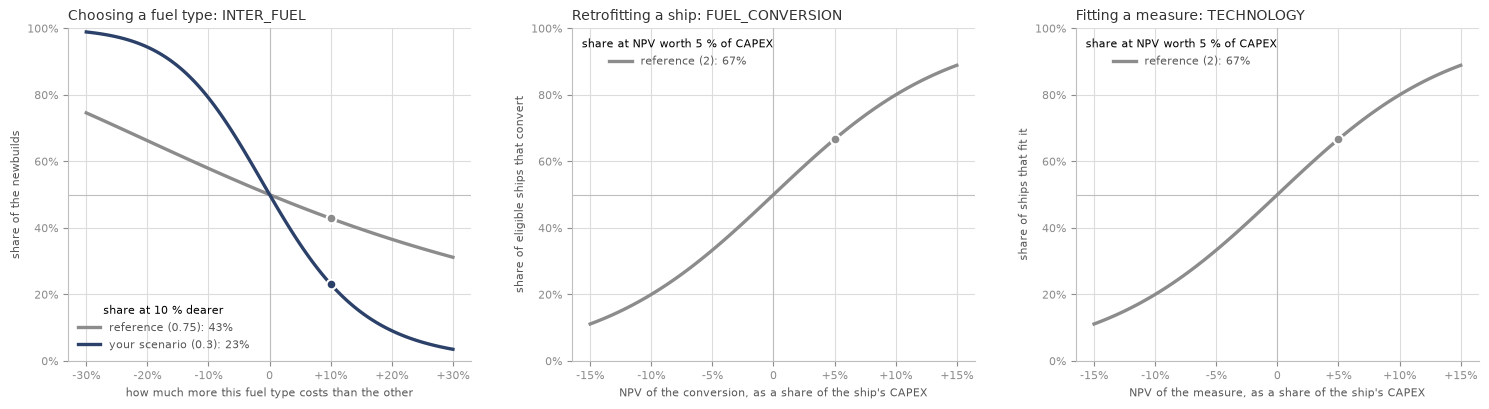

solving your scenario:
  INTER_FUEL       0.3



                                     reference       yours        change
  well-to-wake in 2050, kt/yr            3,265       3,406        +4.3 %
  cumulative, kt                       127,424     130,268        +2.2 %
  alternative fuels in 2050, %            43.3        40.6       -2.7 pp
  freight rate in 2050, USD/k mile        4.71        4.70        -0.3 %


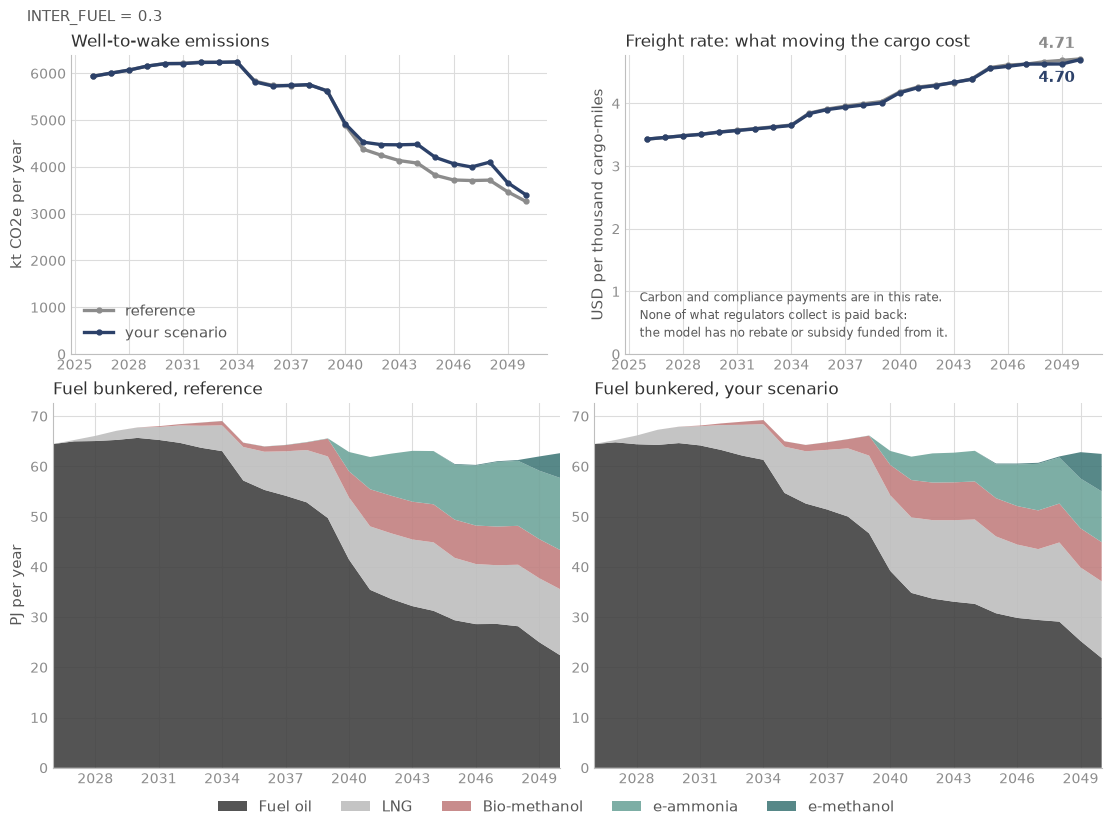

what moved most, in percentage points of the fuel mix:
  LNG                    +3.3 pp
  e-ammonia              -2.3 pp
  Fuel oil               -1.4 pp
  e-methanol             +0.3 pp
  Bio-methanol           +0.1 pp


In [48]:
# ===========================================================================
#  YOUR SCENARIO.  Set a trait, then run this cell: it redraws the curves,
#  solves your scenario (about a minute) and compares it with the reference.
#
#  As an example, INTER_FUEL is set to 0.3: owners pick between fuel types far
#  more sharply than the deck's 0.75. Set it back to 0.75 to start from the
#  reference.
#
#  BEHAVIOR. Not a price and not a rule: how the owners themselves decide, one
#  lever per decision. The first three are the odds ratios themselves, NOT
#  multipliers, and they start at what the deck says. Which way sharpens
#  differs by metric. INERTIA is a share of the newbuilds, from 0 to 1.
#
#                         suggested span   which way is sharper
INTER_FUEL      = 0.3   #  0.3 - 0.95     LOWER is sharper: LCOT, lower-is-better
FUEL_CONVERSION = 2.0   #  1.2 - 16       HIGHER is sharper: NPV against ship CAPEX
TECHNOLOGY      = 2.0   #  1.2 - 16       HIGHER is sharper: NPV on the measure
INERTIA         = 0.6   #  0 - 0.9        share of newbuilds copying last year's mix
# ===========================================================================

run_your_scenario()


## Workshop sessions

**Next: [Session 3: Run a global case](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/workshop/03-run-a-global-case.ipynb)**

Each link opens the notebook in Google Colab, in a fresh session, so run it
from the top.

1. [Run a simple case](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/workshop/01-run-a-simple-case.ipynb)
2. **Understand Navigate** (this session)
3. [Run a global case](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/workshop/03-run-a-global-case.ipynb)
4. [Run our reference scenarios](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/workshop/04-run-our-reference-scenarios.ipynb)
5. [Build your own case](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/workshop/05-build-your-own-case.ipynb)